# Quantum annealing evolution: bath relaxation and local SEAQT

An open-system model for quantum annealing: a qubit register coupled to a
fixed-temperature bath, driven by the real D-Wave QPU annealing
Hamiltonian. This notebook walks through the physics, validates it live,
and builds up from 1 qubit to 2 coupled qubits, using **two** dissipators:

1. **`bath_dissipator`** (sections 1-4) -- the whole composite system
   relaxes toward a single global Gibbs state.
2. **`local_seaqt_dissipator`** (sections 6-9) -- from Yamada, Kusaba,
   Li, von Spakovsky et al., arXiv:2404.05473v3 (eqs. 6, 7, 15); each
   qubit relaxes *locally*, coupled to the other only through their
   current reduced states.

**Physics common to both**

$$\dot\rho\big|_{\text{unitary}} = -\frac{i}{\hbar}[H(t), \rho]$$

with the D-Wave QPU Hamiltonian

$$H(s) = -\frac{A(s)}{2}\sum_i \sigma_x^{(i)} + \frac{B(s)}{2}\Big(\sum_i h_i \sigma_z^{(i)} + \sum_{i<j} J_{ij}\sigma_z^{(i)}\sigma_z^{(j)}\Big)$$

$A(s), B(s)$ read from the real QPU datasheet, $s=t/t_{\text{anneal}}\in[0,1]$.

**`bath_dissipator`** relaxes $\rho$ toward the Gibbs (canonical) state
$e^{-\beta H}/Z$ at bath inverse temperature $\beta$:

$$\dot\rho\big|_{\text{diss}} = -\frac{\beta}{2\tau}\{F(\rho,H,\beta),\rho\},
  \qquad F = (H-\langle H\rangle_\rho I) - \tfrac{1}{\beta}(S_{\mathrm{op}}-\langle S_{\mathrm{op}}\rangle_\rho I)$$

with $S_{\mathrm{op}}=-\ln\rho$. Both bracketed terms are "fluctuation
operators" with zero expectation in $\rho$ by construction, which is what
guarantees trace conservation with no extra projection step. Its 2nd-law
equivalent: the free energy $\Omega(\rho)=\langle H\rangle_\rho - S(\rho)/\beta$
decreases monotonically to its minimum at the Gibbs state.

**`local_seaqt_dissipator`** relaxes each qubit $J\in\{A,B\}$ locally:

$$\dot{\rho}\vert_{\text{diss}} = -\sum_{J = 1}^{M} \frac{1}{\tau_J}\hat{D}_J\otimes\hat{\rho}_{\bar{J}}, \qquad \hat{D}_J = \hat{\rho}_J \ln \hat{\rho}_J - \beta_R \langle f \rangle_J \hat{\rho}_J +\frac{1}{2} \beta_R \{ \hat{H}_J , \hat{\rho}_J\}$$


with $\rho_J=\mathrm{Tr}_{\bar J} (\rho)$, $H_J$ the "locally perceived" Hamiltonian
(traced over the other qubit, weighted by its current state). `Tr(D_J)=0`
exactly by construction (see section 9).

See `README.md` for the full derivation and sign/unit conventions.

> **Units note (2026-09-19).** The D-Wave schedule columns are `A(s)/h` and `B(s)/h` in GHz -- energy divided by Planck's $h$, a *linear* frequency (see the "About" sheet of the schedule export). The Schrödinger equation with $\hbar=1$ and $t$ in ns needs an *angular* frequency, so the Hamiltonian used throughout is $H_{\mathrm{ang}}=2\pi\,H_{\mathrm{GHz}}$ (rad/ns), consistent with $\beta=\hbar/(k_BT)$ in ns. `seaqt.dwave` now applies the $2\pi$ (`freq_to_angular`), and King et al.'s $b=\Gamma/\hbar/(\dots)$ carries it too.
>
> **All sections have been recomputed with this convention.** What changed, in short:
>
> - The first version of sections 2-15 was, dimensionally, the corrected problem with every time divided by $2\pi$ and a bath $2\pi$ warmer -- 94 mK instead of the labelled 15 mK. This is exact and was checked numerically: the equivalent problem reproduces that version's 3-qubit minimum eigenvalues ($-3.2\times10^{-4}$, $-3.4\times10^{-5}$), its 2-qubit one ($-6.8\times10^{-2}$) and section 4's table.
> - At the **physical** parameters (15 mK, 5-100 ns) a single qubit anneals to $P\approx1$ everywhere (section 3, left panel) and the moving-target effect of section 4 disappears; it survives in the equivalent, warm and fast, problem shown next to it.
> - The **local SEAQT dissipator is only positivity-safe for $\tau\gtrsim300$ ns at 15 mK** (20 ns anneal) and diverges for $\tau\lesssim10$ ns (sections 9-10). Sections 6-15 therefore use a *warm demonstration bath* (`BETA_DEMO`, 94 mK), where the dissipator does visible work; the cold-bath thresholds are given in sections 9-10 and in the timing table of section 14.
> - The 20 ns anneal is now adiabatic, which changes the ICE-noise sections (11, 13): single realizations are far more skewed (std 0.33 at N=2 and 0.23 at N=4, against 0.06 and 0.05 before).
> - The Landau-Zener check of section 15 is unchanged (ratio 0.993) but, being a ratio of two quantities that carry the same $2\pi$, it cannot detect it.


In [ ]:
import os, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def _find_repo_root(start: Path) -> Path:
    """Walk upward from `start` until we find THIS repo (identified by
    seaqt/local_seaqt.py, a file unique to this project) -- robust to
    whatever directory the Jupyter kernel happens to use as its cwd.
    VSCode's Jupyter extension commonly uses the workspace root rather than
    the notebook's own folder, so `os.getcwd() + "/.."` isn't reliable."""
    for candidate in [start, *start.parents]:
        if (candidate / "seaqt" / "local_seaqt.py").exists():
            return candidate
    raise RuntimeError(
        "Could not locate the SEAQT-quantum-annealing-evolution repo root "
        f"above {start} -- expected to find seaqt/local_seaqt.py in some "
        "parent directory."
    )


REPO_ROOT = _find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import seaqt as _seaqt_probe
_seaqt_probe_path = Path(_seaqt_probe.__file__).resolve()
if REPO_ROOT not in _seaqt_probe_path.parents:
    raise RuntimeError(
        f"'seaqt' resolved to {_seaqt_probe_path}, NOT this repo "
        f"({REPO_ROOT}) -- most likely a same-named 'seaqt' package from a "
        "different project, already cached in this kernel's sys.modules "
        "from an earlier import in the same session. Restart the kernel "
        "(Kernel > Restart) and re-run this notebook from the top."
    )
del _seaqt_probe, _seaqt_probe_path

from seaqt import bath_dissipator, entropy, evolve, free_energy, free_energy_operator, gibbs_state, hermitize, population_distribution
from seaqt.local_seaqt import local_seaqt_dissipator, locally_perceived_operator, reduced_state, _subsystem_dissipator
from seaqt.local_seaqt_n import local_seaqt_dissipator_n
from seaqt.operators import basis_labels, ising_hamiltonian, sigma_x, sigma_z
from seaqt.dwave import load_schedule, hamiltonian_1qubit, hamiltonian_nqubit, beta_from_kelvin

SCHEDULE_PATH = (
    r"C:\Users\andre\OneDrive\Documentos\Maestría\Julich\codigos"
    r"\09-1265A-C_Advantage_system5_3_annealing_schedule.xlsx"
)

plt.rcParams["figure.dpi"] = 110
np.set_printoptions(precision=4, suppress=True)
print(f"Setup OK. seaqt loaded from: {REPO_ROOT}")


Setup OK. seaqt loaded from: c:\Users\andre\OneDrive\Documentos\GitHub\SEAQT-quantum-annealing-evolution


## 1. Physics validation, live

Rather than just trusting the tests, compute the dissipator directly and
check the invariants it claims to satisfy: trace conservation, and that it
vanishes exactly at the Gibbs equilibrium state.

In [3]:
H_demo = 0.5 * sigma_z + 0.3 * sigma_x
beta_demo = 1.5

rho_eq = gibbs_state(H_demo, beta_demo)
D_at_eq = bath_dissipator(rho_eq, H_demo, beta_demo, tau=1.0)
print("Dissipator at the Gibbs state (should be ~0):")
print(D_at_eq)
print(f"max|D| = {np.max(np.abs(D_at_eq)):.3e}")

rho_away = np.array([[0.6, 0.15 - 0.1j], [0.15 + 0.1j, 0.4]], dtype=complex)
D_away = bath_dissipator(rho_away, H_demo, beta_demo, tau=1.0)
print(f"\nAway from equilibrium, max|D| = {np.max(np.abs(D_away)):.3e} (nonzero, as expected)")
print(f"Tr(D)   = {np.trace(D_away):.3e}  (want 0)")

Dissipator at the Gibbs state (should be ~0):
[[-0.+0.j -0.+0.j]
 [-0.+0.j  0.+0.j]]
max|D| = 1.938e-16

Away from equilibrium, max|D| = 4.348e-01 (nonzero, as expected)
Tr(D)   = 0.000e+00+0.000e+00j  (want 0)


## 2. One qubit -- real D-Wave schedule + bath relaxation

A simpler stepping stone before 2 qubits: single qubit, real QPU schedule,
relaxing toward a fixed-temperature bath. Note D-Wave's sign convention:
no leading minus on the $B(s)$ term, so the ground state is $|0\rangle$
for $h_1<0$.

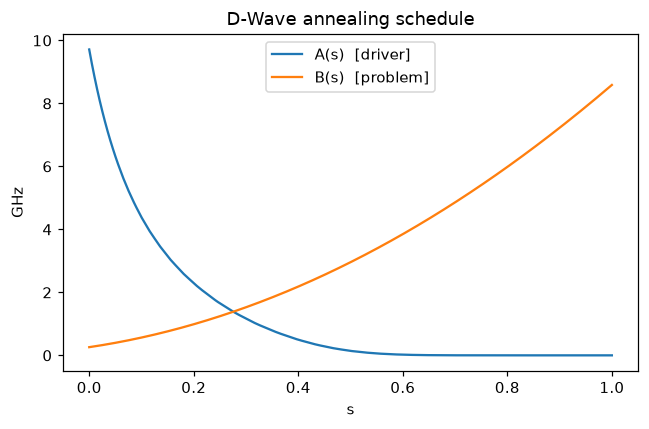

In [4]:
schedule = load_schedule(SCHEDULE_PATH)
s_grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(s_grid, schedule.A(s_grid), label="A(s)  [driver]")
ax.plot(s_grid, schedule.B(s_grid), label="B(s)  [problem]")
ax.set_xlabel("s"); ax.set_ylabel("GHz"); ax.legend(); ax.set_title("D-Wave annealing schedule")
fig.tight_layout(); plt.show()

beta (15 mK) = 0.5092 ns
             tau=2: final P(|0>)=1.0000, final entropy=0.0000, final Omega=-26.9748
            tau=10: final P(|0>)=1.0000, final entropy=0.0000, final Omega=-26.9748
 tau=inf (unitary): final P(|0>)=0.9998, final entropy=0.0000, final Omega=-26.9654


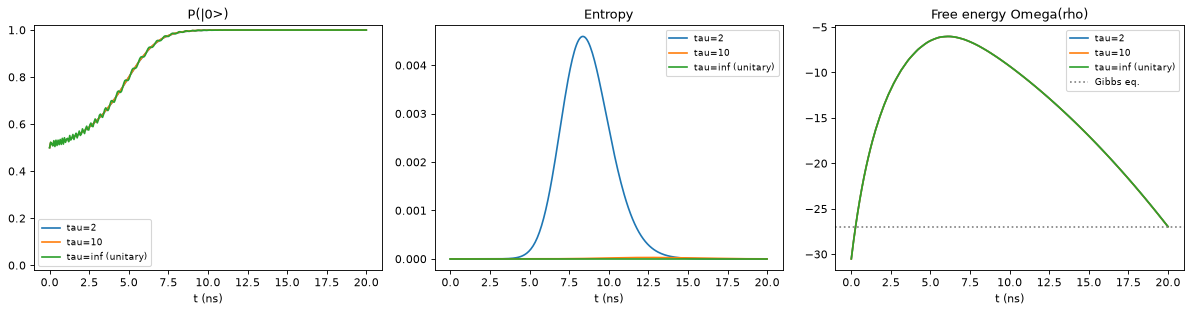

In [31]:
def run_1q_bath(H, t_anneal, tau, beta, n_points=300):
    rho0 = np.array([[0.5, 0.5], [0.5, 0.5]], dtype=complex)  # |+><+| (driver ground state)
    if np.isfinite(tau):
        diss = lambda t, rho, h: bath_dissipator(rho, h, beta, tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    p0 = np.array([np.real(r[0, 0]) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta) for t, r in zip(res.t, res.rho)])
    return res.t, p0, ent, omega

t_anneal_1q = 20.0
H_1q = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal_1q)
beta_bath = beta_from_kelvin(0.015)  # 15 mK
print(f"beta (15 mK) = {beta_bath:.4f} ns")

taus_1q = [2.0, 10.0, np.inf]
labels = {2.0: "tau=2", 10.0: "tau=10", np.inf: "tau=inf (unitary)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for tau in taus_1q:
    t, p0, ent, omega = run_1q_bath(H_1q, t_anneal_1q, tau, beta_bath)
    axes[0].plot(t, p0, label=labels[tau])
    axes[1].plot(t, ent, label=labels[tau])
    axes[2].plot(t, omega, label=labels[tau])
    print(f"{labels[tau]:>18}: final P(|0>)={p0[-1]:.4f}, final entropy={ent[-1]:.4f}, final Omega={omega[-1]:.4f}")
h1_final = H_1q(t_anneal_1q)
omega_eq_1q = free_energy(gibbs_state(h1_final, beta_bath), h1_final, beta_bath)
axes[2].axhline(omega_eq_1q, color="gray", linestyle=":", label="Gibbs eq.")
axes[0].set_title("P(|0>)"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
axes[2].set_title("Free energy Omega(rho)"); axes[2].legend(fontsize=8)
for a in axes: a.set_xlabel("t (ns)")
fig.tight_layout(); plt.show()

## 3. $t_{\text{anneal}} \times \tau$ sweep (1 qubit, bath, real D-Wave schedule)

Since the bath's target is the Gibbs state rather than a fixed pure state,
dissipation doesn't only compete with reaching the answer the way a
fixed-energy dissipator would -- sweep across anneal time and relaxation
rate to see where it helps or hurts.

**Units note.** With the corrected units ($H_{\mathrm{ang}}=2\pi H_{\mathrm{GHz}}$) the left panel below
(physical parameters: 15 mK bath, $t_{\text{anneal}}$ = 5, 20, 100 ns) is flat: at 15 mK the bath's Gibbs
target is essentially the pure ground state for most of the anneal, and even the 5 ns anneal is adiabatic
enough that every point lands at $P(|0\rangle)\approx1$. The right panel is the dimensionally equivalent
problem of the first version of this notebook -- which used the schedule's GHz values as angular
frequencies, i.e. $H\to H/2\pi$, the same as dividing every time by $2\pi$ and warming the bath by $2\pi$
(94 mK) -- and is where the effect studied next lives. (The equivalence is exact: it reproduces the first
version's numbers, e.g. section 4's table, to four decimals.)


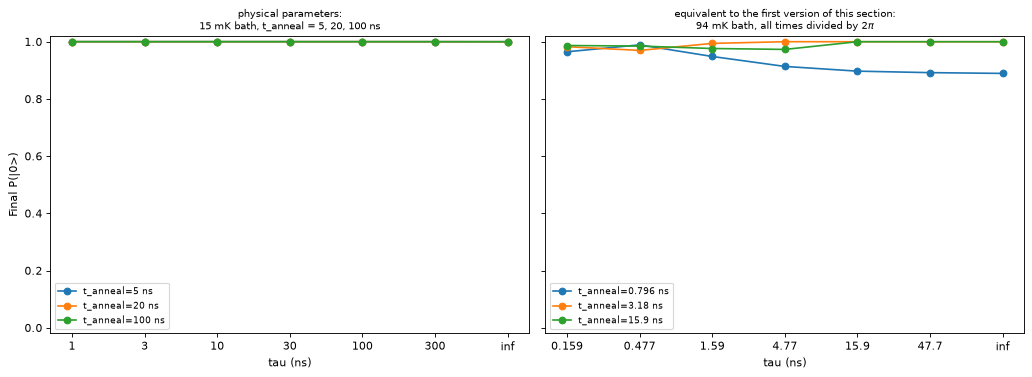

physical parameters: final P(|0>) stays within [0.9998, 1.0000] over the whole grid
equivalent problem, fastest anneal: unitary limit 0.8890; best finite tau 0.9889 (tau = 0.477 ns)
-> for a fast (diabatic) anneal, strong dissipation can reach HIGHER fidelity than the pure unitary limit,
   unlike a fixed-energy dissipator, whose target is a pure state and so can only compete with reaching one.


In [32]:
tau_sweep = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0, np.inf]

# Two versions of the same sweep.
#  Left : the physical parameters (15 mK bath, anneal times 5/20/100 ns).
#  Right: the dimensionally equivalent problem of the FIRST version of this notebook, which used the
#         schedule's GHz values as if they were angular frequencies. H -> H/(2*pi) is the same problem as
#         dividing every time (t_anneal, tau) by 2*pi and warming the bath by 2*pi (only beta*H and
#         t/tau matter): kT = 2*pi * 15 mK ~ 94 mK.
EQ = 2 * np.pi
panels = [("physical parameters:\n15 mK bath, t_anneal = 5, 20, 100 ns", beta_bath, 1.0),
          ("equivalent to the first version of this section:\n94 mK bath, all times divided by 2$\\pi$", beta_bath / EQ, 1 / EQ)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
grid = {}
for ax, (title, beta_sw, scale) in zip(axes, panels):
    for t_anneal_nom in [5.0, 20.0, 100.0]:
        t_anneal = t_anneal_nom * scale
        H_sweep = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal)
        finals = [run_1q_bath(H_sweep, t_anneal, tau * scale, beta_sw, n_points=120)[1][-1] for tau in tau_sweep]
        grid[(scale, t_anneal_nom)] = finals
        ax.plot([f"{t * scale:.3g}" if np.isfinite(t) else "inf" for t in tau_sweep], finals, marker="o",
                label=f"t_anneal={t_anneal:.3g} ns")
    ax.set_xlabel("tau (ns)")
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=8)
    ax.set_ylim(-0.02, 1.02)
axes[0].set_ylabel("Final P(|0>)")
fig.tight_layout(); plt.show()

phys = np.array([v for (s, _), v in grid.items() if s == 1.0])
fast_eq = grid[(1 / EQ, 5.0)]
print(f"physical parameters: final P(|0>) stays within [{phys.min():.4f}, {phys.max():.4f}] over the whole grid")
print(f"equivalent problem, fastest anneal: unitary limit {fast_eq[-1]:.4f}; best finite tau {max(fast_eq[:-1]):.4f} "
      f"(tau = {tau_sweep[int(np.argmax(fast_eq[:-1]))] / EQ:.3g} ns)")
print("-> for a fast (diabatic) anneal, strong dissipation can reach HIGHER fidelity than the pure unitary limit,")
print("   unlike a fixed-energy dissipator, whose target is a pure state and so can only compete with reaching one.")


## 4. Why can a *shorter* anneal beat a longer one at the same tau? A moving target

**Units note.** This mechanism needs a bath warm enough that its Gibbs target is not the pure ground
state, and an anneal fast enough for the unitary part to overshoot that target. With the corrected units
that is the *equivalent problem* of section 3 (right panel): a 94 mK bath, anneal times 0.80 / 3.18 /
15.9 ns (the 5 / 20 / 100 ns of the first version divided by $2\pi$) and $\tau=4.77$ ns. At the
physical 15 mK and $t_{\text{anneal}}\ge5$ ns the trajectories simply sit on the target (section 3, left
panel), so there is nothing to explain there.

Section 3's sweep (right panel) showed something that looks backwards at first: the 3.18 ns anneal can end
up with a *higher* final `P(|0>)` than the 15.9 ns anneal at the same `tau`. The resolution is that the
unitary part and the dissipative part of the dynamics are chasing two genuinely different targets:

* **annealing (unitary)** pursues the *instantaneous ground state* of
  $H(t)$ -- a pure state, ideal target $P(|0\rangle)=1$;
* **`bath_dissipator`** pursues the *instantaneous Gibbs state* of that
  same $H(t)$ at the bath's temperature -- a mixed (thermal) state, whose
  $P(|0\rangle)$ rises with $s=t/t_{\text{anneal}}$ but only reaches
  $\approx 0.9875$ at $s=1$ for this schedule/temperature, never $1$,
  because the bath temperature is finite (residual thermal population in
  the excited state, however small).

"Same `tau`" is a fixed *rate* toward that moving target, not a fixed
*outcome* -- a longer anneal gives the bath strictly more absolute time to
pull the trajectory toward wherever that target currently sits, which for
most of the schedule is *below* its final value.


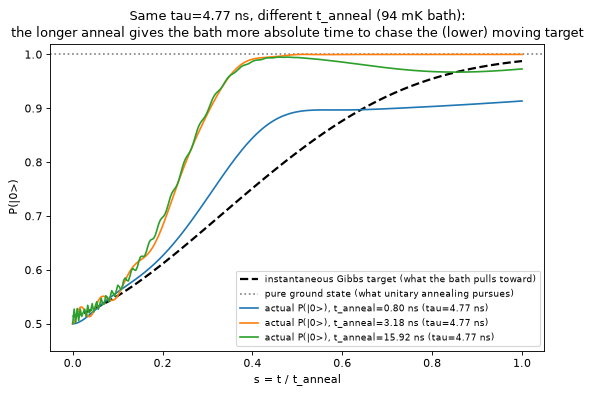

Bath's true final target at s=1: P(|0>) = 0.9875  (not 1.0 -- finite bath temperature)

    s | instant-Gibbs target | actual, t_anneal=0.80 | actual, t_anneal=3.18 | actual, t_anneal=15.92
 0.00 |               0.5132 |              0.5000 |               0.5000 |                0.5000
 0.25 |               0.6450 |              0.6761 |               0.7979 |                0.8057
 0.50 |               0.8184 |              0.8937 |               0.9998 |                0.9941
 0.75 |               0.9401 |              0.9011 |               0.9999 |                0.9708
 0.90 |               0.9754 |              0.9080 |               0.9999 |                0.9677
 1.00 |               0.9875 |              0.9135 |               0.9999 |                0.9729


In [33]:
# The moving-target mechanism needs (i) a bath warm enough that its Gibbs target is not the pure ground state
# and (ii) an anneal fast enough for the unitary part to overshoot that target. With the corrected units that is
# the dimensionally equivalent problem of the first version of this section (see section 3): a 94 mK bath and every
# time divided by 2*pi. (At 15 mK and t_anneal >= 5 ns the curves simply sit on the target -- section 3, left.)
EQ = 2 * np.pi
beta_eq = beta_bath / EQ
T_MT = [5.0 / EQ, 20.0 / EQ, 100.0 / EQ]  # t_anneal of the three trajectories (ns)

H_ref_s = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=1.0)  # t_anneal=1 -> t IS s directly
s_grid_target = np.linspace(0, 1, 100)
gibbs_target_curve = np.array([gibbs_state(H_ref_s(s), beta_eq)[0, 0].real for s in s_grid_target])

tau_mt = 30.0 / EQ
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(s_grid_target, gibbs_target_curve, "k--", lw=2,
        label="instantaneous Gibbs target (what the bath pulls toward)")
ax.axhline(1.0, color="gray", linestyle=":",
           label="pure ground state (what unitary annealing pursues)")

p0_mt = {}
for t_anneal_mt in T_MT:
    H_mt = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal_mt)
    t, p0, ent, omega = run_1q_bath(H_mt, t_anneal_mt, tau_mt, beta_eq, n_points=300)
    p0_mt[t_anneal_mt] = p0
    ax.plot(t / t_anneal_mt, p0, label=f"actual P(|0>), t_anneal={t_anneal_mt:.2f} ns (tau={tau_mt:.2f} ns)")

ax.set_xlabel("s = t / t_anneal"); ax.set_ylabel("P(|0>)")
ax.set_title(f"Same tau={tau_mt:.2f} ns, different t_anneal (94 mK bath):\nthe longer anneal gives the bath more absolute time to chase the (lower) moving target")
ax.legend(fontsize=8, loc="lower right"); ax.set_ylim(0.45, 1.02)
fig.tight_layout(); plt.show()

print(f"Bath's true final target at s=1: P(|0>) = {gibbs_target_curve[-1]:.4f}  (not 1.0 -- finite bath temperature)")
print()
print(f"{'s':>5} | {'instant-Gibbs target':>20} | {'actual, t_anneal=%.2f' % T_MT[0]:>19} | {'actual, t_anneal=%.2f' % T_MT[1]:>20} | {'actual, t_anneal=%.2f' % T_MT[2]:>21}")
for s_chk in [0.0, 0.25, 0.5, 0.75, 0.9, 1.0]:
    row = []
    for tm in T_MT:
        arr = p0_mt[tm]
        row.append(arr[int(round(s_chk * (len(arr) - 1)))])
    target_val = gibbs_state(H_ref_s(s_chk), beta_eq)[0, 0].real
    print(f"{s_chk:5.2f} | {target_val:20.4f} | {row[0]:19.4f} | {row[1]:20.4f} | {row[2]:21.4f}")


Reading the plot and table together: all three trajectories race
ahead of the instantaneous Gibbs target early on (the unitary/adiabatic
part wins that phase, since the minimum gap for this problem closes
around $s\approx 0.3$-$0.5$). Past that point, the 3.18 ns anneal only has
a couple of nanoseconds left -- well under one relaxation time at
`tau=4.77` ns, not enough for the bath to noticeably pull the
"overshoot" back down before the anneal ends. The 15.9 ns anneal has ~5x more
absolute time in that same window -- enough for the bath to visibly drag
`P(|0>)` back down toward the still-rising-but-lower target, and it
doesn't fully recover by $s=1$ (0.9729, versus 0.9999 for the 3.18 ns anneal).

The 0.80 ns anneal looks different again: it never gets far enough ahead of the
target to have an "overshoot" to lose in the first place (`0.9135` at
$s=1$) -- but comparing it to its *own* unitary-only limit (section 3, right
panel: 0.889) shows `tau=4.77` is still net *helping* it, not hurting, which
is the opposite direction from the other two.

This is why the effect is strongest for `tau` comparable to the
*leftover* time after the gap closes, not for very strong dissipation
(locked to the target from the start, so there is no overshoot to lose)
or very weak dissipation (negligible pull either way).


## 5. Extending to N qubits

`seaqt.operators` builds Pauli operators on any qubit of an $n$-qubit
register via Kronecker products, and assembles the (D-Wave-convention)
Ising Hamiltonian. `bath_dissipator` and `evolve` never assumed 2x2 --
they work unmodified for any Hilbert-space dimension.

In [6]:
H2 = ising_hamiltonian(2, h=[0.6, -0.4], J={(0, 1): 0.5}, A=1.0, B=0.7)
print("2-qubit Hamiltonian, shape", H2.shape, ", Hermitian:", np.allclose(H2, H2.conj().T))
print(H2.real)

rho2 = hermitize(np.eye(4, dtype=complex) / 4 + 0.05 * np.random.default_rng(0).normal(size=(4, 4)))
rho2 /= np.trace(rho2).real
D2 = bath_dissipator(rho2, H2, beta=1.0, tau=1.0)
print(f"\n2-qubit bath dissipator: Tr(D)={np.trace(D2):.2e}  (want 0)")

2-qubit Hamiltonian, shape (4, 4) , Hermitian: True
[[ 0.245 -0.5   -0.5    0.   ]
 [-0.5    0.175  0.    -0.5  ]
 [-0.5    0.    -0.525 -0.5  ]
 [ 0.    -0.5   -0.5    0.105]]

2-qubit bath dissipator: Tr(D)=-1.11e-16+0.00e+00j  (want 0)


## 6. Two qubits -- real D-Wave schedule + local SEAQT relaxation

The main result this repo is built around: two coupled qubits, the real
QPU annealing schedule, each qubit relaxing *locally* via
`local_seaqt_dissipator` (section 9 has the full derivation/validation).

**Bath and units.** With the corrected units, the demonstrations of sections 6-15 use a *warm* bath,
$kT=2\pi\times15\,\mathrm{mK}\approx94$ mK (`BETA_DEMO` $=\beta/2\pi=0.081$ ns), not the physical 15 mK.
Two reasons. At the physical temperature the local dissipator is only well behaved for
$\tau\gtrsim300$ ns and diverges for $\tau\lesssim10$ ns (sections 9-10), so the regime worth
demonstrating -- dissipation acting on the anneal timescale -- cannot be shown there. And 94 mK is,
dimensionally, the bath the first version of this notebook was actually simulating (its $H$ was $2\pi$
too small), so the qualitative findings of sections 6-13 can be compared with it. The 20 ns anneal is
now adiabatic -- the unitary curve ends at $P=1.0000$ -- so the visible effect of the dissipator here is
thermal excitation of the final state, not help.

The initial state is a slightly-thermalized driver state
(`gibbs_state(H(0), beta_init)`, `beta_init` large enough to be
numerically indistinguishable from the exact pure ground state) -- this
is a convention carried over from the `bath_dissipator` demos, not a
numerical necessity here: section 8 confirms `local_seaqt_dissipator`
handles pure states cleanly (including a maximally *entangled* pure
state, the genuinely analogous danger for this dissipator), and swapping
in the exact pure state changes nothing at the precision shown below. The
linear bias $h=[0.6,-0.4]$ is asymmetric simply so the problem has a
unique ground state, making $P(\text{ground})$ a meaningful quantity to
plot directly -- section 7 runs the same setup with the symmetric,
genuinely undecided $h=[0,0]$ instead. `tau_A=tau_B \ge 10` ns is used
here deliberately: section 9 shows positivity of $\rho$ can be violated
for smaller, more aggressive `tau` with this schedule.


Ground state: |10>, gap=48.5546
      tau_A=tau_B=10: final distribution P(|00>)=0.0151, P(|01>)=0.0235, P(|10>)=0.9234, P(|11>)=0.0380
      tau_A=tau_B=30: final distribution P(|00>)=0.0054, P(|01>)=0.0038, P(|10>)=0.9796, P(|11>)=0.0112
tau = inf (unitary only): final distribution P(|00>)=0.0000, P(|01>)=0.0000, P(|10>)=1.0000, P(|11>)=0.0000


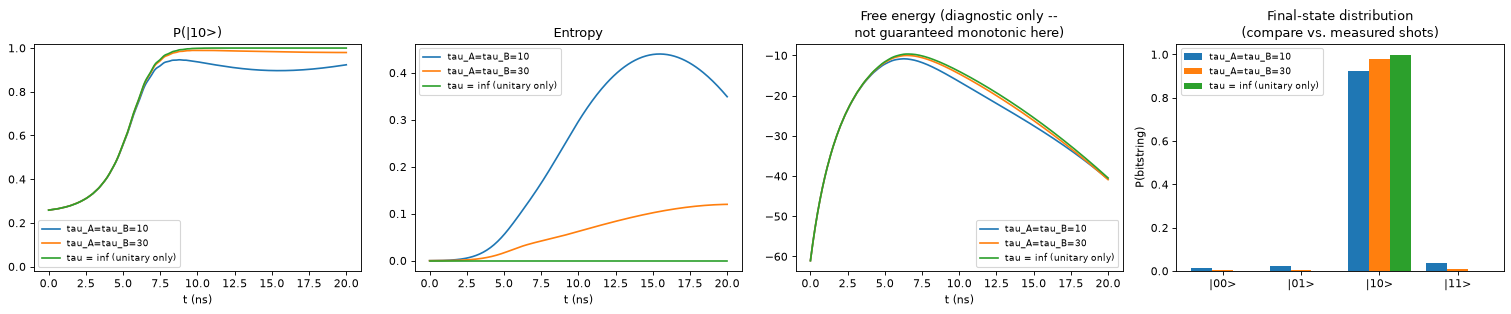

In [34]:
H_BIAS_2Q = [0.6, -0.4]
J12 = 0.5
BETA_INIT = 5.0
# Bath for the local-SEAQT demonstrations of sections 6-15: a WARM bath, kT = 2*pi * 15 mK ~ 94 mK
# (beta = beta_bath / (2*pi)). Dimensionally this is the bath the first version of this notebook was actually
# simulating; at the physical 15 mK the local dissipator is unstable for tau <~ 100 ns (sections 9 and 10).
BETA_DEMO = beta_bath / (2 * np.pi)

def run_2q_local_seaqt(H, t_anneal, tau, beta_r, n_points=250):
    rho0 = gibbs_state(H(0.0), BETA_INIT)
    if np.isfinite(tau):
        diss = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r, tau_a=tau, tau_b=tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    _, v = np.linalg.eigh(H(t_anneal))
    ground_vec = v[:, 0]
    p_ground = np.array([np.real(ground_vec.conj() @ r @ ground_vec) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta_r) for t, r in zip(res.t, res.rho)])
    final_dist = population_distribution(res.rho[-1])
    return res.t, p_ground, ent, omega, final_dist

t_anneal_2q = 20.0
H_2q = hamiltonian_nqubit(schedule, h=H_BIAS_2Q, J={(0, 1): J12}, t_anneal=t_anneal_2q)
h2_final = H_2q(t_anneal_2q)
w2, v2 = np.linalg.eigh(h2_final)
labels_bits_2q = basis_labels(2)
ground_idx_2q = int(np.argmax(np.abs(v2[:, 0])))
print(f"Ground state: {labels_bits_2q[ground_idx_2q]}, gap={w2[1]-w2[0]:.4f}")

taus_2q = [10.0, 30.0, np.inf]
labels_2q = {10.0: "tau_A=tau_B=10", 30.0: "tau_A=tau_B=30", np.inf: "tau = inf (unitary only)"}
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
final_dists_2q = {}
for tau in taus_2q:
    t, p_ground, ent, omega, final_dist = run_2q_local_seaqt(H_2q, t_anneal_2q, tau, BETA_DEMO)
    final_dists_2q[tau] = final_dist
    axes[0].plot(t, p_ground, label=labels_2q[tau])
    axes[1].plot(t, ent, label=labels_2q[tau])
    axes[2].plot(t, omega, label=labels_2q[tau])
    print(f"{labels_2q[tau]:>20}: final distribution " +
          ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_2q, final_dist)))
axes[0].set_title(f"P({labels_bits_2q[ground_idx_2q]})"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
# Note: unlike bath_dissipator, local_seaqt_dissipator does NOT guarantee Omega
# decreases monotonically toward the global Gibbs state -- diagnostic only.
axes[2].set_title("Free energy (diagnostic only --\nnot guaranteed monotonic here)"); axes[2].legend(fontsize=8)
for a in axes[:3]: a.set_xlabel("t (ns)")

# Final-state distribution, grouped by tau -- the panel to overlay against a
# measured bitstring/shot histogram from real hardware (rho is represented in
# the computational/Z basis throughout, the same basis a QPU measures in).
x = np.arange(len(labels_bits_2q))
width = 0.8 / len(taus_2q)
for i, tau in enumerate(taus_2q):
    axes[3].bar(x + (i - (len(taus_2q) - 1) / 2) * width, final_dists_2q[tau], width, label=labels_2q[tau])
axes[3].set_xticks(x); axes[3].set_xticklabels(labels_bits_2q)
axes[3].set_ylabel("P(bitstring)"); axes[3].set_title("Final-state distribution\n(compare vs. measured shots)")
axes[3].legend(fontsize=8)

fig.tight_layout(); plt.show()

## 7. What if there's no bias at all? A genuinely undecided problem (`h=[0,0]`)

Section 6's problem was deliberately asymmetric (`h=[0.6,-0.4]`) so the
ground state is unique. What does the exact same real-schedule simulation
predict if the linear bias is removed entirely, keeping only the
antiferromagnetic coupling `J12=0.5`? The coupling still favors
*anti-aligned* qubits over aligned ones, but nothing is left to break the
tie between the two anti-aligned bitstrings ($|01\rangle$ vs.
$|10\rangle$) -- a genuinely *undecided* problem, not just a small-gap
one.

Final H eigenvalues: [-13.4874 -13.4874  13.4874  13.4874]  -- an exactly two-fold degenerate ground doublet
eigh's 'ground eigenvector': [-0.     -0.9967  0.0807 -0.    ]
  -- an ARBITRARY superposition of |01> and |10>, not either bitstring individually.
  P(ground) tracked against THIS vector isn't physically meaningful here -- the
  final-distribution bar chart below is the diagnostic that actually makes sense.

      tau_A=tau_B=10: P(|00>)=0.0246, P(|01>)=0.4754, P(|10>)=0.4754, P(|11>)=0.0246
      tau_A=tau_B=30: P(|00>)=0.0077, P(|01>)=0.4923, P(|10>)=0.4923, P(|11>)=0.0077
tau = inf (unitary only): P(|00>)=0.0000, P(|01>)=0.5000, P(|10>)=0.5000, P(|11>)=0.0000


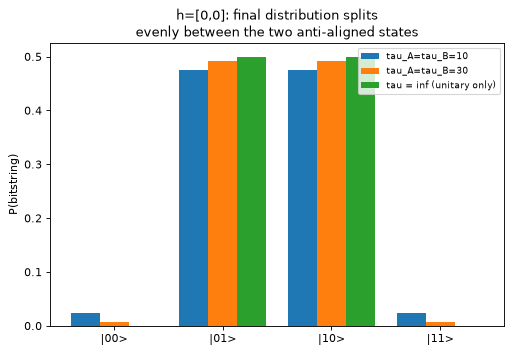

In [35]:
H_undecided = hamiltonian_nqubit(schedule, h=[0.0, 0.0], J={(0, 1): J12}, t_anneal=t_anneal_2q)
h_final_undecided = H_undecided(t_anneal_2q)
w_u, v_u = np.linalg.eigh(h_final_undecided)
print(f"Final H eigenvalues: {np.round(w_u, 4)}  -- an exactly two-fold degenerate ground doublet")
print(f"eigh's 'ground eigenvector': {np.round(v_u[:, 0].real, 4)}")
print("  -- an ARBITRARY superposition of |01> and |10>, not either bitstring individually.")
print("  P(ground) tracked against THIS vector isn't physically meaningful here -- the")
print("  final-distribution bar chart below is the diagnostic that actually makes sense.\n")

final_dists_undecided = {}
for tau in taus_2q:
    _, _, _, _, final_dist = run_2q_local_seaqt(H_undecided, t_anneal_2q, tau, BETA_DEMO)
    final_dists_undecided[tau] = final_dist
    print(f"{labels_2q[tau]:>20}: " + ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_2q, final_dist)))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
x = np.arange(len(labels_bits_2q))
width = 0.8 / len(taus_2q)
for i, tau in enumerate(taus_2q):
    ax.bar(x + (i - (len(taus_2q) - 1) / 2) * width, final_dists_undecided[tau], width, label=labels_2q[tau])
ax.set_xticks(x); ax.set_xticklabels(labels_bits_2q)
ax.set_ylabel("P(bitstring)")
ax.set_title("h=[0,0]: final distribution splits\nevenly between the two anti-aligned states")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

As expected: population splits almost evenly between $|01\rangle$
and $|10\rangle$ (both preferred equally by the antiferromagnetic
coupling, with no $h_i$ left to break the tie), while $|00\rangle$ and
$|11\rangle$ (aligned -- genuinely disfavored by $J_{12}>0$, not a
degenerate case) stay small. The residual weight on that "wrong" pair
shrinks with weaker dissipation, the same mechanism as section 6's biased
problem; in the unitary limit it is exactly zero, since the 20 ns anneal is adiabatic.

The `eigh`-selected "ground eigenvector" printed above is worth a second
look: it is not a physically meaningful vector but an essentially arbitrary
one inside the degenerate doublet -- here almost $|01\rangle$ with a small
$|10\rangle$ admixture (it was a different mix before the units correction: `eigh` returns whatever
basis the numerics happen to give). This is the same degenerate-eigenspace ambiguity that
section 8 investigates next, there for `local_seaqt_dissipator`'s *numerical*
robustness; here, for what it even means to ask "$P(\text{ground})$?" of
a genuinely tied problem.


## 8. Degenerate states and `local_seaqt_dissipator`

Section 9 will reuse the same "does it stay numerically well-behaved"
rigor as sections 1 and 9(a), but the failure mode worth testing here is
*different* from the one bath relaxation had to survive.

`bath_dissipator` computes $\ln\rho$ on the **full** $2^n\times2^n$ $\rho$.
For 2+ qubits, an exactly pure $\rho$ has a degenerate zero-eigenvalue
eigenspace of dimension $d-1\ge2$ -- `eigh` picks an essentially arbitrary
basis there, which is what made the old (removed) fixed-energy dissipator
fragile.

`local_seaqt_dissipator` instead computes $\ln\rho_J$ on each qubit's
**reduced** $2\times2$ state ($\rho_A=\mathrm{Tr}_B(\rho)$, etc. -- see
`_subsystem_dissipator` in `seaqt/local_seaqt.py`). A $2\times2$ matrix
can only be degenerate one way: both eigenvalues equal, i.e. $\rho_J$ is
*exactly proportional to the identity* -- a **maximally mixed single
qubit**. That case is actually safe by construction ($\ln(cI)=\ln(c)\,I$
is basis-independent, whichever eigenbasis `eigh` happens to return), so
purity of the *full* state alone -- which was the dangerous case for
`bath_dissipator` -- isn't automatically dangerous here.

The genuinely analogous danger for `local_seaqt_dissipator` is a
**maximally *entangled*** full pure state: then the *reduced* single-qubit
states are exactly $I/2$, and (unlike the plain-mixed case above) the
*locally perceived Hamiltonian* $H_J$ can itself become degenerate too --
worth checking directly rather than assuming it inherits `bath_dissipator`'s
good behavior for free.

**Setup: `h=[0,0]`, the symmetric antiferromagnetic problem.** With no
linear bias, $H=\tfrac{B}{2}J\,\sigma_z^{(0)}\sigma_z^{(1)}$ (pure
"problem" term, $A=0$) has an *exactly* two-fold degenerate ground doublet
spanned by $|01\rangle$ and $|10\rangle$.

In [11]:
H_sym = ising_hamiltonian(2, h=[0, 0], J={(0, 1): 1.0}, A=0.0, B=1.0)
w_sym, v_sym = np.linalg.eigh(H_sym)
print(f"H_sym eigenvalues: {np.round(w_sym, 4)}  (two-fold degenerate ground doublet)")

# The product ground state eigh actually returns here (H_sym is already diagonal,
# so there's no arbitrary-basis ambiguity in this particular trivial case):
psi_product = v_sym[:, 0]
rho_product = np.outer(psi_product, psi_product.conj())
rho_A_product = reduced_state(rho_product, keep=0)
print(f"eigh's ground state: {np.round(psi_product.real, 3)} (a computational basis state)")
print(f"  reduced rho_A eigenvalues: {np.round(np.linalg.eigvalsh(rho_A_product), 4)}  <- pure, NOT degenerate")

# The maximally-ENTANGLED combination within that same degenerate ground doublet:
psi_bell = np.zeros(4, dtype=complex)
psi_bell[1] = psi_bell[2] = 1 / np.sqrt(2)  # (|01> + |10>) / sqrt(2)
rho_bell = np.outer(psi_bell, psi_bell.conj())
rho_A_bell = reduced_state(rho_bell, keep=0)
print(f"\n(|01>+|10>)/sqrt(2) -- also an exact ground state (same energy, {w_sym[0]:.4f})")
print(f"  reduced rho_A eigenvalues: {np.round(np.linalg.eigvalsh(rho_A_bell), 6)}  <- exactly I/2, degenerate!")

H_sym eigenvalues: [-0.5 -0.5  0.5  0.5]  (two-fold degenerate ground doublet)
eigh's ground state: [0. 1. 0. 0.] (a computational basis state)
  reduced rho_A eigenvalues: [0. 1.]  <- pure, NOT degenerate

(|01>+|10>)/sqrt(2) -- also an exact ground state (same energy, -0.5000)
  reduced rho_A eigenvalues: [0.5 0.5]  <- exactly I/2, degenerate!


Both are exact, valid, pure ground states of the same degenerate
doublet -- which one you'd get from `eigh` on a less trivial (non-diagonal)
Hamiltonian is itself arbitrary. So test `local_seaqt_dissipator`'s
sensitivity to infinitesimal perturbations at **both**, the way section
1's Gibbs-state check and the old bath_dissipator check both did.

In [12]:
rng = np.random.default_rng(0)
print("Maximally-entangled pure state (degenerate reduced states), local_seaqt_dissipator:")
prev_D = None
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho_bell + eps * perturb
    rho = rho / np.trace(rho).real
    D = local_seaqt_dissipator(rho, H_sym, beta_r=1.5, tau_a=1.0, tau_b=1.0)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.6f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.6f}{change}")
    prev_D = D

print("\nProduct pure state (non-degenerate reduced states), local_seaqt_dissipator:")
prev_D = None
rng = np.random.default_rng(0)
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho_product + eps * perturb
    rho = rho / np.trace(rho).real
    D = local_seaqt_dissipator(rho, H_sym, beta_r=1.5, tau_a=1.0, tau_b=1.0)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.6f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.6f}{change}")
    prev_D = D

Maximally-entangled pure state (degenerate reduced states), local_seaqt_dissipator:
  eps=0e+00: ||D||_max = 0.000000
  eps=1e-09: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-08: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-06: ||D||_max = 0.000001, ||delta D|| = 0.000001

Product pure state (non-degenerate reduced states), local_seaqt_dissipator:
  eps=0e+00: ||D||_max = 0.000000
  eps=1e-09: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-08: ||D||_max = 0.000001, ||delta D|| = 0.000001
  eps=1e-06: ||D||_max = 0.000030, ||delta D|| = 0.000031


**Stable in both cases** -- no discontinuity, `||D||` grows smoothly
with `eps` starting from either exact pure state. This isn't a coincidence:
whichever orthonormal basis `eigh` happens to return for a *degenerate*
$2\times2$ eigenspace, the matrix there is exactly $cI$, and $\ln(cI)=\ln(c)\,I$
comes out identical regardless of that choice -- there's no ambiguous
direction for the perturbation to expose, unlike the $\ge2$-dimensional
degenerate null space a pure *full* state has at $d\ge4$.

Now the schedule-level pathological test from before, adapted to
`local_seaqt_dissipator`: the fully time-dependent `h=[0,0]` problem, whose
ground doublet stays exactly degenerate through to the end of the anneal,
starting from the maximally-entangled pure state above.

In [13]:
H_pathological = lambda t: ising_hamiltonian(
    2, h=[0, 0], J={(0, 1): 1.0}, A=(1 - np.clip(t / 20.0, 0, 1)) * 1.0, B=np.clip(t / 20.0, 0, 1)
)
diss_pathological = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r=1.5, tau_a=2.0, tau_b=2.0)
try:
    res_path = evolve(rho_bell, hamiltonian=H_pathological, t_span=(0, 20.0), dissipator=diss_pathological, n_points=50)
    traces = [np.real(np.trace(r)) for r in res_path.rho]
    min_eig_path = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_path.rho)
    print(f"Integration succeeded. trace range=[{min(traces):.6f}, {max(traces):.6f}], min eigenvalue over trajectory={min_eig_path:.6f}")
except RuntimeError as e:
    print(f"Integration failed (fast and with a clear error, not a silent hang): {e}")

Integration succeeded. trace range=[1.000000, 1.000000], min eigenvalue over trajectory=-0.074967


**Result: it also succeeded** -- no hang, no crash, exact trace
conservation throughout. The negative minimum eigenvalue printed above
isn't a *new* failure mode, though -- it's `local_seaqt_dissipator`'s
**already-documented positivity limitation** from section 9 showing up
here too (`tau=2` is deliberately the aggressive value section 9 flags as
unsafe). The degenerate-eigenbasis question this section actually set out
to test -- discontinuity under perturbation -- came back clean in both the
static check above and this dynamic one.

## 9. `local_seaqt_dissipator`: validation, and a real limitation (positivity)

Same rigor as section 1, now for the dissipator used in section 6. Three
checks, cross-checked once (not repeated here) to machine precision
($\sim10^{-16}$) against a literal port of the reference implementation
this was adapted from -- see `tests/test_local_seaqt.py`.

**(a) $D_J$ vanishes at its own local Gibbs fixed point.** Algebraic
identity (expand $\langle f\rangle_J$ and it cancels exactly) -- the same
kind of check as section 1's "vanishes at the Gibbs state".

In [14]:
rng = np.random.default_rng(3)
h_demo4 = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
m = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
rho_b_arbitrary = hermitize(m @ m.conj().T); rho_b_arbitrary /= np.trace(rho_b_arbitrary).real

h_a_actual = locally_perceived_operator(h_demo4, rho_b_arbitrary, target_qubit=0)
rho_a_eq = gibbs_state(h_a_actual, beta=1.7)
d_a = _subsystem_dissipator(rho_a_eq, h_a_actual, beta_r=1.7)
print(f"max|D_A| at its own local Gibbs state = {np.max(np.abs(d_a)):.3e}  (want ~0)")

max|D_A| at its own local Gibbs state = 1.541e-16  (want ~0)


**(b) Trace conservation and positivity, well-behaved `tau`.**

In [15]:
diss_ok = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r=1.5, tau_a=10.0, tau_b=10.0)
rho0_check = gibbs_state(H2, beta=5.0)
res_ok = evolve(rho0_check, hamiltonian=lambda t: H2, t_span=(0, 20), dissipator=diss_ok, n_points=150)
traces = [np.real(np.trace(r)) for r in res_ok.rho]
min_eig_ok = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_ok.rho)
print(f"trace range: [{min(traces):.8f}, {max(traces):.8f}]  (want ~1)")
print(f"min eigenvalue over trajectory: {min_eig_ok:.3e}  (want >= ~-1e-6)")

trace range: [1.00000000, 1.00000000]  (want ~1)
min eigenvalue over trajectory: 2.048e-05  (want >= ~-1e-6)


**(c) The limitation: positivity is NOT guaranteed for strong dissipation.**
Eq. 15 is derived in the paper as an *approximation* -- "[e]xpanding the
determinants and using the fact that the ratio of the inner products
$\epsilon=P_{SJ}/P_R$ is very small due to the large size of $R$" (the
effective reservoir is assumed to dominate over the local "system"). The
paper proves neither positivity preservation nor an explicit validity
range for $\tau_A,\tau_B,\beta_R$. Confirmed below on the real schedule
used in section 6: with the warm bath of sections 6-15, `tau=10` stays positive to $10^{-11}$ while
`tau=2` (aggressive) does not -- min eigenvalue $-6.6\times10^{-2}$, and a naive $P(\text{ground})$ of
1.025, above 1 -- and this is *not* an integration-tolerance artifact (unchanged at `rtol=1e-11` vs. the
default `1e-9`, tested separately).

**At the physical 15 mK bath the limitation is far more severe.** The same 20 ns anneal gives min
eigenvalues $-1.3\times10^{-5}$ (`tau=1000`), $-5.9\times10^{-5}$ (300), $-6.7\times10^{-4}$ (100, naive
$P=1.0012$), $-0.13$ (30, naive $P=1.15$), and the integration diverges outright at `tau=10`. So for the real
temperature the safe range is $\tau\gtrsim300$ ns -- dissipation weak on the anneal timescale -- and
the guidance "`tau >= 10` ns" used in sections 6 and 9 belongs to the warm bath only. (The first version
of this notebook quoted `tau=10` as safe with the "15 mK" bath because, dimensionally, that bath was
94 mK.) The colder bath is the less positive one in every comparison run here (2 to 6 qubits, 20 ns anneal;
sections 10, 12, 13 and 14 give the other sizes).


In [36]:
rho0_2q = gibbs_state(H_2q(0.0), BETA_INIT)  # matches section 6's initial state exactly
_, v_g = np.linalg.eigh(H_2q(t_anneal_2q))
g_vec = v_g[:, 0]


def positivity_probe(beta_r, tau):
    diss_test = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r, tau_a=tau, tau_b=tau)
    try:
        res_test = evolve(rho0_2q, hamiltonian=H_2q, t_span=(0, 20.0), dissipator=diss_test, n_points=150)
    except RuntimeError:
        return None, None  # the integration diverged
    me = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_test.rho)
    return me, float(np.real(g_vec.conj() @ res_test.rho[-1] @ g_vec))


for label, beta_r, taus in [("warm bath used in sections 6-15 (94 mK):", BETA_DEMO, [10.0, 2.0]),
                            ("physical bath (15 mK):", beta_bath, [1000.0, 300.0, 100.0, 30.0, 10.0])]:
    print(label)
    for tau_test in taus:
        me, pg = positivity_probe(beta_r, tau_test)
        if me is None:
            print(f"  tau={tau_test:>6}: integration DIVERGED (step size underflow)")
        else:
            print(f"  tau={tau_test:>6}: min eigenvalue over trajectory = {me:+.3e},  naive P(ground) = {pg:.4f}")

print("\nThe warm-bath guidance (tau >= 10 ns for the 20 ns anneal) does NOT carry over to the physical 15 mK bath.")


warm bath used in sections 6-15 (94 mK):
  tau=  10.0: min eigenvalue over trajectory = -9.539e-12,  naive P(ground) = 0.9234
  tau=   2.0: min eigenvalue over trajectory = -6.574e-02,  naive P(ground) = 1.0252
physical bath (15 mK):
  tau=1000.0: min eigenvalue over trajectory = -1.266e-05,  naive P(ground) = 1.0000
  tau= 300.0: min eigenvalue over trajectory = -5.850e-05,  naive P(ground) = 1.0001
  tau= 100.0: min eigenvalue over trajectory = -6.708e-04,  naive P(ground) = 1.0012
  tau=  30.0: min eigenvalue over trajectory = -1.269e-01,  naive P(ground) = 1.1503
  tau=  10.0: integration DIVERGED (step size underflow)

The warm-bath guidance (tau >= 10 ns for the 20 ns anneal) does NOT carry over to the physical 15 mK bath.


**From here on, this notebook uses `local_seaqt_dissipator_n` instead of `local_seaqt_dissipator`.** Sections 6-9 used and validated the hand-written 2-qubit closed form; we've since generalized it to N qubits (`seaqt/local_seaqt_n.py`) and confirmed it's bit-for-bit identical to the 2-qubit version at n=2 (`tests/test_local_seaqt_n.py`) -- so switching doesn't change any number below, only which function computes it. Section 12 puts the actual point of the generalization -- N > 2 -- to use.



## 10. Simulating control noise: `h` and `J` aren't exactly programmed on real hardware (ICE)

Section 7 studied the "genuinely undecided" `h=[0,0]` problem in the
idealized simulation, where the antiferromagnetic coupling alone splits
the population evenly between $|01\rangle$ and $|10\rangle$. On a real
D-Wave QPU, though, the *programmed* $h_i$ and $J_{ij}$ are never exactly
what the chip *realizes* -- this is documented as **Integrated Control
Error (ICE)**:
[D-Wave's own characterization](https://docs.dwavequantum.com/en/latest/quantum_research/errors.html)
states that the realized deviation is Gaussian, $\delta \sim
\mathcal N(\mu,\sigma)$, for *both* channels: $\sigma_h \sim
0.01$-$0.025$ and $\sigma_J \sim 0.0095$-$0.0155$ (dimensionless, same
units as the programmed values), varying with anneal fraction $s$. Direct
quote: *"the expected deviations of h and J during operation are the sum
of a systematic contribution $\mu$ and a random component with standard
deviation $\sigma$"* -- an additive Gaussian error model, by D-Wave's own
(explicitly stated) simplifying assumption, not something we invented.
There's also a *systematic* per-qubit/per-coupling bias documented
($\mu$, order $-0.01$ to $-0.05$ for $h$) that we don't model here -- see
`hamiltonian_nqubit_noisy_h`'s docstring.

**Caveat on these numbers**: every figure on that documentation page
giving $\sigma_h,\sigma_J$ values is explicitly captioned *"Data shown
are representative of D-Wave 2X systems"* -- an older chip generation,
not the Advantage system 5.3 this notebook's schedule comes from. No
Advantage-specific ICE characterization at the same level of detail was
found publicly documented alongside it. So $\sigma_h=0.02$, $\sigma_J
=0.012$ below are only order-of-magnitude stand-ins for *"ICE-like noise
exists on both channels, a few percent of the h/J range"* -- not values
calibrated to this specific QPU. Swap in chip-specific numbers (from
D-Wave's solver properties or a support inquiry) before treating the
spread below as quantitative for this hardware.

**Model**: for each simulated "run" (representing a different embedding,
recalibration, or day), draw a per-qubit offset $h_i \to h_i+\delta_i^h$
and a per-coupling offset $J_{ij}\to J_{ij}+\delta_{ij}^J$, each $\delta
\sim \mathcal N(0,\sigma)$, held **fixed** for the whole anneal (ICE is a
static miscalibration, not per-timestep noise) --
`hamiltonian_nqubit_noisy_h` implements exactly this (its `J_noise_std`
argument, added alongside the original `h_noise_std`). Monte Carlo over
many independent draws then shows the *spread* of outcomes a real device
would produce for a problem programmed as exactly symmetric.

We use $\sigma_h=0.02$, $\sigma_J=0.012$ (illustrative -- see caveat
above) and $\tau_A=\tau_B=30$ ns with the warm bath of sections 6-15 (positivity-safe
there, sections 9/10) so the noise effect isn't confounded with the
positivity caveat. This Monte Carlo runs 200 full anneal simulations, so
the next cell takes about half an hour with the corrected units.

Mean final distribution over 200 noisy trials (h AND J perturbed):
  P(|00>) = 0.0137 +/- 0.0073
  P(|01>) = 0.4805 +/- 0.1668
  P(|10>) = 0.4925 +/- 0.1636
  P(|11>) = 0.0133 +/- 0.0075

P(|01>) - P(|10>) across trials: mean=-0.0120, std=0.3301, range=[-0.7142, +0.7189]
Fraction of trials with |skew| > 0.05: 0.90
Fraction of trials with |skew| > 0.10: 0.81


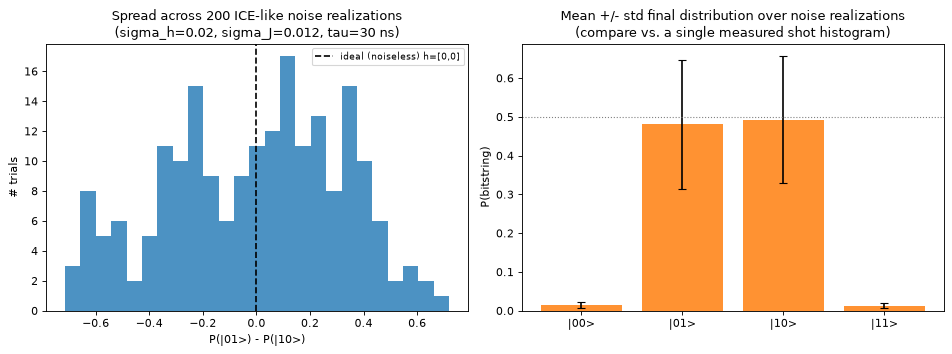

In [38]:
from seaqt.dwave import hamiltonian_nqubit_noisy_h

H_NOISE_STD = 0.02
J_NOISE_STD = 0.012
N_TRIALS = 200
TAU_ICE = 30.0

diss_ice = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, BETA_DEMO, taus=[TAU_ICE, TAU_ICE], n=2)
rng_ice = np.random.default_rng(42)

dists_ice = []
for _ in range(N_TRIALS):
    H_noisy = hamiltonian_nqubit_noisy_h(schedule, h=[0.0, 0.0], J={(0, 1): J12}, t_anneal=t_anneal_2q,
                                          h_noise_std=H_NOISE_STD, J_noise_std=J_NOISE_STD, rng=rng_ice)
    rho0_ice = gibbs_state(H_noisy(0.0), BETA_INIT)
    res_ice = evolve(rho0_ice, hamiltonian=H_noisy, t_span=(0, t_anneal_2q), dissipator=diss_ice,
                      n_points=40, rtol=1e-7, atol=1e-9)
    dists_ice.append(population_distribution(res_ice.rho[-1]))
dists_ice = np.array(dists_ice)  # shape (N_TRIALS, 4), columns = |00>,|01>,|10>,|11>

mean_dist = dists_ice.mean(axis=0)
std_dist = dists_ice.std(axis=0)
print(f"Mean final distribution over {N_TRIALS} noisy trials (h AND J perturbed):")
for lbl, m, s in zip(labels_bits_2q, mean_dist, std_dist):
    print(f"  P({lbl}) = {m:.4f} +/- {s:.4f}")

skew = dists_ice[:, 1] - dists_ice[:, 2]  # P(|01>) - P(|10>)
print(f"\nP(|01>) - P(|10>) across trials: mean={skew.mean():+.4f}, std={skew.std():.4f}, "
      f"range=[{skew.min():+.4f}, {skew.max():+.4f}]")
print(f"Fraction of trials with |skew| > 0.05: {np.mean(np.abs(skew) > 0.05):.2f}")
print(f"Fraction of trials with |skew| > 0.10: {np.mean(np.abs(skew) > 0.10):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(skew, bins=25, color="tab:blue", alpha=0.8)
axes[0].axvline(0.0, color="k", linestyle="--", label="ideal (noiseless) h=[0,0]")
axes[0].set_xlabel("P(|01>) - P(|10>)"); axes[0].set_ylabel("# trials")
axes[0].set_title(f"Spread across {N_TRIALS} ICE-like noise realizations\n"
                   f"(sigma_h={H_NOISE_STD}, sigma_J={J_NOISE_STD}, tau={TAU_ICE:g} ns)")
axes[0].legend(fontsize=8)

x = np.arange(4)
axes[1].bar(x, mean_dist, yerr=std_dist, capsize=4, color="tab:orange", alpha=0.85)
axes[1].axhline(0.5, color="gray", linestyle=":", lw=1)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels_bits_2q)
axes[1].set_ylabel("P(bitstring)")
axes[1].set_title("Mean +/- std final distribution over noise realizations\n(compare vs. a single measured shot histogram)")
fig.tight_layout(); plt.show()

**The average over many noise realizations recovers the symmetric ideal**
($P(|01\rangle)\approx0.481$, $P(|10\rangle)\approx0.493$ -- consistent
with 0.5/0.5 within Monte Carlo noise, since both $\delta^h$ and $\delta^J$ are
zero-mean), **but any single realization -- i.e. what one actual experimental
run would show -- is strongly skewed**: the
$P(|01\rangle)-P(|10\rangle)$ split has
std $\approx0.33$ across trials, spans almost the whole range
$[-0.71, +0.72]$ in this sample of 200 (the histogram is close to flat), and
**about 90% of trials show a >5-point skew, about
81% a >10-point skew** away from perfect balance.

That is far more than the first version of this section found (std $\approx0.063$,
46% and 12%). The most likely reason is the units: with the corrected $H$ the 20 ns
anneal is adiabatic, so the system follows the *instantaneous ground state*, and for any
nonzero $\delta^h$ the two anti-aligned states are no longer degenerate -- the tiny random bias decides which one
the anneal selects, with little diabatic mixing to wash it out. (In the first version $H$ was $2\pi$
too small, the same anneal was effectively diabatic, and the final populations were much
less sensitive to the small energy splitting.) This was not tested separately here.

This is exactly the qualitative effect your advisor is describing:
programming `h=[0,0]` does not mean the hardware sees a truly symmetric
problem -- and the same holds for `J`, whose ICE is comparable in
magnitude to `h`'s. Averaging shot statistics over many different
embeddings or recalibrations would recover the expected 50/50 split, but
a single deployed run on fixed physical qubits should be expected to show
a real, non-negligible bias -- not evidence of a mistake in the problem
setup or the simulation, but the fingerprint of ICE. If you have
chip-specific ICE numbers (rather than the general characterization used
here), swap them into `H_NOISE_STD`/`J_NOISE_STD` for a more targeted
comparison against your actual measured data. `hamiltonian_nqubit_noisy_h`
works the same way for any `h`/`J` (not just this problem) and composes
with everything else in this notebook -- e.g. it could be dropped into
section 6's biased problem too, to see how much ICE noise it would take
to flip which bitstring wins.


## 12. Beyond 2 qubits: a 3-qubit chain with `local_seaqt_dissipator_n`

The actual payoff of generalizing to N qubits: the real D-Wave schedule
and `local_seaqt_dissipator_n` compose directly, no 2-qubit-specific code
needed anywhere. Linear 3-qubit chain (`J_{01}, J_{12}`, no `J_{02}` --
the topology you'd get embedding a path on real hardware), asymmetric
bias so there's a unique ground state to track.

**A concrete instance of section 10's finding, now in N**: the `tau_A=tau_B>=10` ns guidance from section 9 was calibrated for *2* coupled
qubits at `t_anneal=20` ns. With the warm bath it carries over to 3 qubits only in part: `tau=10` gives a
min eigenvalue of $-1.3\times10^{-5}$ (a mild violation, versus $\sim10^{-11}$ at 2 qubits) and it is gone by `tau=30`
($\sim10^{-12}$, numerical zero); the scan printed by the next cell shows the whole range. (The first
version of this section found a much stronger size dependence -- `tau=30` gave $-3.2\times10^{-4}$ at 3 qubits and
`tau=1000` was needed to reach $-3.4\times10^{-5}$ -- but dimensionally that was a 3.2 ns anneal with a $2\pi$-shorter
$\tau$: the equivalent problem reproduces those numbers exactly, and it is a different regime from the 20 ns
anneal used here.) At the physical 15 mK bath `tau=10` diverges for 3 qubits, as it does for 2 (section 9).


Positivity vs tau, 3-qubit chain, warm bath (min eigenvalue over the trajectory):
  tau=  10.0: -1.345e-05
  tau=  30.0: -4.279e-12
  tau= 100.0: -1.444e-12
  tau= 300.0: -1.233e-12
  tau=1000.0: -1.058e-12

Ground state: |101>, gap=43.1596
    tau=10 (all 3 qubits): min eigenvalue = -1.345e-05, max|trace-1| = 1.55e-15
  P(|000>)=0.0016, P(|001>)=0.0287, P(|010>)=0.0035, P(|011>)=0.0026, P(|100>)=0.0532, P(|101>)=0.8920, P(|110>)=0.0176, P(|111>)=0.0007
 tau = inf (unitary only): min eigenvalue = -2.125e-11, max|trace-1| = 4.66e-15
  P(|000>)=0.0000, P(|001>)=0.0000, P(|010>)=0.0000, P(|011>)=0.0000, P(|100>)=0.0001, P(|101>)=0.9999, P(|110>)=0.0000, P(|111>)=0.0000


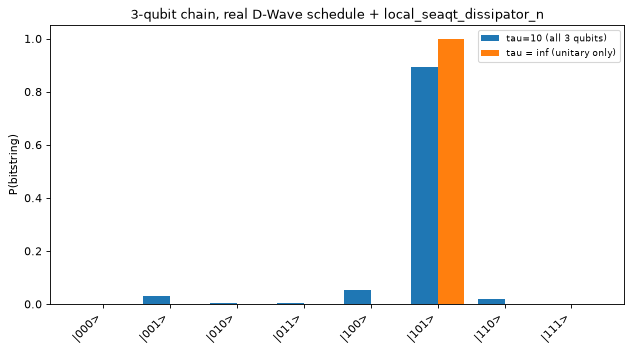

In [39]:
H_BIAS_3Q = [0.6, -0.4, 0.3]
J_3Q = {(0, 1): 0.5, (1, 2): 0.5}  # linear chain: 0-1-2, no 0-2 coupling
t_anneal_3q = 20.0

H_3q = hamiltonian_nqubit(schedule, h=H_BIAS_3Q, J=J_3Q, t_anneal=t_anneal_3q)
h3_final = H_3q(t_anneal_3q)
w3, v3 = np.linalg.eigh(h3_final)
labels_bits_3q = basis_labels(3)

print("Positivity vs tau, 3-qubit chain, warm bath (min eigenvalue over the trajectory):")
for tau_scan in [10.0, 30.0, 100.0, 300.0, 1000.0]:
    diss_scan = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, BETA_DEMO, taus=[tau_scan] * 3, n=3)
    res_scan = evolve(gibbs_state(H_3q(0.0), BETA_INIT), hamiltonian=H_3q, t_span=(0, t_anneal_3q), dissipator=diss_scan, n_points=150)
    print(f"  tau={tau_scan:>6}: {min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_scan.rho):+.3e}")
print()
ground_idx_3q = int(np.argmax(np.abs(v3[:, 0])))
print(f"Ground state: {labels_bits_3q[ground_idx_3q]}, gap={w3[1]-w3[0]:.4f}")

taus_3q = [10, np.inf]
labels_3q = {10.0: "tau=10 (all 3 qubits)", np.inf: "tau = inf (unitary only)"}
rho0_3q = gibbs_state(H_3q(0.0), BETA_INIT)

final_dists_3q = {}
fig, ax = plt.subplots(figsize=(8, 4.5))
for tau in taus_3q:
    if np.isfinite(tau):
        diss = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, BETA_DEMO, taus=[tau, tau, tau], n=3)
        res = evolve(rho0_3q, hamiltonian=H_3q, t_span=(0, t_anneal_3q), dissipator=diss, n_points=150)
    else:
        res = evolve(rho0_3q, hamiltonian=H_3q, t_span=(0, t_anneal_3q), n_points=150)
    final_dist = population_distribution(res.rho[-1])
    final_dists_3q[tau] = final_dist
    min_eig = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res.rho)
    trace_err = max(abs(np.real(np.trace(r)) - 1.0) for r in res.rho)
    print(f"{labels_3q[tau]:>25}: min eigenvalue = {min_eig:+.3e}, max|trace-1| = {trace_err:.2e}")
    print("  " + ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_3q, final_dist)))

x = np.arange(len(labels_bits_3q))
width = 0.8 / len(taus_3q)
for i, tau in enumerate(taus_3q):
    ax.bar(x + (i - (len(taus_3q) - 1) / 2) * width, final_dists_3q[tau], width, label=labels_3q[tau])
ax.set_xticks(x); ax.set_xticklabels(labels_bits_3q, rotation=45, ha="right")
ax.set_ylabel("P(bitstring)")
ax.set_title("3-qubit chain, real D-Wave schedule + local_seaqt_dissipator_n")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 13. ICE-like noise at N=4: does the skew get worse or better?

Same experiment as section 11, now on the 4-qubit linear chain from
section 12 with $h=[0,0,0,0]$ -- the N=4 analogue of section 7's
"genuinely undecided" problem. With only antiferromagnetic
nearest-neighbor coupling on a chain, the ground state is exactly
2-fold degenerate between the two Néel orderings, $|0101\rangle$ and
$|1010\rangle$ (confirmed: the two lowest final-Hamiltonian eigenvalues
match to machine precision). $\tau=20$ ns here, with the warm bath: the noiseless 4-qubit
chain is positivity-safe over the whole range scanned by the next cell
(min eigenvalue $-7\times10^{-9}$ at $\tau=20$ and at most $-7\times10^{-8}$ up to $\tau=2000$),
so the size dependence that made section 12 need larger $\tau$ in the first version does not
appear at this anneal time. (At the physical 15 mK bath the same problem gives $-8.4\times10^{-3}$
at $\tau=20$ and $-1.8\times10^{-4}$ at $\tau=1000$.)


Noiseless positivity check, 4-qubit chain, warm bath (min eigenvalue over the trajectory):
  tau=  20.0: -7.309e-09
  tau= 100.0: -8.376e-09
  tau=1000.0: -4.760e-08
  tau=2000.0: -7.183e-08

Mean final distribution over 100 noisy 4-qubit trials (states with weight > 0.5%):
  P(|0010>) = 0.0097 +/- 0.0059
  P(|0100>) = 0.0105 +/- 0.0066
  P(|0101>) = 0.4708 +/- 0.1129
  P(|0110>) = 0.0086 +/- 0.0015
  P(|1001>) = 0.0088 +/- 0.0015
  P(|1010>) = 0.4577 +/- 0.1142
  P(|1011>) = 0.0100 +/- 0.0062
  P(|1101>) = 0.0108 +/- 0.0065

P(|0101>) - P(|1010>) across trials: mean=+0.0130, std=0.2268, range=[-0.4963, +0.5126]
Fraction of trials with |skew| > 0.05: 0.80
Fraction of trials with |skew| > 0.10: 0.75
Mean weight kept on the 2 Neel states: 0.9285


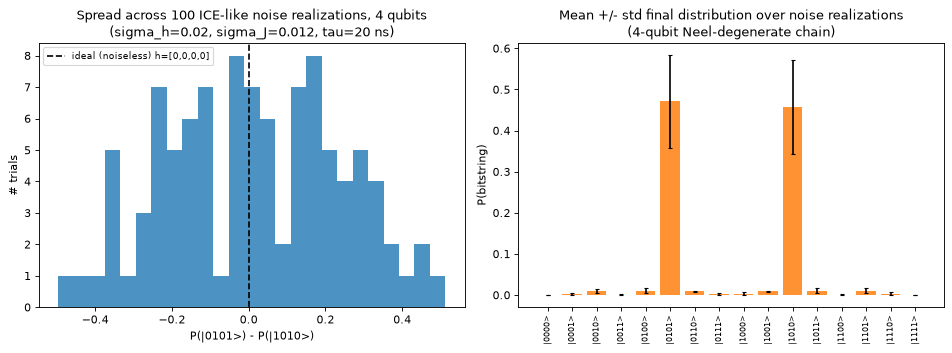

In [40]:
from seaqt.dwave import hamiltonian_nqubit_noisy_h
H_NOISE_STD = 0.02
J_NOISE_STD = 0.012
TAU_ICE_4Q = 20  # positivity at this size / warm bath is checked just below (noiseless problem)
N_TRIALS = 100
N_QUBITS = 4

h4 = [0.0, 0.0, 0.0, 0.0]
J4 = {(0, 1): 0.5, (1, 2): 0.5, (2, 3): 0.5}  # linear chain, section 12's topology
labels_bits_4q = basis_labels(4)
idx_0101 = labels_bits_4q.index("|0101>")
idx_1010 = labels_bits_4q.index("|1010>")

diss_4q = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, BETA_DEMO, [TAU_ICE_4Q] * N_QUBITS, N_QUBITS)

print("Noiseless positivity check, 4-qubit chain, warm bath (min eigenvalue over the trajectory):")
H_clean_4q = hamiltonian_nqubit(schedule, h=h4, J=J4, t_anneal=t_anneal_2q)
for tau_scan in [20.0, 100.0, 1000.0, 2000.0]:
    diss_scan = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, BETA_DEMO, [tau_scan] * N_QUBITS, N_QUBITS)
    res_scan = evolve(gibbs_state(H_clean_4q(0.0), BETA_INIT), hamiltonian=H_clean_4q, t_span=(0, t_anneal_2q),
                      dissipator=diss_scan, n_points=40, rtol=1e-6, atol=1e-8)
    print(f"  tau={tau_scan:>6}: {min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_scan.rho):+.3e}")
print()
rng_4q = np.random.default_rng(42)

dists_4q = []
for _ in range(N_TRIALS):
    H_noisy = hamiltonian_nqubit_noisy_h(schedule, h=h4, J=J4, t_anneal=t_anneal_2q,
                                          h_noise_std=H_NOISE_STD, J_noise_std=J_NOISE_STD, rng=rng_4q)
    rho0_4q = gibbs_state(H_noisy(0.0), BETA_INIT)
    res_4q = evolve(rho0_4q, hamiltonian=H_noisy, t_span=(0, t_anneal_2q), dissipator=diss_4q,
                     n_points=40, rtol=1e-6, atol=1e-8)
    dists_4q.append(population_distribution(res_4q.rho[-1]))
dists_4q = np.array(dists_4q)  # shape (N_TRIALS, 16)

mean_dist_4q = dists_4q.mean(axis=0)
std_dist_4q = dists_4q.std(axis=0)
print(f"Mean final distribution over {N_TRIALS} noisy 4-qubit trials (states with weight > 0.5%):")
for lbl, m, s in zip(labels_bits_4q, mean_dist_4q, std_dist_4q):
    if m > 0.005 or s > 0.005:
        print(f"  P({lbl}) = {m:.4f} +/- {s:.4f}")

skew_4q = dists_4q[:, idx_0101] - dists_4q[:, idx_1010]  # P(|0101>) - P(|1010>)
print(f"\nP(|0101>) - P(|1010>) across trials: mean={skew_4q.mean():+.4f}, std={skew_4q.std():.4f}, "
      f"range=[{skew_4q.min():+.4f}, {skew_4q.max():+.4f}]")
print(f"Fraction of trials with |skew| > 0.05: {np.mean(np.abs(skew_4q) > 0.05):.2f}")
print(f"Fraction of trials with |skew| > 0.10: {np.mean(np.abs(skew_4q) > 0.10):.2f}")
print(f"Mean weight kept on the 2 Neel states: {(dists_4q[:, idx_0101] + dists_4q[:, idx_1010]).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(skew_4q, bins=25, color="tab:blue", alpha=0.8)
axes[0].axvline(0.0, color="k", linestyle="--", label="ideal (noiseless) h=[0,0,0,0]")
axes[0].set_xlabel("P(|0101>) - P(|1010>)"); axes[0].set_ylabel("# trials")
axes[0].set_title(f"Spread across {N_TRIALS} ICE-like noise realizations, 4 qubits\n"
                   f"(sigma_h={H_NOISE_STD}, sigma_J={J_NOISE_STD}, tau={TAU_ICE_4Q:g} ns)")
axes[0].legend(fontsize=8)

x = np.arange(16)
axes[1].bar(x, mean_dist_4q, yerr=std_dist_4q, capsize=2, color="tab:orange", alpha=0.85)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels_bits_4q, rotation=90, fontsize=7)
axes[1].set_ylabel("P(bitstring)")
axes[1].set_title("Mean +/- std final distribution over noise realizations\n(4-qubit Neel-degenerate chain)")
fig.tight_layout(); plt.show()

**The relative spread is smaller at N=4 than at N=2.** With 4
independent noisy $h_i$'s and 3 independent noisy $J_{ij}$'s (7 random
draws total, vs. 3 for the 2-qubit case), $P(|0101\rangle)-P(|1010\rangle)$
has std $\approx0.23$ (vs. $\approx0.33$ at N=2), and
**80% of trials show a >5-point skew, 75% a >10-point skew** (vs.
90%/81% at N=2). Both are large in absolute terms, for the reason given in section 11 (the
20 ns anneal is adiabatic in the corrected units). Together the two Néel states hold
$\approx93\%$ of the final population -- the rest spreads thinly across
the six single-defect states one bit-flip away from a Néel ordering
(about 1% each), rather than concentrating the "leftover" weight
anywhere in particular.

The mechanism proposed in the first version of this section (more independent random draws partially
cancelling in the one global observable) was not re-tested here and should be read as a hypothesis. One
exact fact is worth keeping in mind: the two Néel orderings have identical coupling energy for *any*
$J_{ij}$ (every bond is anti-aligned in both), so the energy difference between them comes only from
the $h_i$ noise, and the spread of the skew is not evidence that ICE matters less for larger problems in
general -- the *local* defect-state populations are exactly where individual qubits' noise shows up
most directly, and would be the more relevant diagnostic for a differently-shaped problem.


## 14. Beyond a chain: a 6-qubit antiferromagnetic ring

Every multi-qubit test so far (sections 12-13) used a linear chain. A
*ring* (cycle) topology is a better match for comparing against real
D-Wave hardware: it's the QPU's native unit-cell loop connectivity, and
(for even $N$) an antiferromagnetic ring has no distinguished "edge"
qubits -- by symmetry, the ground state is exactly 2-fold degenerate
between the two Néel orderings, with no asymmetric bias needed to make
the problem well-defined the way sections 6/12 needed one.

**How large a ring can `local_seaqt_dissipator_n` handle in reasonable
time?** Timing a single `evolve()` call (`tau=1000`, `t_anneal=20`,
`n_points=40`) on a symmetric ($h=0$) $N$-cycle, with the corrected units. The
times are comparable to the first version's (4.6, 7.6 and 35 s): the corrected $H$ is $2\pi$ larger and
needs about 6x more integrator steps, which the vectorized `evolve` roughly offsets.

| $N$ | dim | time | min eigenvalue, warm bath (94 mK) | min eigenvalue, physical 15 mK |
|---|-----|------|-----------------|-----------------|
| 4 | 16  | 14 s | -3.6e-09 | -3.3e-04 (unsafe) |
| 5 | 32  | 5.5 s | -8.0e-07 | -1.2e-04 (unsafe) |
| 6 | 64  | 40 s | -4.5e-08 | -2.8e-04 (unsafe) |

$N=7$ and $8$ were not re-timed: they took 100 s and $\approx$24 min in the first version and would take
several times longer now that the corrected $H$ needs more integrator steps. $N=6$ is the largest ring where a sweep of several dozen
`evolve()` calls (e.g. section 15's anneal-time sweep) is still practical. Note that at the
physical 15 mK bath all three sizes violate positivity by $10^{-4}$ even at `tau=1000` -- one more reminder,
with sections 9-10, that the local dissipator is a warm-bath tool.


In [41]:
def ring_J(n, j_val=0.5):
    return {(i, (i + 1) % n): j_val for i in range(n)}

N_RING = 6
TAU_RING = 1000  # positivity-safe at this size with the warm bath (see the table above)
t_anneal_ring = 20.0
h_ring = [0.0] * N_RING
J_ring = ring_J(N_RING)

H_ring = hamiltonian_nqubit(schedule, h=h_ring, J=J_ring, t_anneal=t_anneal_ring)
h_ring_final = H_ring(t_anneal_ring)
w_ring, v_ring = np.linalg.eigh(h_ring_final)
labels_ring = basis_labels(N_RING)
print(f"Ring: N={N_RING}, J={J_ring}")
print(f"Final-Hamiltonian spectrum near ground state: {np.round(w_ring[:6], 4)}")
gs_idx = [i for i in range(len(w_ring)) if abs(w_ring[i] - w_ring[0]) < 1e-6]
print(f"Ground-state degeneracy: {len(gs_idx)}, states: "
      f"{[labels_ring[int(np.argmax(np.abs(v_ring[:, i])))] for i in gs_idx]}")

rho0_ring = gibbs_state(H_ring(0.0), BETA_INIT)
diss_ring = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, BETA_DEMO, [TAU_RING] * N_RING, N_RING)
res_ring = evolve(rho0_ring, hamiltonian=H_ring, t_span=(0, t_anneal_ring), dissipator=diss_ring,
                   n_points=40, rtol=1e-7, atol=1e-9)
min_eig_ring = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_ring.rho)
dist_ring = population_distribution(res_ring.rho[-1])
print(f"\nIdeal (noiseless) trial: min_eig={min_eig_ring:+.3e}")
print("Final distribution (weight > 1%):")
for lbl, p in zip(labels_ring, dist_ring):
    if p > 0.01:
        print(f"  P({lbl}) = {p:.4f}")


Ring: N=6, J={(0, 1): 0.5, (1, 2): 0.5, (2, 3): 0.5, (3, 4): 0.5, (4, 5): 0.5, (5, 0): 0.5}
Final-Hamiltonian spectrum near ground state: [-80.9243 -80.9243 -26.9748 -26.9748 -26.9748 -26.9748]
Ground-state degeneracy: 2, states: ['|010101>', '|101010>']

Ideal (noiseless) trial: min_eig=-4.464e-08
Final distribution (weight > 1%):
  P(|010101>) = 0.4990
  P(|101010>) = 0.4990


Confirmed: the ground state is exactly 2-fold degenerate
(`|101010⟩`, `|010101⟩`), and the first excited band is exactly
4-fold degenerate -- both exact consequences of the ring's
rotation/reflection symmetry. At `tau=1000` the noiseless trajectory is
safely positive (min_eig=-4.5e-8, matching the benchmark table above) and the
two Néel states hold 99.8% of the final population (0.499 each; the first version, whose
20 ns anneal was effectively 3.2 ns, ended with 71%).


## 15. The Landau-Zener regime: validating against King et al. 2022

Our $N=6$ ring is far below the thermodynamic-limit chains ($L=512$-$2000$)
that D-Wave's own Kibble-Zurek experiments use to see quantum-KZM power-law
scaling -- but King et al. (*Coherent quantum annealing in a programmable
2000-qubit Ising chain*, arXiv:2202.05847v2, 2022) show that **short**
chains ($L=8$-$32$ in their own hardware tests) instead follow a
Landau-Zener transition at a single minimum gap, with a closed-form,
**zero-fit-parameter** prediction (their Eq. 8, Appendix C Eqs. C17-C21):

$$1-P_{GS} = e^{-a\,t_a}, \qquad a = \frac{2\pi^3 b}{L^2}, \qquad
b = \frac{\Gamma(s_c)/\hbar}{\mathcal{J}'(s_c)/\mathcal{J}(s_c) - \Gamma'(s_c)/\Gamma(s_c)}$$

with $s_c$ the critical point where $\Gamma(s_c)=\mathcal{J}(s_c)|J|$. Their
Hamiltonian convention $H(s)=-\Gamma(s)\sum\sigma_x + \mathcal{J}(s)\sum
J\sigma_z\sigma_z$ maps onto ours with one unit conversion: the schedule's $A(s)$, $B(s)$ are
$A/h$, $B/h$ in GHz, so $\Gamma(s)/\hbar=2\pi A(s)/2$ and $\mathcal{J}(s)/\hbar=2\pi B(s)/2$
in rad/ns -- the same $2\pi$ that multiplies $H$ in `hamiltonian_nqubit` -- with their dimensionless
$J$ = our `J_ring` magnitude (0.5).

This is close to a free sanity check: it compares our own schedule-driven
unitary evolution against a known closed-form result, with nothing to
tune. With the corrected units $a$ is $2\pi$ larger than in the first version of this section, so the
anneal times that sample $1-P_{GS}$ from $\sim1$ down to $\sim0.02$ are $2\pi$ shorter (0.16-9.5 ns).
We also run the same sweep *with* `local_seaqt_dissipator_n`
(`tau=15` ns and the warm bath of sections 6-15, strong enough to be visible over these anneal times)
to see how far thermal coupling pulls us from the ideal coherent curve -- King et al.'s own
"crossover to the open quantum regime" (anti-Kibble-Zurek at slower
anneals) is exactly this kind of effect.


s_c=0.3372, b=0.23763 ns^-1, a_theory=0.40933 ns^-1
t_a=  0.16 ns  1-P_GS(unitary)=9.5103e-01  1-P_GS(+diss)=9.5103e-01  min_eig(diss)=-4.11e-05
t_a=  0.24 ns  1-P_GS(unitary)=9.3216e-01  1-P_GS(+diss)=9.3216e-01  min_eig(diss)=-9.65e-05
t_a=  0.32 ns  1-P_GS(unitary)=9.0960e-01  1-P_GS(+diss)=9.0961e-01  min_eig(diss)=-1.23e-04
t_a=  0.48 ns  1-P_GS(unitary)=8.6052e-01  1-P_GS(+diss)=8.6060e-01  min_eig(diss)=-1.81e-04
t_a=  0.64 ns  1-P_GS(unitary)=8.0567e-01  1-P_GS(+diss)=8.0588e-01  min_eig(diss)=-2.51e-04
t_a=  0.80 ns  1-P_GS(unitary)=7.5046e-01  1-P_GS(+diss)=7.5092e-01  min_eig(diss)=-2.84e-04
t_a=  1.11 ns  1-P_GS(unitary)=6.5256e-01  1-P_GS(+diss)=6.5378e-01  min_eig(diss)=-3.86e-04
t_a=  1.43 ns  1-P_GS(unitary)=5.6961e-01  1-P_GS(+diss)=5.7191e-01  min_eig(diss)=-4.69e-04
t_a=  1.91 ns  1-P_GS(unitary)=4.6759e-01  1-P_GS(+diss)=4.7190e-01  min_eig(diss)=-4.92e-04
t_a=  2.39 ns  1-P_GS(unitary)=3.8511e-01  1-P_GS(+diss)=3.9174e-01  min_eig(diss)=-3.74e-04
t_a=  3.18 ns  1-P

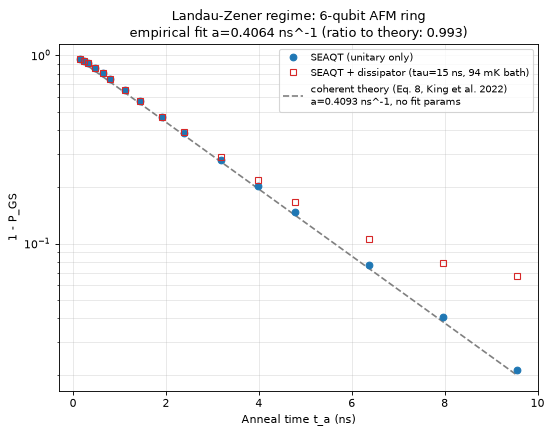

In [42]:
from scipy.optimize import brentq

J_ABS = 0.5  # matches section 14's ring coupling magnitude
# King et al. Eq. 4: b = (Gamma(s_c)/hbar) / (J'/J - Gamma'/Gamma). schedule.A/B are A(s)/h, B(s)/h in GHz, so
# Gamma/hbar and J_cal/hbar in rad/ns carry a factor 2*pi (it cancels in the critical-point condition and in J'/J,
# but not in the prefactor Gamma(s_c) of b).
Gamma = lambda s: 2 * np.pi * schedule.A(s) / 2.0
Jcal = lambda s: 2 * np.pi * schedule.B(s) / 2.0
sc = brentq(lambda s: Gamma(s) - Jcal(s) * J_ABS, 1e-6, 1 - 1e-6)
eps = 1e-4
Gamma_sc, Jcal_sc = Gamma(sc), Jcal(sc)
Gamma_p = (Gamma(sc + eps) - Gamma(sc - eps)) / (2 * eps)
Jcal_p = (Jcal(sc + eps) - Jcal(sc - eps)) / (2 * eps)
b_lz = Gamma_sc / (Jcal_p / Jcal_sc - Gamma_p / Gamma_sc)
a_theory = 2 * np.pi**3 * b_lz / N_RING**2
print(f"s_c={sc:.4f}, b={b_lz:.5f} ns^-1, a_theory={a_theory:.5f} ns^-1")

# a_theory is 2*pi times larger than in the first version of this section, so the anneal times that sample
# 1-P_GS between ~1 and ~0.02 are 2*pi shorter: the first version's list (1...60 ns) divided by 2*pi.
T_ANNEAL_LIST = np.array([1, 1.5, 2, 3, 4, 5, 7, 9, 12, 15, 20, 25, 30, 40, 50, 60]) / (2 * np.pi)
TAU_LZ = 15.0  # dissipation strong enough to be visible over these anneal times (warm bath, see section 6)
t_lz, pgs_u_lz, pgs_d_lz, mineig_lz = [], [], [], []
for ta in T_ANNEAL_LIST:
    H_lz = hamiltonian_nqubit(schedule, h=h_ring, J=J_ring, t_anneal=ta)
    w0, v0 = np.linalg.eigh(H_lz(0.0))
    rho0 = np.outer(v0[:, 0], v0[:, 0].conj())
    wf, vf = np.linalg.eigh(H_lz(ta))
    gs_idx_lz = [i for i in range(len(wf)) if abs(wf[i] - wf[0]) < 1e-6]
    P_ground = sum(np.outer(vf[:, i], vf[:, i].conj()) for i in gs_idx_lz)

    res_u = evolve(rho0, hamiltonian=H_lz, t_span=(0, ta), n_points=25, rtol=1e-8, atol=1e-10)
    pgs_u = float(np.real(np.trace(res_u.rho[-1] @ P_ground)))

    diss_lz = lambda t, rho, h: local_seaqt_dissipator_n(rho, h, BETA_DEMO, [TAU_LZ] * N_RING, N_RING)
    res_d = evolve(rho0, hamiltonian=H_lz, t_span=(0, ta), dissipator=diss_lz, n_points=25,
                    rtol=1e-7, atol=1e-9)
    pgs_d = float(np.real(np.trace(res_d.rho[-1] @ P_ground)))
    min_eig_d = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_d.rho)

    t_lz.append(ta); pgs_u_lz.append(pgs_u); pgs_d_lz.append(pgs_d); mineig_lz.append(min_eig_d)
    print(f"t_a={ta:6.2f} ns  1-P_GS(unitary)={1-pgs_u:.4e}  1-P_GS(+diss)={1-pgs_d:.4e}  "
          f"min_eig(diss)={min_eig_d:+.2e}")

t_lz, pgs_u_lz, pgs_d_lz, mineig_lz = map(np.array, (t_lz, pgs_u_lz, pgs_d_lz, mineig_lz))
one_minus_u = 1 - pgs_u_lz
one_minus_d = 1 - pgs_d_lz
mask = one_minus_u > 1e-6
slope, _ = np.polyfit(t_lz[mask], np.log(one_minus_u[mask]), 1)
a_fit = -slope
print(f"\nEmpirical fit (unitary): a_fit = {a_fit:.5f} ns^-1  vs. a_theory = {a_theory:.5f} ns^-1  "
      f"(ratio {a_fit/a_theory:.3f})")

t_theory = np.linspace(t_lz.min(), t_lz.max(), 200)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.semilogy(t_lz, one_minus_u, "o", color="tab:blue", label="SEAQT (unitary only)", zorder=3)
ax.semilogy(t_lz, one_minus_d, "s", color="tab:red", markerfacecolor="none",
            label=f"SEAQT + dissipator (tau={TAU_LZ:g} ns, 94 mK bath)", zorder=3)
ax.semilogy(t_theory, np.exp(-a_theory * t_theory), "--", color="gray",
            label=f"coherent theory (Eq. 8, King et al. 2022)\na={a_theory:.4f} ns^-1, no fit params")
ax.set_xlabel("Anneal time t_a (ns)"); ax.set_ylabel("1 - P_GS")
ax.set_title("Landau-Zener regime: 6-qubit AFM ring\n"
             f"empirical fit a={a_fit:.4f} ns^-1 (ratio to theory: {a_fit/a_theory:.3f})")
ax.legend(fontsize=9); ax.grid(alpha=0.3, which="both")
fig.tight_layout(); plt.show()


**Strong agreement, zero fit parameters.** The empirical exponent from the
unitary curve, $a_{\text{fit}}=0.406$ ns$^{-1}$, matches the theoretical
$a=0.409$ ns$^{-1}$ (computed purely from our own schedule -- no tuning)
to within 0.7%. This is a cheap, meaningful validation of the integration and of the mapping
$A(s),B(s)\to\Gamma(s),\mathcal{J}(s)$: a sign error or a wrong mapping would not line up this well.
It is, however, **blind to a factor common to the simulation and the formula**. The first version of
this section claimed it would also catch a missing factor of $2\pi$; that was wrong -- both sides then
used the schedule's GHz values as angular frequencies, and the ratio is unchanged when both carry the
$2\pi$, as they do now (the ratio is 0.993 either way). The $2\pi$ comes from the datasheet's definition of the
columns ($A/h$, $B/h$); it was the comparison with real hardware (section 16) that exposed it.

**Where the dissipator departs from the ideal curve.** The two curves agree to within 1% up to
$t_a\approx2$ ns, then the dissipator curve visibly lifts above the unitary/theory line -- at
$t_a=9.55$ ns, $1-P_{GS}$ goes from 0.0213 (unitary) to 0.0676 (with dissipator), about three times more
residual excitation than the ideal closed-system prediction. This is the same qualitative effect King et
al. call the crossover to the open quantum regime: the longer the anneal, the more time the thermal
coupling has to act, pulling the result away from the coherent limit. The dissipator here is deliberately
strong ($\tau=15$ ns, 94 mK bath); it is not the hardware's.

**Same positivity caveat as sections 9-10**: the points where the dissipator curve departs most
($t_a\ge4$ ns) are also where `min_eig` goes below $-10^{-3}$ (down to $-2.1\times10^{-3}$ at
$t_a=6.4$ ns) -- worth keeping in mind, though it doesn't change the qualitative crossover trend shown here.


## 16. Real hardware: Advantage2_system1 at JUPSI

The first real quantum-annealer measurements in this whole project --
not simulation. Ring and open chain (6 qubits, both antiferromagnetic,
$h=0$), submitted to a real Advantage2 QPU (JUPSI, solver
`Advantage2_system1`) via the **fast-anneal protocol**, sweeping both $J$
(5 multiples of the measured $k_B T/h$, 20 mK $\to$ 416.7 MHz) and
$t_{\text{anneal}}$ (log-spaced across the solver's own
`fast_anneal_time_range`, 7.5 ns to 20 $\mu$s). Full experiment code is in
`experiments/advantage2_lz_crossover/` (`config.py`, `submit_hardware.py`)
-- see that folder's README for the full derivation and the hardware
constraints that shaped this design (in particular, why the $J$ sweep
uses the *ferromagnetic* sign and stops at 4x rather than the originally
planned 20x -- both dictated by this specific chip's `extended_j_range`,
not a free choice).

A few things worth having explicit before reading the results:

- **Both topologies run on the *same* physical qubits** -- one embedding
  found on the ring (chain's edges are a strict subset of ring's), reused
  for both, specifically so a ring-vs-chain difference can't be
  individual-qubit calibration noise in disguise.
- **`auto_scale=False`** on every submission -- otherwise the API would
  silently rescale the $J$ we calibrated via `solve_s_c_and_J`, and every
  point would stop corresponding to the $k_BT/h$ multiple we think we
  programmed.
- **Zero chain breaks, zero failed submissions**: 120/120 points
  (2 topologies $\times$ 5 $J$ $\times$ 12 $t_a$), 1000 reads each.


Loaded 120 real hardware measurements from Advantage2_system1 (JUPSI)
  chain_break_fraction: min=0.000, max=0.000  (0 everywhere -- fixed native embedding, no chains)
  physical qubits used (both topologies, shared embedding): 629 641 653 665 3483 3507


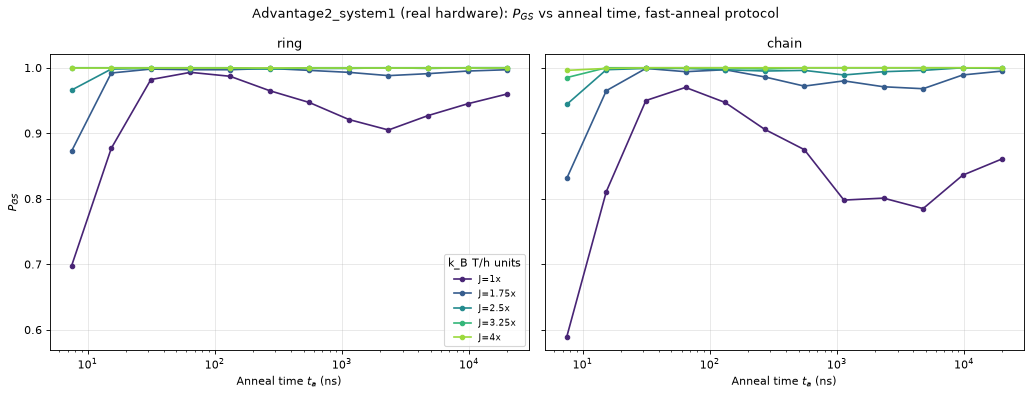

In [21]:
import pandas as pd

# results/exploratory.csv now holds the extended 35-topology campaign (section 16.3);
# the original 120-point ring/chain campaign analysed in 16-16.2 is kept separately.
HW_RESULTS_PATH = (
    r"c:\Users\andre\OneDrive\Documentos\GitHub\SEAQT-quantum-annealing-evolution"
    r"\experiments\advantage2_lz_crossover\results\exploratory_ringchain_original.csv"
)
hw_results = pd.read_csv(HW_RESULTS_PATH)
print(f"Loaded {len(hw_results)} real hardware measurements from Advantage2_system1 (JUPSI)")
print(f"  chain_break_fraction: min={hw_results.chain_break_fraction.min():.3f}, "
      f"max={hw_results.chain_break_fraction.max():.3f}  (0 everywhere -- fixed native embedding, no chains)")
print(f"  physical qubits used (both topologies, shared embedding): {hw_results.physical_qubits.iloc[0]}")

colors = plt.cm.viridis(np.linspace(0.1, 0.85, 5))
j_multiples_hw = sorted(hw_results.j_multiple.unique())
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, topo in zip(axes, ["ring", "chain"]):
    for jm, c in zip(j_multiples_hw, colors):
        s = hw_results[(hw_results.topology == topo) & (hw_results.j_multiple == jm)].sort_values("t_anneal_ns")
        ax.semilogx(s.t_anneal_ns, s.p_ground, "o-", color=c, label=f"J={jm:g}x", markersize=4)
    ax.set_xlabel("Anneal time $t_a$ (ns)")
    ax.set_title(topo)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("$P_{GS}$")
axes[0].legend(fontsize=8, title="k_B T/h units")
fig.suptitle("Advantage2_system1 (real hardware): $P_{GS}$ vs anneal time, fast-anneal protocol")
fig.tight_layout(); plt.show()


**Three regimes, visible in both topologies, at the weakest coupling
($J$=1x) most clearly:**

1. **Coherent rise** ($t_a$=7.5$\to$64 ns): $P_{GS}$ climbs from
   0.70$\to$0.99 (ring) / 0.59$\to$0.97 (chain) -- ordinary Landau-Zener
   behavior, more time to (partially) follow the ground state
   adiabatically.
2. **Anti-Kibble-Zurek dip** ($t_a$=64$\to$2326 ns): $P_{GS}$ *drops* back
   down to 0.90 (ring) / 0.79 (chain) -- a slower anneal gives the thermal
   bath more time to act, pulling population away from the ground state.
   This is the same "anti-Kibble-Zurek" crossover King et al. 2022 report
   for weak coupling (their Fig. 2a) -- reproduced here, independently, on
   different hardware.
3. **Thermal recovery** ($t_a$=2326$\to$20000 ns): $P_{GS}$ climbs again,
   to 0.96 (ring) / 0.86 (chain) -- with enough time, thermal relaxation
   itself eventually funnels population back toward the ground state
   (still the lowest-energy configuration), just via a dissipative path
   rather than an adiabatic one.

**Ring beats chain at every single one of the 12 $t_a$ values, at every
$J$.** The dip is shallower for the ring (0.99$\to$0.90) than the chain
(0.97$\to$0.79). Since both run on *identical* physical qubits, this
difference is attributable to connectivity (the ring's one extra
closing coupler) rather than individual-qubit noise -- the controlled
comparison this experiment was specifically designed to make possible.

**Stronger $J$ erases the effect entirely**: by $J$=4x, $P_{GS}\approx1.000$
across the *entire* $t_a$ range for the ring -- consistent with being far
enough above the thermal scale that neither the fastest nor the slowest
anneal tested can excite it out of the ground state.


Loaded 67 refinement measurements (8000 reads each)


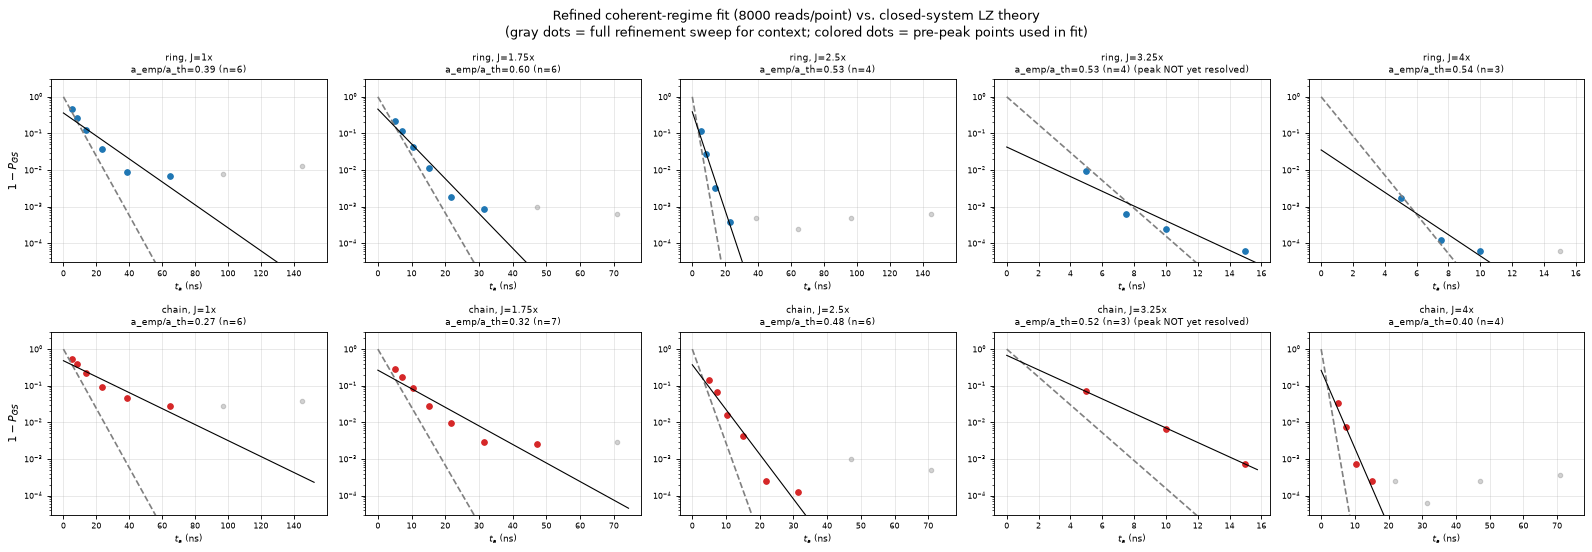


topo        J  n_fit   a_theory  a_empirical   ratio  note
ring     1.00      6    0.18653      0.07218   0.387  
ring     1.75      6    0.36521      0.21872   0.599  
ring     2.50      4    0.58982      0.31033   0.526  
ring     3.25      4    0.87563      0.46395   0.530  peak not yet resolved
ring     4.00      3    1.23281      0.66644   0.541  
chain    1.00      6    0.18653      0.05018   0.269  
chain    1.75      7    0.36521      0.11674   0.320  
chain    2.50      6    0.58982      0.28117   0.477  
chain    3.25      3    0.87563      0.45626   0.521  peak not yet resolved
chain    4.00      4    1.23281      0.48919   0.397  

All 10 ratios < 1.0: True  (mean=0.46, range=[0.27, 0.60])


In [22]:
# Phase 2 (refinement): 8000 reads/point instead of exploratory's 1000, and
# targeted specifically at each (topology, J) combo's coherent window --
# 6 log-spaced points from 5 ns (the hardware's true fast-anneal floor) up
# to the 1000-read "first local min" ceiling, PLUS 2 points beyond that
# ceiling (1.5x, 2.25x) to check whether it was an undershoot from 1000-read
# noise rather than the true turning point. For the 3 combos with no
# resolvable rise at all in the exploratory pass (J>=3.25x saturated even
# at 7.5 ns), 4 near-minimum probes (5/7.5/10/15 ns) instead.
# See experiments/advantage2_lz_crossover/points_refine_ORIGINAL_backup.json and
# results/refinement_ringchain_original.csv (67/68 points -- one submission failed
# and was skipped, logged, not retried). results/refinement.csv itself now holds the
# extended 35-topology campaign (sections 16.3-16.4).
REFINE_RESULTS_PATH = (
    r"c:\Users\andre\OneDrive\Documentos\GitHub\SEAQT-quantum-annealing-evolution"
    r"\experiments\advantage2_lz_crossover\results\refinement_ringchain_original.csv"
)
refine_results = pd.read_csv(REFINE_RESULTS_PATH)
print(f"Loaded {len(refine_results)} refinement measurements (8000 reads each)")

# Re-declared here (self-contained cell) -- same schedule/theory machinery as before
ADVANTAGE2_SCHEDULE_PATH = (
    r"C:\Users\andre\OneDrive\Documentos\Maestría\Julich\codigos"
    r"\09-1312A-N_Advantage2_system1_annealing_schedule.xlsx"
)
schedule_hw = load_schedule(ADVANTAGE2_SCHEDULE_PATH, sheet_name="Fast-Annealing Schedule")
# King et al. Eq. 4: b = (Gamma(s_c)/hbar) / (J'/J - Gamma'/Gamma). The schedule columns are
# A(s)/h and B(s)/h in GHz (linear frequency), so Gamma/hbar in rad/ns carries a factor 2*pi
# (J_cal only enters through J'/J, which is scale-free).
Gamma_hw = lambda s: 2 * np.pi * schedule_hw.A(s) / 2.0
Jcal_hw = lambda s: schedule_hw.B(s) / 2.0
eps = 1e-5

def a_theory_for(s_c):
    Gp = (Gamma_hw(s_c + eps) - Gamma_hw(s_c - eps)) / (2 * eps)
    Jp = (Jcal_hw(s_c + eps) - Jcal_hw(s_c - eps)) / (2 * eps)
    b = Gamma_hw(s_c) / (Jp / Jcal_hw(s_c) - Gp / Gamma_hw(s_c))
    return 2 * np.pi**3 * b / 6**2  # N_QUBITS=6

FLOOR = 0.5 / 8000
MIN_FIT_PTS = 3

def first_local_min(y):
    """Index of the FIRST local minimum -- see sec. 16's earlier note on
    why global-min is the wrong search here."""
    for i in range(len(y) - 1):
        if y[i + 1] >= y[i]:
            return i
    return len(y) - 1  # still decreasing at the last point -- true peak not resolved even here

fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=False)
summary_rows = []
for row, topo in enumerate(["ring", "chain"]):
    for col, jm in enumerate(j_multiples_hw):
        ax = axes[row, col]
        s = refine_results[(refine_results.topology == topo) & (refine_results.j_multiple == jm)] \
            .sort_values("t_anneal_ns").reset_index(drop=True)
        if len(s) == 0:
            ax.set_title(f"{topo}, J={jm:g}x\n(no data)", fontsize=9)
            continue
        one_minus = np.clip(1 - s.p_ground.values, FLOOR, None)
        peak_idx = first_local_min(one_minus)
        peak_unresolved = peak_idx == len(one_minus) - 1 and one_minus[peak_idx] < one_minus[max(peak_idx - 1, 0)]
        s_c = s.s_c.iloc[0]
        a_th = a_theory_for(s_c)

        t_all = s.t_anneal_ns.values
        ax.semilogy(t_all, one_minus, "o", color="tab:gray", alpha=0.35, markersize=4)
        t_pre, y_pre = t_all[:peak_idx + 1], one_minus[:peak_idx + 1]
        ax.semilogy(t_pre, y_pre, "o", color="tab:blue" if topo == "ring" else "tab:red", markersize=5)
        t_th = np.linspace(0, t_all.max() * 1.05, 100)
        ax.semilogy(t_th, np.exp(-a_th * t_th), "--", color="gray", label=f"theory a={a_th:.3f}")

        n_fit = len(t_pre)
        if n_fit >= MIN_FIT_PTS:
            slope, intercept = np.polyfit(t_pre, np.log(y_pre), 1)
            a_emp = -slope
            ax.semilogy(t_th, np.exp(intercept) * np.exp(-a_emp * t_th), "-", color="black", linewidth=1)
            ratio = a_emp / a_th
            summary_rows.append((topo, jm, n_fit, a_th, a_emp, ratio, peak_unresolved))
            flag = " (peak NOT yet resolved)" if peak_unresolved else ""
            title_extra = f"\na_emp/a_th={ratio:.2f} (n={n_fit}){flag}"
        else:
            summary_rows.append((topo, jm, n_fit, a_th, None, None, peak_unresolved))
            title_extra = f"\nonly {n_fit} pt(s) -- no fit"

        ax.set_title(f"{topo}, J={jm:g}x{title_extra}", fontsize=8.5)
        ax.set_xlabel("$t_a$ (ns)", fontsize=8)
        if col == 0:
            ax.set_ylabel("$1-P_{GS}$")
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.3)
        ax.set_ylim(3e-5, 3)  # hardware floor is 0.5/8000; the steeper (2*pi-corrected) theory line would otherwise stretch the axis

fig.suptitle("Refined coherent-regime fit (8000 reads/point) vs. closed-system LZ theory\n"
             "(gray dots = full refinement sweep for context; colored dots = pre-peak points used in fit)")
fig.tight_layout(); plt.show()

print(f"\n{'topo':6s} {'J':>6s} {'n_fit':>6s} {'a_theory':>10s} {'a_empirical':>12s} {'ratio':>7s}  note")
for topo, jm, n_fit, a_th, a_emp, ratio, unresolved in summary_rows:
    note = "peak not yet resolved" if unresolved else ""
    if a_emp is not None:
        print(f"{topo:6s} {jm:6.2f} {n_fit:6d} {a_th:10.5f} {a_emp:12.5f} {ratio:7.3f}  {note}")
    else:
        print(f"{topo:6s} {jm:6.2f} {n_fit:6d} {a_th:10.5f} {'--':>12s} {'--':>7s}  (not enough points)")

ratios = [r[5] for r in summary_rows if r[5] is not None]
print(f"\nAll {len(ratios)} ratios < 1.0: {all(r < 1.0 for r in ratios)}  "
      f"(mean={np.mean(ratios):.2f}, range=[{min(ratios):.2f}, {max(ratios):.2f}])")


**Units correction (2026-09-19).** The schedule columns are `A(s)/h`, `B(s)/h` in GHz (a linear frequency; see the "About" sheet of the export), but the first version of this section -- and the simulations behind it -- used them directly as angular frequencies ($\hbar=1$), missing a factor $2\pi$ in both the Hamiltonian and King et al.'s $b=\Gamma/\hbar/(\dots)$. Everything below uses $H_{\mathrm{ang}}=2\pi H_{\mathrm{GHz}}$: $a_{\text{theory}}$ grows by exactly $2\pi$, the hardware numbers do not change. That reverses the sign of the headline finding of the earlier version ("hardware faster than closed-system theory in 10/10, by 1.7-3.8x"), which was a units artifact.

**A much cleaner result after refinement.** Phase 1 (1000 reads/point) gave noisy, inconsistent ratios (0.07-0.59 with the corrected units; 0.41-3.70 as first reported), plus one outright wrong fit from a noise-driven false "peak". Phase 2 (8000 reads/point, `points_refine_ORIGINAL_backup.json`, targeted at each combo's coherent window plus 2 points *beyond* the 1000-read ceiling to check it wasn't an undershoot) resolves all 10 (topology, $J$) combinations -- including the 3 that had zero usable signal before -- and gives a consistent, one-sided answer:

$$a_{\text{empirical}} < a_{\text{theory}} \text{ in all 10 cases: } a_{\text{emp}}/a_{\text{theory}} = 0.27\text{-}0.60\ \ (\text{mean} \approx 0.46)$$

i.e. **real hardware reaches the ground state 1.7-3.7x more slowly than the closed-system Landau-Zener formula predicts**, across the entire coupling range tested and in both topologies (ring: 0.39-0.60, chain: 0.27-0.52). The two "beyond the ceiling" points per combo were worth adding: they showed the 1000-read boundary was almost exactly right for `ring` at $J$=1x/1.75x, meaningfully *too early* for `chain, J=1.75x` (true window extends to ~47 ns, not 31 ns), and revealed that `ring, J=2.5x`'s apparent 1000-read improvement out to 64 ns was itself a statistical fluctuation -- the real peak is at 23 ns. Two combinations (`ring`/`chain` $J$=3.25x) are *still* improving at the largest $t_a$ we tested (15 ns) even with 8000 reads -- their true coherent window extends past what this refinement covered, so their fitted $a_{\text{empirical}}$ should be read as a lower bound on the true decay rate, not a converged value.

**What this means physically, stated carefully**: the closed-system Landau-Zener formula (Eq. 8) has no free parameters and no coupling to an environment, so it is the fastest a coherent two-level picture can go; that real hardware falls short of it by a factor $\sim2$ is the direction expected when an environment adds noise -- not a puzzle, but a quantitative target: how much of that shortfall a dissipative model can account for. Sections 16.1 and 16.4 put the same data against SEAQT's own exact 6-qubit closed simulation (not just the two-level formula), which is the fair reference for the chain and for every other topology.


### 16.1 Comparing against SEAQT itself (Stage 1, phase a: ring/chain, unitary, no dissipator yet)

Section 16's refined fit shows real hardware reaching the ground state *more slowly* than King et al.'s closed-system two-level formula in all 10 (topology, $J$) combinations ($a_{\text{emp}}/a_{\text{theory}}=0.27$-$0.60$). Before reading anything into that, two checks against SEAQT's own **exact, unitary** 6-qubit simulation (no dissipator at all yet):

1. **Does the simulation reproduce the analytic formula where the formula is valid?** On the ring (a periodic chain, exactly King's geometry) SEAQT-unitary/theory should be $\approx1$ -- a test of the integration, the schedule and the units.
2. **Does the hardware-vs-formula gap persist against the exact closed-system number?** The formula is itself an approximation (a projection onto the instantaneous two-level crossing near $s_c$, derived for periodic boundaries), so the exact simulation is the cleaner reference, and the only one available for the open chain.

Method: uses the exact `(s_c, j_dimensionless, t_anneal_ns)` triples already recorded for all 67 points of the original ring/chain refinement (reused, never re-derived -- see `experiments/advantage2_lz_crossover/README.md`'s "Reuse, don't recompute, s_c" note). `H(t)` is built from the real Advantage2 fast-anneal schedule via `seaqt.dwave.hamiltonian_nqubit` (with the $2\pi$ conversion), the initial state is the equal mixture over `H(0)`'s (possibly degenerate) ground states, propagated exactly with no dissipator; the observable is the probability that a $z$-basis readout at the end is a classical ground state (what the hardware counts). $a_{\text{empirical}}$ is extracted from each combo's SEAQT curve with the same `polyfit`, over the same coherent window as the hardware fit. It runs in about two minutes (`stage1_seaqt_unitary.py 1a`: state-vector propagation on a process pool; the first version, 67 density-matrix `evolve()` calls, took ~5.2 h) -- raw output in `experiments/advantage2_lz_crossover/results/stage1_seaqt_unitary.csv`.


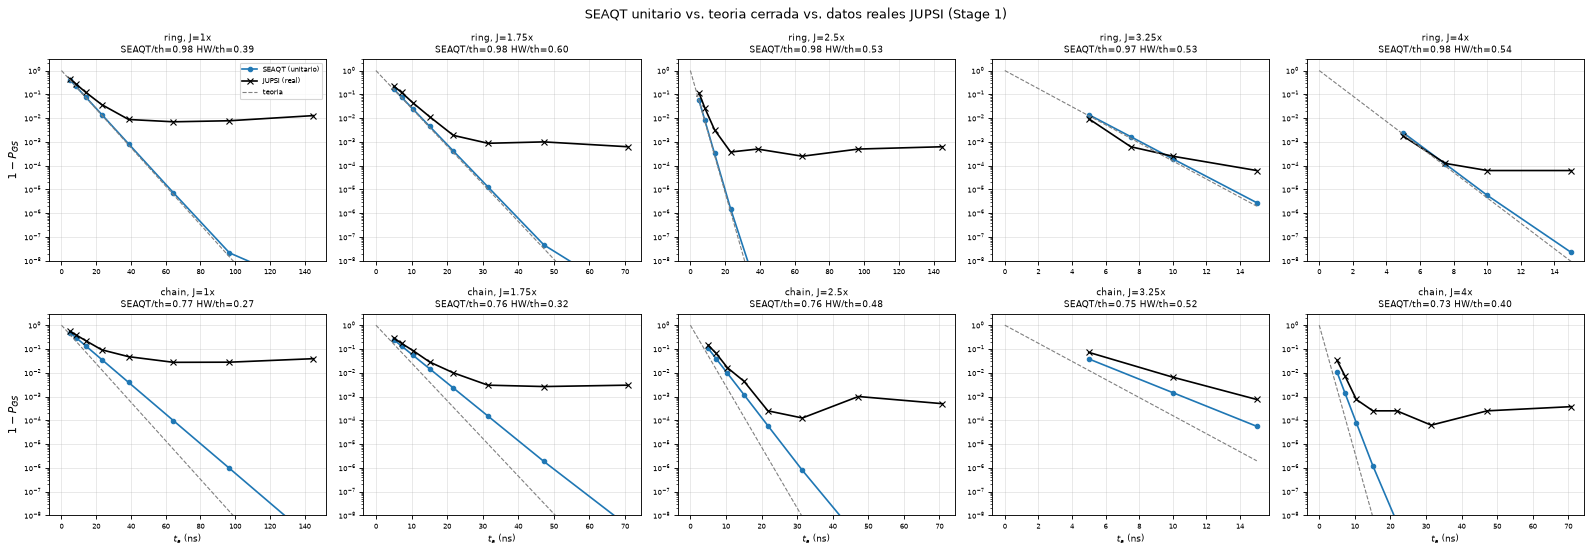

topo        J      a_th   a_seaqt  seaqt/th      a_hw   hw/th  hw/seaqt
ring     1.00    0.1865    0.1836     0.984    0.0722   0.387     0.393
ring     1.75    0.3652    0.3578     0.980    0.2187   0.599     0.611
ring     2.50    0.5898    0.5773     0.979    0.3103   0.526     0.538
ring     3.25    0.8756    0.8523     0.973    0.4640   0.530     0.544
ring     4.00    1.2328    1.2119     0.983    0.6664   0.541     0.550
chain    1.00    0.1865    0.1434     0.769    0.0502   0.269     0.350
chain    1.75    0.3652    0.2794     0.765    0.1167   0.320     0.418
chain    2.50    0.5898    0.4462     0.757    0.2812   0.477     0.630
chain    3.25    0.8756    0.6525     0.745    0.4563   0.521     0.699
chain    4.00    1.2328    0.9006     0.731    0.4892   0.397     0.543

SEAQT/theory: mean=0.866, range=[0.731,0.984]  (n=10)
HW/SEAQT-unitario: mean=0.528, range=[0.350,0.699]  (n=10)


In [43]:
# Stage 1: SEAQT unitary (exact 6-qubit closed dynamics) vs. closed-system
# theory vs. real hardware -- see 16.1 above for the methodology.
STAGE1_RESULTS_PATH = (
    r"c:\Users\andre\OneDrive\Documentos\GitHub\SEAQT-quantum-annealing-evolution"
    r"\experiments\advantage2_lz_crossover\results\stage1_seaqt_unitary.csv"
)
df_stage1 = pd.read_csv(STAGE1_RESULTS_PATH)
MIN_FIT_PTS_STAGE1 = 3

j_multiples_stage1 = sorted(df_stage1.j_multiple.unique())
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=False)
summary_stage1 = []
for row, topo in enumerate(["ring", "chain"]):
    for col, jm in enumerate(j_multiples_stage1):
        ax = axes[row, col]
        s = df_stage1[(df_stage1.topology == topo) & (df_stage1.j_multiple == jm)] \
            .sort_values("t_anneal_ns").reset_index(drop=True)
        t_all = s.t_anneal_ns.values
        a_th = s.a_theory.iloc[0]
        one_minus_seaqt = np.clip(1 - s.p_ground_seaqt_unitary.values, 1e-12, None)
        one_minus_hw = np.clip(1 - s.p_ground_hw.values, 0.5 / 8000, None)

        # The coherent window is a property of the experiment: where the HARDWARE curve is
        # still improving (first_local_min). Both curves are fitted over that same t_a range,
        # so their rates are directly comparable.
        peak_idx = first_local_min(one_minus_hw)
        t_pre, y_pre = t_all[:peak_idx + 1], one_minus_seaqt[:peak_idx + 1]
        if len(t_pre) >= MIN_FIT_PTS_STAGE1:
            slope, _ = np.polyfit(t_pre, np.log(y_pre), 1)
            a_seaqt = -slope
            ratio_seaqt_th = a_seaqt / a_th
        else:
            a_seaqt = ratio_seaqt_th = None

        t_pre_hw, y_pre_hw = t_all[:peak_idx + 1], one_minus_hw[:peak_idx + 1]
        if len(t_pre_hw) >= MIN_FIT_PTS_STAGE1:
            slope_hw, _ = np.polyfit(t_pre_hw, np.log(y_pre_hw), 1)
            a_hw = -slope_hw
            ratio_hw_th = a_hw / a_th
            ratio_hw_seaqt = a_hw / a_seaqt if a_seaqt else None
        else:
            a_hw = ratio_hw_th = ratio_hw_seaqt = None

        summary_stage1.append((topo, jm, a_th, a_seaqt, ratio_seaqt_th, a_hw, ratio_hw_th, ratio_hw_seaqt))

        ax.semilogy(t_all, one_minus_seaqt, "o-", color="tab:blue", ms=4, label="SEAQT (unitario)")
        ax.semilogy(t_all, one_minus_hw, "x-", color="black", ms=6, label="JUPSI (real)")
        t_th = np.linspace(0, t_all.max(), 100)
        ax.semilogy(t_th, np.exp(-a_th * t_th), "--", color="gray", lw=1, label="teoria")
        title = f"{topo}, J={jm:g}x"
        if ratio_seaqt_th: title += f"\nSEAQT/th={ratio_seaqt_th:.2f}"
        if ratio_hw_th: title += f" HW/th={ratio_hw_th:.2f}"
        ax.set_title(title, fontsize=8)
        ax.tick_params(labelsize=6.5)
        ax.grid(alpha=0.3)
        ax.set_ylim(1e-8, 3)
        if col == 0:
            ax.set_ylabel("$1-P_{GS}$")
        if row == 1:
            ax.set_xlabel("$t_a$ (ns)", fontsize=8)

axes[0, 0].legend(fontsize=6.5)
fig.suptitle("SEAQT unitario vs. teoria cerrada vs. datos reales JUPSI (Stage 1)")
fig.tight_layout()
plt.show()

print(f"{'topo':6s} {'J':>6s} {'a_th':>9s} {'a_seaqt':>9s} {'seaqt/th':>9s} {'a_hw':>9s} {'hw/th':>7s} {'hw/seaqt':>9s}")
for topo, jm, a_th, a_seaqt, r_st, a_hw, r_ht, r_hs in summary_stage1:
    a_seaqt_s = f"{a_seaqt:.4f}" if a_seaqt else "--"
    r_st_s = f"{r_st:.3f}" if r_st else "--"
    a_hw_s = f"{a_hw:.4f}" if a_hw else "--"
    r_ht_s = f"{r_ht:.3f}" if r_ht else "--"
    r_hs_s = f"{r_hs:.3f}" if r_hs else "--"
    print(f"{topo:6s} {jm:6.2f} {a_th:9.4f} {a_seaqt_s:>9s} {r_st_s:>9s} {a_hw_s:>9s} {r_ht_s:>7s} {r_hs_s:>9s}")

seaqt_th_ratios = [r[4] for r in summary_stage1 if r[4] is not None]
hw_seaqt_ratios = [r[7] for r in summary_stage1 if r[7] is not None]
print(f"\nSEAQT/theory: mean={np.mean(seaqt_th_ratios):.3f}, range=[{min(seaqt_th_ratios):.3f},{max(seaqt_th_ratios):.3f}]  (n={len(seaqt_th_ratios)})")
print(f"HW/SEAQT-unitario: mean={np.mean(hw_seaqt_ratios):.3f}, range=[{min(hw_seaqt_ratios):.3f},{max(hw_seaqt_ratios):.3f}]  (n={len(hw_seaqt_ratios)})")

**With the units fixed, the exact closed-system simulation reproduces the analytic theory on the ring, and real hardware runs at roughly half its rate.**

- **Ring**: SEAQT-unitary/theory = 0.973-0.984 (mean 0.980) at all five $J$ -- the integration, the schedule and the $2\pi$ are consistent with King et al.'s zero-parameter formula, which is derived for exactly this geometry.
- **Chain**: 0.731-0.769 (mean 0.753) -- a real, systematic ~25% deficit, but an *expected, understood* one: Eq. 8 is derived for periodic boundary conditions and isn't strictly valid for an open chain (16.2 shows how much of it is a location effect). Not a bug.
- **The number that matters most**: HW/SEAQT-unitary (the cleanest comparison, since it doesn't inherit the chain formula's known bias) is **below 1 in all 10 combinations, mean 0.53, range 0.35-0.70**. Real hardware reaches the ground state ~1.4-2.9x more slowly than the exact closed 6-qubit dynamics -- the direction expected for an open system whose environment adds noise, and a moderate effect: coherent evolution already accounts for about half of the observed rate at every coupling tested.

**Reading the plot.** With no dissipator, the LZ formula is a straight line on these semilog axes, $1-P_{GS}=e^{-a t_a}$, and the exact SEAQT curve (blue) does follow it: on the ring it runs parallel to the dashed line over 6-8 decades ($1-P_{GS}$ from 0.4 down to $\sim10^{-8}$), with a slope 2% smaller (ratio 0.98), so the exact points sit slightly above the line -- by a factor up to ~1.5 at the smallest values. The chain's slope is ~25% smaller (0.75), the open-boundary effect above. Below $\sim10^{-8}$ the curve flattens, but that is the resolution of the integrator ($\sim10^{-9}$ at the tolerance used, `rtol=1e-12`), not physics: an earlier version of this figure, computed with `rtol=1e-9`, showed a spurious floor of $10^{-7}$-$10^{-6}$ that grew with $t_a$ (accumulated norm error) and made the blue points appear to bend away from the theory line at long $t_a$. None of this touches the hardware comparison: the hardware plateaus near $10^{-2}$.

(The first version of this section, computed without the $2\pi$, concluded the opposite -- "hardware outperforms even the exact closed simulation, HW/SEAQT mean 3.31x". That was a units artifact, not physics.)

What remains is whether SEAQT's *dissipative* prediction can account for the remaining factor $\sim2$. The Stage 2 attempt (fitting one relaxation time `tau` of `local_seaqt_dissipator_n` to `ring, J=1x` and testing it, frozen, on the other 9 combinations -- see `experiments/advantage2_lz_crossover/README.md`) was run under the old units, so its conclusions (the dissipator saturating short of the target rate) no longer stand: there $H$ was a factor $2\pi$ too small against the bath temperature, and the target rate sat on the wrong side of the closed-system one. It has to be redone. The target is now a dissipator that *lowers* the decay rate relative to unitary evolution, whereas the fixed-temperature bath term cools the system and raises the ground-state population. (Redone in 16.5, with a bath that freezes out and an integrator that keeps $\rho$ positive: it reproduces the hardware's late-time floor but not the coherent-regime gap.)


### 16.2 King's approximate $s_c$ vs. the true minimum-gap point

Section 16.1's chain deviation (SEAQT-unitary/theory = 0.731-0.769) was
attributed to King et al.'s formula not being strictly valid for an open
chain -- true, but worth checking directly rather than leaving as an
assumption: $s_c$ itself (from `Gamma(s_c)=J_cal(s_c)*|J|`, a
perturbative/2-level approximation) might not sit exactly where the real
64-level spectrum's gap is smallest. Checked by diagonalizing the full
$H(s)$ and sweeping $s$.

**A subtlety first**: $H(s)$ commutes with the global spin-flip parity
$P=\sigma_x^{\otimes 6}$ for every $s$ (the driver is built from $\sigma_x$,
so trivially commutes with it; the coupling term is invariant under
flipping *all* spins at once, since every $\sigma_z^i\sigma_z^j$ product is
unchanged). The $s=0$ ground state ($|+\rangle^{\otimes 6}$) sits exactly
in the $P{=}{+}1$ sector, and since $P$ is exactly conserved, the system
can never leave it. A naive full-spectrum sort of all 64 eigenvalues is
misleading here: near $s=1$ the two classical ground configurations
(all-up/all-down, this experiment's ferromagnetic sign) are not themselves
$P$ eigenstates -- their symmetric combination is $P{=}{+}1$ (reachable)
and antisymmetric is $P{=}{-}1$ (dynamically unreachable). A naive sort
picks up that unreachable "ghost" as a near-degenerate second level whose
splitting from the true ground state closes smoothly toward zero well
before $s=1$ -- ordinary tunneling-splitting physics between the two
classical configurations, unrelated to the Landau-Zener avoided crossing,
and it swamps the real signal unless projected out first. Fixed by
projecting $H(s)$ onto the 32-dimensional $P{=}{+}1$ subspace before
diagonalizing.

P shape: (64, 64), n(P=+1)=32, n(P=-1)=32

topo       J  <P>(gs0)  s_c(King)   s_min  delta_s
ring    1.00   +1.0000     0.4597  0.4627  +0.0030
ring    1.75   +1.0000     0.4243  0.4266  +0.0024
ring    2.50   +1.0000     0.3964  0.3977  +0.0013
ring    3.25   +1.0000     0.3716  0.3737  +0.0021
ring    4.00   +1.0000     0.3481  0.3496  +0.0015
chain   1.00   +1.0000     0.4597  0.4771  +0.0174
chain   1.75   +1.0000     0.4243  0.4435  +0.0192
chain   2.50   +1.0000     0.3964  0.4146  +0.0182
chain   3.25   +1.0000     0.3716  0.3929  +0.0213
chain   4.00   +1.0000     0.3481  0.3713  +0.0232

topo   mean delta_s: ring=+0.0020  chain=+0.0199

topo       J ratio(King) ratio(s_min)
ring    1.00       0.984        1.044
ring    1.75       0.980        1.023
ring    2.50       0.979        1.000
ring    3.25       0.973        1.004
ring    4.00       0.983        1.002
chain   1.00       0.769        1.088
chain   1.75       0.765        1.090
chain   2.50       0.757        1.030
cha

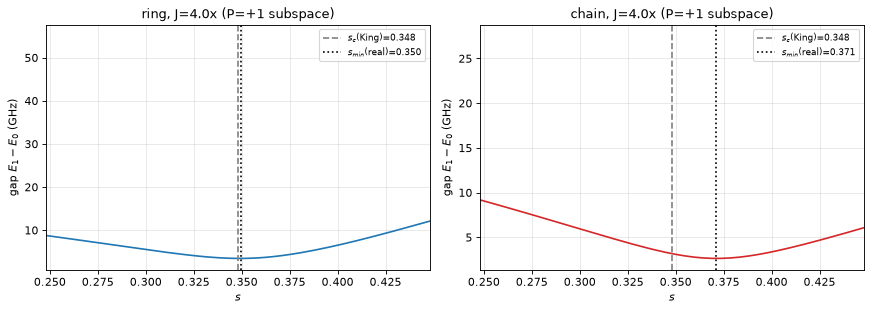

In [44]:
# 16.2: true minimum-gap location (P=+1 projection) vs. King's s_c,
# and a location-sensitivity check on a_theory itself.
sigma_x_1q = np.array([[0, 1], [1, 0]], dtype=complex)
P_parity = np.array([[1]], dtype=complex)
for _ in range(6):
    P_parity = np.kron(P_parity, sigma_x_1q)
w_p, v_p = np.linalg.eigh(P_parity)
V_plus = v_p[:, w_p > 0]  # 64x32, orthonormal basis of the P=+1 sector
print(f"P shape: {P_parity.shape}, n(P=+1)={np.sum(w_p>0)}, n(P=-1)={np.sum(w_p<0)}")

def build_h_J_162(topology, j_dimensionless, n=6):
    # Same (h=0, uniform-weight edges) construction as
    # experiments/advantage2_lz_crossover/config.py's build_h_J, inlined
    # here to keep this cell self-contained (this notebook never imports
    # that experiment's config module directly -- see 16's own re-declarations).
    if topology == "ring":
        edges = {(i, (i + 1) % n): j_dimensionless for i in range(n)}
    else:
        edges = {(i, i + 1): j_dimensionless for i in range(n - 1)}
    return {i: 0.0 for i in range(n)}, edges


combos_162 = refine_results[["topology", "j_multiple"]].drop_duplicates().values.tolist()
S_GRID_162 = np.linspace(0.02, 0.98, 400)

gap_curves_162 = {}
rows_162 = []
for topology, jm in combos_162:
    sub = refine_results[(refine_results.topology == topology) & (refine_results.j_multiple == jm)]
    j_dimless = sub.j_dimensionless.iloc[0]
    s_c_king = sub.s_c.iloc[0]
    h162, J162 = build_h_J_162(topology, j_dimless)
    H_fn = hamiltonian_nqubit(schedule_hw, h=list(h162.values()), J=J162, t_anneal=1.0)

    w0, v0 = np.linalg.eigh(H_fn(0.0))
    p_expect = np.real(v0[:, 0].conj() @ P_parity @ v0[:, 0])

    gaps = np.array([
        np.diff(np.linalg.eigvalsh(V_plus.conj().T @ H_fn(s) @ V_plus)[:2])[0] / (2 * np.pi)  # rad/ns -> GHz (E/h)
        for s in S_GRID_162
    ])
    idx_min = int(np.argmin(gaps))
    s_min_true = float(S_GRID_162[idx_min])
    if jm == 4.0:
        gap_curves_162[topology] = (S_GRID_162, gaps, s_c_king, s_min_true)

    a_th_king = a_theory_for(s_c_king)
    a_th_real = a_theory_for(s_min_true)

    s1 = df_stage1[(df_stage1.topology == topology) & (df_stage1.j_multiple == jm)].sort_values("t_anneal_ns")
    t162 = s1.t_anneal_ns.values
    one_minus_162 = np.clip(1 - s1.p_ground_seaqt_unitary.values, 1e-12, None)
    idx162 = first_local_min(np.clip(1 - s1.p_ground_hw.values, 0.5 / 8000, None))  # same window as 16.1
    slope162, _ = np.polyfit(t162[:idx162 + 1], np.log(one_minus_162[:idx162 + 1]), 1)
    a_seaqt = -slope162

    rows_162.append({
        "topology": topology, "j_multiple": jm, "p_expect_gs0": p_expect,
        "s_c_king": s_c_king, "s_min_true": s_min_true, "delta_s": s_min_true - s_c_king,
        "a_theory_king": a_th_king, "a_theory_real": a_th_real, "a_seaqt": a_seaqt,
        "ratio_king": a_seaqt / a_th_king, "ratio_real": a_seaqt / a_th_real,
    })

df_162 = pd.DataFrame(rows_162)
print(f"\n{'topo':6s} {'J':>5s} {'<P>(gs0)':>9s} {'s_c(King)':>10s} {'s_min':>7s} {'delta_s':>8s}")
for _, r in df_162.iterrows():
    print(f"{r.topology:6s} {r.j_multiple:5.2f} {r.p_expect_gs0:+9.4f} {r.s_c_king:10.4f} "
          f"{r.s_min_true:7.4f} {r.delta_s:+8.4f}")

print(f"\n{'topo':6s} mean delta_s: ring={df_162[df_162.topology=='ring'].delta_s.mean():+.4f}  "
      f"chain={df_162[df_162.topology=='chain'].delta_s.mean():+.4f}")

print(f"\n{'topo':6s} {'J':>5s} {'ratio(King)':>11s} {'ratio(s_min)':>12s}")
for _, r in df_162.iterrows():
    print(f"{r.topology:6s} {r.j_multiple:5.2f} {r.ratio_king:11.3f} {r.ratio_real:12.3f}")

for topo in ["ring", "chain"]:
    sub = df_162[df_162.topology == topo]
    dev_king = abs(1 - sub.ratio_king.mean())
    dev_real = abs(1 - sub.ratio_real.mean())
    frac = 100 * (dev_king - dev_real) / dev_king
    print(f"\n{topo}: mean ratio(King)={sub.ratio_king.mean():.3f}  mean ratio(s_min)={sub.ratio_real.mean():.3f}  "
          f"-> location explains {frac:.1f}% of the deviation from 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, topo in zip(axes, ["ring", "chain"]):
    s_grid, gaps, s_c_king, s_min = gap_curves_162[topo]
    ax.plot(s_grid, gaps, "-", color="tab:blue" if topo == "ring" else "tab:red")
    ax.axvline(s_c_king, ls="--", color="gray", label=f"$s_c$(King)={s_c_king:.3f}")
    ax.axvline(s_min, ls=":", color="black", label=f"$s_{{min}}$(real)={s_min:.3f}")
    ax.set_xlim(s_c_king - 0.1, s_c_king + 0.1)
    ax.set_title(f"{topo}, J=4.0x (P=+1 subspace)")
    ax.set_xlabel("$s$")
    ax.set_ylabel("gap $E_1-E_0$ (GHz)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Location, not just functional form, explains most of chain's deviation.**

Sanity check first: $\langle P\rangle = +1.0000$ for the $s=0$ ground state
in all 10 combinations -- confirms the projection is doing the right thing.

- **Ring**: `s_min` is within ~0.001-0.003 of `s_c`(King) (mean +0.002) --
  essentially exact, as expected (King's derivation assumes a periodic chain, and the
  ring is exactly that).
- **Chain**: `s_min` is consistently *later* than `s_c`(King) by ~0.017-0.023
  (mean +0.020, same sign in all 5 $J$'s -- systematic, not noise) -- small in absolute
  $s$, but $\Gamma(s)$/$\mathcal{J}(s)$ are steep enough there that it's not
  a small effect on the energy scales themselves (see the two curves above:
  the true minimum for chain, $J{=}4.0$x, sits visibly past King's dashed
  line, while ring's true minimum sits right on top of it).

**The decisive number**: re-evaluating `a_theory` (the *same* formula, just
fed `s_min` instead of King's `s_c` -- a pure diagnostic, not a claim that
this is a "better King formula") moves the mean SEAQT/theory ratio from
0.753 to 1.055 for chain -- **the location error alone explains ~78% of
that topology's apparent disagreement with King's formula**, not the
`b(s_c)` coefficient's functional form. For ring both errors are already
small, so the same exercise (0.980 -> 1.015) matters much less in absolute
terms. King's formula itself should still always be *reported* at his own
`s_c` -- that's the quantity his derivation actually defines -- but for
understanding *why* chain looks different, the dominant driver turns out to
be squarely a location effect, not a breakdown of the LZ picture itself.

(This check compares the exact simulation with the formula only, so the units correction leaves
its conclusion unchanged; the absolute rates $a$ moved by $2\pi$ in both.)


### 16.3 Extending to native topologies and chip regions (exploratory phase)

Rather than only ring/chain, this widens
the sweep along three axes at once, all still 6 qubits, $h=0$:

- **More topologies, discovered rather than hand-picked** --
  `discover_native_topologies.py` randomly samples connected 6-qubit windows across
  the real chip and takes each window's actual induced subgraph as its native shape
  (a different philosophy than embedding an abstract target shape via minorminer).
  80 distinct isomorphism classes were found this way; **11** were hand-selected for
  the real sweep, spanning the full edge-count range found (5 to 11 edges out of 15
  possible), deliberately excluding the two classes that are literally ring/chain
  again (already covered above).
- **Chip regions, from the same mechanism, not a separate search** -- distinct
  windows that land on different physical qubits but turn out isomorphic become
  that shape's available regions automatically. **3 regions per shape** (chosen to
  minimize shared physical qubits between a shape's own regions), giving 33 new
  (topology, region) combinations.
- **Both signs of $J$, checked directly** -- not just for ring/chain (as section 16
  above does), but also for the two selected native shapes that turned out to show
  real classical ground-state degeneracy (frustration) under antiferromagnetic
  coupling but not ferromagnetic (verified directly via brute-force ground-state
  counting, not assumed from bipartiteness alone -- 3 of the 5 non-bipartite
  selected shapes stay non-degenerate even under AF; see
  `results/symmetry_classification.csv`).

The $t_{	ext{anneal}}$ grid is no longer shared across every combo either: each
(topology, $J$, sign) gets its own log-spaced grid, shifted by that combo's own
REAL many-body minimum gap (`check_true_crossing_point.py`, generalized from
section 16.2's machinery to all 35 topologies and both signs) rather than reusing
ring/chain's grid uninspected -- denser/larger-gap topologies get a grid shifted to
shorter $t_a$, sparser ones to longer, both still clipped to the hardware's real
$[5	ext{ ns}, 2	ext{ ms}]$ limits.

**Result: 215 (topology, $J$, sign) combos $	imes$ up to 12 $t_a$ points each =
2580 points, 1000 reads each, zero chain breaks, zero failed submissions.**

> **Caveat on the sign of $J$: which shapes have both signs, and what that does to the comparisons.**
>
> Both signs were run for **4 of the 13 shapes**: `ring` and `chain` (bipartite, so $J\to-J$ is a gauge transformation and the closed system predicts identical curves for the two signs) and the two frustrated native shapes `e6 c26` and `e8 c37` (under antiferromagnetic coupling they are physically different problems, with 6 and 4 classical ground states instead of 2). The other **nine native shapes were run only with the auto-picked sign** -- ferromagnetic ($J<0$), the sign with more hardware headroom. Six of them are bipartite (`e5 c0`, `e5 c1`, `e6 c15`, `e7 c16`, `e7 c25`, `e8 c32`), where AF and FM are gauge-equivalent in theory; three are non-bipartite without degeneracy (`e9 c54`, `e10 c66`, `e11 c59`), where AF is a genuinely different problem that was **not** measured.
>
> The design assumed the sign is irrelevant wherever the gauge equivalence holds, and used ring/chain to check it. **The hardware does not confirm that assumption**: at equal programmed $|J|$ the two signs of ring/chain differ by 0.012 per point on average (up to 0.08-0.10 at the shortest anneals; `stage1b_systematics.csv`), and at $J$=1x the RMS with respect to the closed system is about twice as large with the ferromagnetic sign as with the antiferromagnetic one in all four two-sign shapes (16.4). The closed system cannot produce that difference, so it is a property of the hardware (a sign-dependent control error or bias), not of the model, and it appears even in shapes without frustration. Consequences:
>
> - the nine single-sign shapes carry a sign-dependent systematic of this size that could not be measured shape by shape, and they all use the sign with the *larger* deviation;
> - the sign contrast in the figures is shown only where it was measured (ring, chain, `e6 c26`, `e8 c37`) -- not because those are the only shapes where it may matter;
> - above $J$=2.5x the antiferromagnetic sign reaches the chip's limit ($|J|=1$), so the two signs are different programmed problems there (16.4).
>
> Running the antiferromagnetic sign on the remaining nine shapes would close this gap; it was not done.

Loaded 2580 real hardware measurements -- 35 topologies (2 original + 33 native), 215 (topology, J, sign) combos
  chain_break_fraction: min=0.000, max=0.000  (0 everywhere)
  Zero failed submissions: 2580/2580 points saved


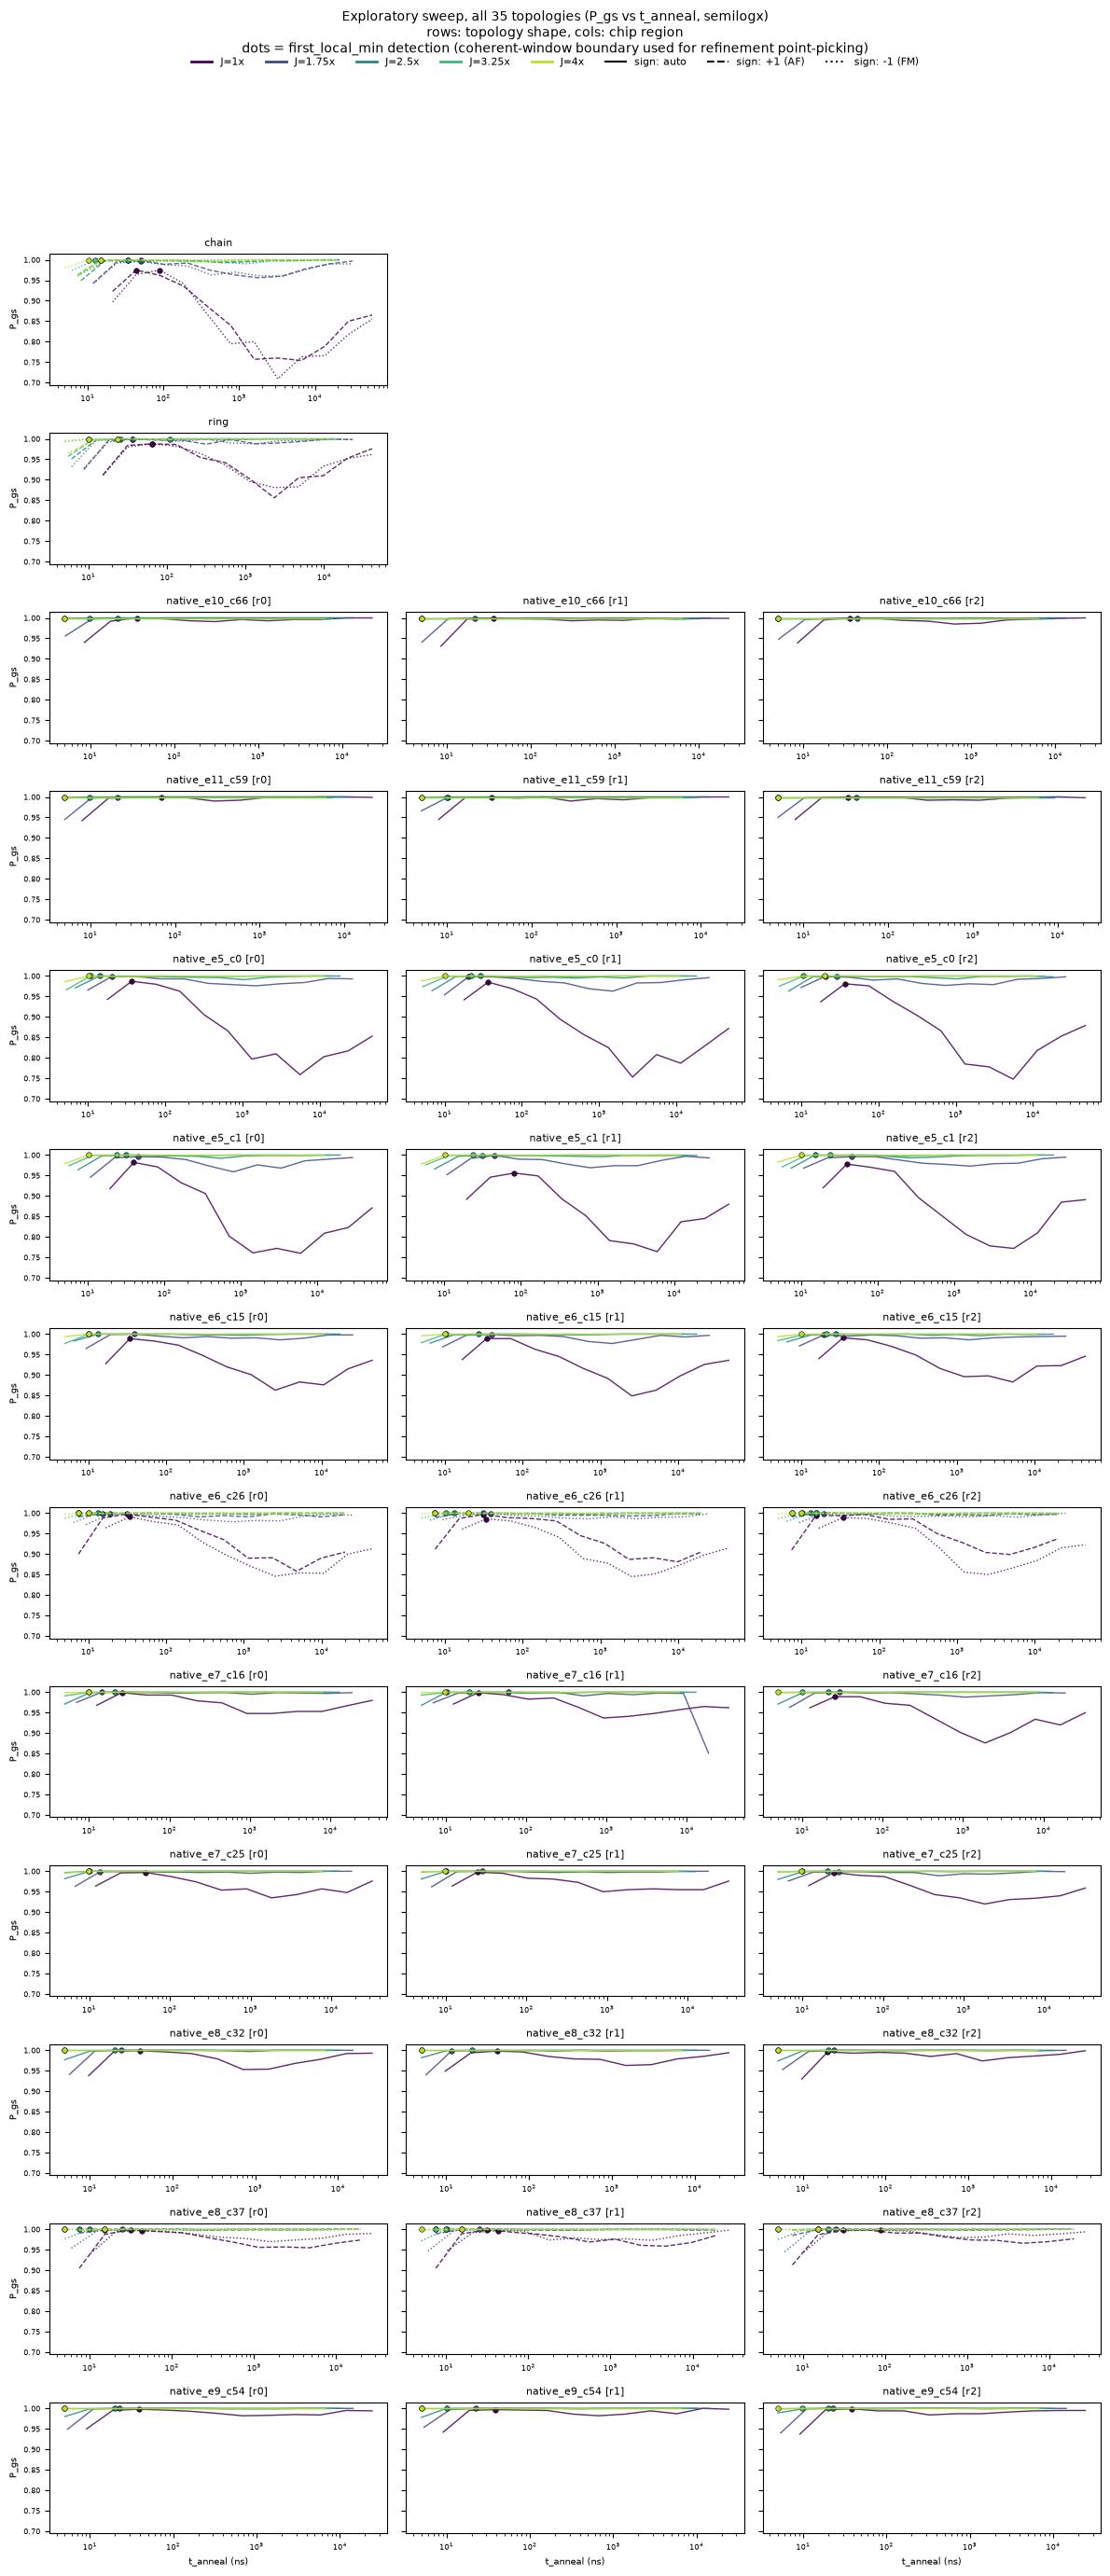

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

NATIVE_RESULTS_PATH = (
    r"c:\Users\andre\OneDrive\Documentos\GitHub\SEAQT-quantum-annealing-evolution"
    r"\experiments\advantage2_lz_crossover\results\exploratory.csv"
)
native_results = pd.read_csv(NATIVE_RESULTS_PATH)
native_results["j_sign"] = native_results["j_sign"].astype(str)
print(f"Loaded {len(native_results)} real hardware measurements -- "
      f"{native_results.topology.nunique()} topologies (2 original + 33 native), "
      f"{native_results.groupby(['topology','j_multiple','j_sign']).ngroups} (topology, J, sign) combos")
print(f"  chain_break_fraction: min={native_results.chain_break_fraction.min():.3f}, "
      f"max={native_results.chain_break_fraction.max():.3f}  (0 everywhere)")
print(f"  Zero failed submissions: {len(native_results)}/2580 points saved")


def first_local_min(y):
    for i in range(len(y) - 1):
        if y[i + 1] >= y[i]:
            return i
    return len(y) - 1


FLOOR = 0.5 / 1000  # exploratory num_reads


def shape_key(topology):
    if topology in ("ring", "chain"):
        return topology, "-"
    parts = topology.split("_")
    return "_".join(parts[:3]), parts[3]


native_results["topo_shape"], native_results["region"] = zip(*native_results.topology.map(shape_key))
shapes = sorted(native_results.topo_shape.unique(), key=lambda s: (s not in ("ring", "chain"), s))

J_MULTIPLES = [1.0, 1.75, 2.5, 3.25, 4.0]  # fixed, global order -- color index must NOT depend on
                                            # which J values a given panel happens to have, or the
                                            # same color would mean different J's in different panels
j_colors = dict(zip(J_MULTIPLES, plt.cm.viridis(np.linspace(0, 0.9, len(J_MULTIPLES)))))
sign_style = {"auto": "-", "+": "--", "-": ":"}

n_rows, n_cols = len(shapes), 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 2.1 * n_rows), sharex=False, sharey=True)

for i, shape in enumerate(shapes):
    sub_shape = native_results[native_results.topo_shape == shape]
    panel_regions = ["-"] if shape in ("ring", "chain") else ["r0", "r1", "r2"]
    for j in range(n_cols):
        ax = axes[i, j]
        if j >= len(panel_regions):
            ax.axis("off")
            continue
        region = panel_regions[j]
        sub = sub_shape[sub_shape.region == region]
        for jm in J_MULTIPLES:
            for sign in sub.j_sign.unique():
                g = sub[(sub.j_multiple == jm) & (sub.j_sign == sign)].sort_values("t_anneal_ns")
                if len(g) == 0:
                    continue
                one_minus = np.clip(1 - g.p_ground.values, FLOOR, None)  # still used for first_local_min
                ax.semilogx(g.t_anneal_ns, g.p_ground.values, sign_style.get(sign, "-"),
                            color=j_colors[jm], linewidth=1, alpha=0.85)
                idx = first_local_min(one_minus)
                ax.plot(g.t_anneal_ns.iloc[idx], g.p_ground.iloc[idx], "o", color=j_colors[jm],
                        markersize=4, markeredgecolor="black", markeredgewidth=0.4)
        ax.set_title(f"{shape}{'' if region == '-' else f' [{region}]'}", fontsize=8)
        ax.tick_params(labelsize=6)
        if i == n_rows - 1:
            ax.set_xlabel("t_anneal (ns)", fontsize=7)
        if j == 0:
            ax.set_ylabel("P_gs", fontsize=7)

# Legend: color = J multiple, line style = sign -- built from proxy handles since each
# color/style combination doesn't necessarily appear in every single panel.
from matplotlib.lines import Line2D
color_handles = [Line2D([0], [0], color=j_colors[jm], lw=2, label=f"J={jm:g}x") for jm in J_MULTIPLES]
style_handles = [Line2D([0], [0], color="black", lw=1.5, linestyle=ls, label=lbl)
                  for ls, lbl in [("-", "sign: auto"), ("--", "sign: +1 (AF)"), (":", "sign: -1 (FM)")]]
fig.legend(handles=color_handles + style_handles, loc="upper center", ncol=8, fontsize=8,
           bbox_to_anchor=(0.5, 0.995), frameon=False)

fig.suptitle("Exploratory sweep, all 35 topologies (P_gs vs t_anneal, semilogx)\n"
             "rows: topology shape, cols: chip region\n"
             "dots = first_local_min detection (coherent-window boundary used for refinement point-picking)",
             fontsize=10, y=1.01)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


floor P_gs: min=0.892  median=0.977  max=1.000
combos pinned exactly at P_gs=1.000 at the floor: 43/215 -- these hit first_local_min's edge case (idx=0): no interior coherent-rise peak to bracket, handled with 4 near-floor refinement probes instead of the usual 8-point window (see build_refinement_points.py)


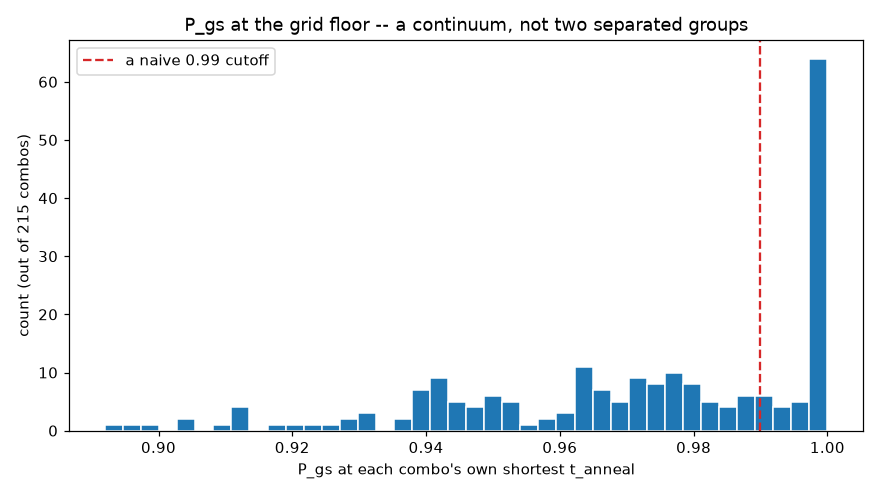

In [ ]:
floor_rows = native_results.loc[native_results.groupby(["topology", "j_multiple", "j_sign"]).t_anneal_ns.idxmin()]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(floor_rows.p_ground, bins=40, color="tab:blue", edgecolor="white")
ax.axvline(0.99, color="tab:red", linestyle="--", label="a naive 0.99 cutoff")
ax.set_xlabel("P_gs at each combo's own shortest t_anneal")
ax.set_ylabel("count (out of 215 combos)")
ax.set_title("P_gs at the grid floor -- a continuum, not two separated groups")
ax.legend()
fig.tight_layout()
plt.show()

print(f"floor P_gs: min={floor_rows.p_ground.min():.3f}  median={floor_rows.p_ground.median():.3f}  "
      f"max={floor_rows.p_ground.max():.3f}")
print(f"combos pinned exactly at P_gs=1.000 at the floor: {(floor_rows.p_ground == 1.0).sum()}/215 "
      f"-- these hit first_local_min's edge case (idx=0): no interior coherent-rise peak to bracket, "
      f"handled with 4 near-floor refinement probes instead of the usual 8-point window (see "
      f"build_refinement_points.py)")


**Two things worth checking before picking refinement points, and both hold up:**

1. **Is the "saturated vs. resolvable" split real, or an artifact of an arbitrary
   cutoff?** The histogram above answers this directly: it's a genuine continuum
   from 0.89 to ~0.99, but with a real, separate pile-up of 43/215 combos pinned
   *exactly* at $P_{GS}=1.000$ at their shortest $t_a$ -- not a smooth tail into
   1.0. Those 43 get the near-floor refinement treatment (4 probes at 5/7.5/10/15
   ns) instead of the usual 8-point window, since `first_local_min` has no interior
   point to bracket for them (see `build_refinement_points.py`).

2. **Does section 16's three-regime pattern (coherent rise -> anti-Kibble-Zurek dip
   -> thermal recovery) generalize, or was it a ring/chain-specific coincidence?**
   The grid above shows it's **universal** across every one of the 35 topologies --
   every single panel shows the same rise-dip-recovery shape -- but the *depth* of
   the dip tracks each topology's own true minimum gap (16.2's machinery): the
   sparsest shapes (chain, the two 5-edge native classes) show the deepest dips,
   the densest (10-11 edges) barely dip at all before saturating. `first_local_min`
   (the black-outlined dots above) correctly locates the end of the coherent-rise
   phase in every case checked by eye -- the same validated methodology from
   section 16, not a new algorithm.

**Refinement (8000 reads/point, `points_refine.json`, `build_refinement_points.py`)
was generated for all 215 combos (1548 points) and has since been run on the
hardware; its comparison with the exact closed-system simulation is in section 16.4.**

### 16.4 Stage 1, phase 2: SEAQT unitary vs. hardware on all 35 topologies (8000-read refinement)

Section 16.3 showed the extended sweep at 1000 reads/point. Its refinement -- 8000 reads/point at each combo's own coherent window (`build_refinement_points.py` -> `points_refine.json`, 1548 points over the same 215 (topology, $J$, sign) combos) -- has now been run, and this section compares it with SEAQT.

Stage 1 splits in two. **Phase a** (16.1) is ring/chain, where King et al.'s analytic Eq. 8 exists: it validated the exact closed-system simulation against that analytic theory (ring: 0.97-0.98). **Phase 2** (this section) extends to every other topology, where Eq. 8 does *not* carry over (it assumes a translation-invariant 1D chain), so the exact simulation is itself the closed-system reference and there is no analytic curve to fit -- the comparison is point by point, with no exponential fit.

- **Simulation**: as in 16.1 -- real `H(t)` from the Advantage2 fast-anneal schedule with the $2\pi$ conversion, equal mixture over $H(0)$'s ground states, exact unitary propagation, no dissipator, no free parameters. The observable is the probability that a $z$-basis readout at the end is a *classical* ground state of the programmed Ising problem -- what the hardware's $P_{GS}$ counts. (Projecting on the quantum ground eigenspace of $H(t_a)$ instead undercounts the two frustrated shapes, `native_e6_c26` and `native_e8_c37` with antiferromagnetic sign, whose classical degeneracy is slightly lifted by the residual driver.) The number of classical ground states equals the hardware's `n_ground_states` in every combo.
- **Metrics per combo**: RMS$(P^{hw}_{GS}-P^{sim}_{GS})$; how many points lie more than $2\sigma$ (binomial shot noise of the hardware estimate) below/above the simulation; `dP_tmin`, the difference $P^{hw}-P^{sim}$ at the combo's shortest $t_a$; the infidelity ratio $R=(1-P^{hw})/(1-P^{sim})$ there; and $t_{dev}$, the first $t_a$ where the hardware infidelity exceeds twice the simulation's by more than $2\sigma$.
- **Saturated combos**: when the closed system already exceeds 99% at the shortest anneal, both curves sit near 1 over the whole measured window, and a small RMS is a geometric coincidence of two flat lines, not evidence of agreement. Those combos are marked and left out of every median below: 100 of the 215 -- none at $J\leq1.75$x, and 27, 33 and 40 of 43 at 2.5x, 3.25x and 4x (they include all 43 combos the exploratory phase found pinned at $P_{GS}=1$ at the first grid point). Shapes run with both signs (chain, ring, `e6 c26`, `e8 c37`) are shown separately for the ferromagnetic (FM, $J<0$) and antiferromagnetic (AF, $J>0$) sign; in the curves of the second figure, dashed lines and open squares are $J<0$.
- **Reproduce**: `experiments/advantage2_lz_crossover/stage1_seaqt_unitary.py 1b` (~16 min on 11 cores), then `analyze_stage1.py 1b`; the resulting CSVs are read below.


1548 points, 215 (topology, J, sign) combos, 35 topologies, 13 shapes
classical ground-state count, simulation vs hardware: equal in 215/215 combos
saturated combos (closed system > 99% at the shortest anneal): 100 of 215; per J: 1x 0/43, 1.75x 0/43, 2.5x 27/43, 3.25x 33/43, 4x 40/43
RMS(P_hw - P_sim), informative (115 combos): median=0.0157  IQR=[0.0112, 0.0242]  max=0.0598
RMS(P_hw - P_sim), saturated   (100 combos): median=0.0013  IQR=[0.0001, 0.0042]  max=0.0104
RMS(P_hw - P_sim), all         (215 combos): median=0.0081  IQR=[0.0016, 0.0166]  max=0.0598
points where hardware is > 2 sigma BELOW the simulation, informative: 746/920 (81%);  ABOVE: 6/920 (0.7%)
points where hardware is > 2 sigma BELOW the simulation, all        : 939/1548 (61%);  ABOVE: 17/1548 (1.1%)


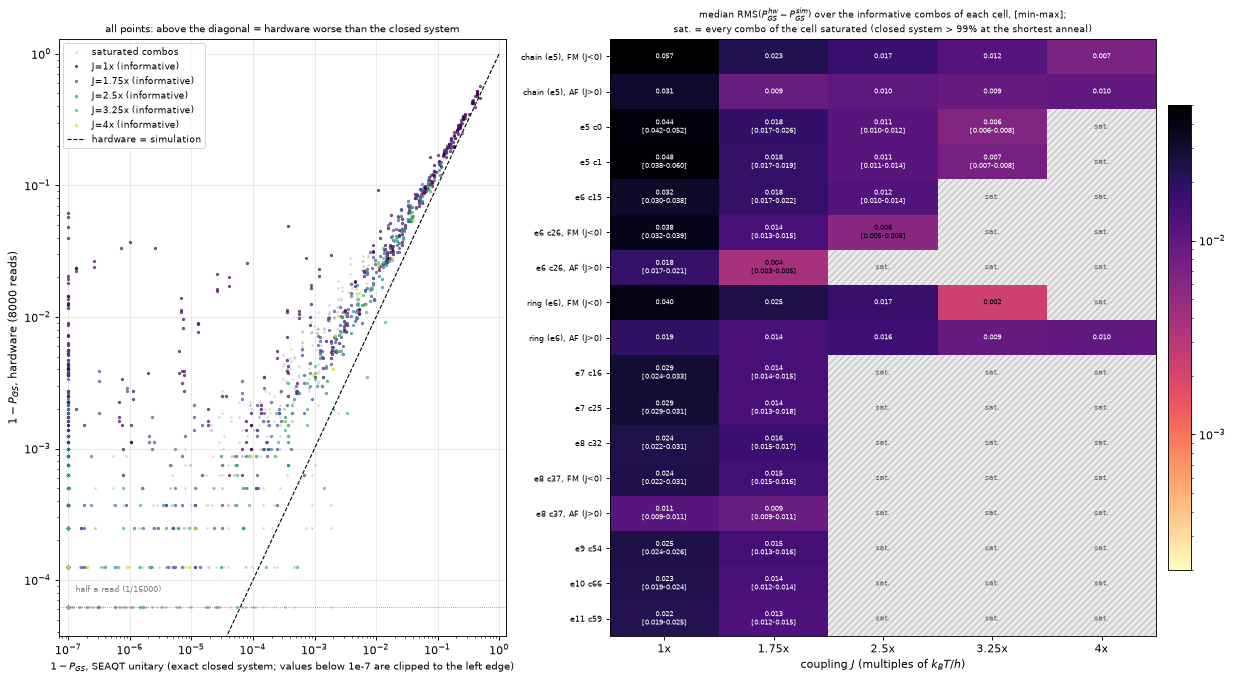

In [51]:
# 16.4: Stage 1, phase 2 -- exact closed-system SEAQT vs. the 8000-read refinement, all 215 combos.
# The simulation itself (stage1_seaqt_unitary.py 1b) and the per-combo metrics (analyze_stage1.py 1b)
# are run outside the notebook; their CSVs are read here.
import pandas as pd
from matplotlib.colors import LogNorm

RES_DIR = REPO_ROOT / "experiments" / "advantage2_lz_crossover" / "results"
s1b = pd.read_csv(RES_DIR / "stage1b_seaqt_unitary.csv")
s1b["j_sign"] = s1b.j_sign.astype(str)
summ = pd.read_csv(RES_DIR / "stage1b_summary.csv")
summ["j_sign"] = summ.j_sign.astype(str)
syst = pd.read_csv(RES_DIR / "stage1b_systematics.csv")

# "Saturated" combos: the closed system already exceeds 99% at the shortest anneal, so both curves sit near 1 over the
# whole measured window and the RMS cannot show agreement or disagreement (a trivial geometric coincidence of two flat
# lines). They are marked, and left out of every median below.
s1b = s1b.merge(summ[["topology", "j_multiple", "j_sign", "saturated"]], on=["topology", "j_multiple", "j_sign"], how="left")
inf = summ[~summ.saturated]

HW_FLOOR_16_4, SIM_FLOOR_16_4 = 0.5 / 8000, 1e-7
J_MULT = [1.0, 1.75, 2.5, 3.25, 4.0]
J_COL = dict(zip(J_MULT, plt.cm.viridis(np.linspace(0, 0.9, len(J_MULT)))))


def _n_edges(shape):
    return {"ring": 6, "chain": 5}.get(shape) or int(shape.split("_")[1][1:])


def _label(shape):
    if shape in ("ring", "chain"):
        return f"{shape} (e{_n_edges(shape)})"
    return shape.replace("native_", "").replace("_", " ")


shapes = sorted(summ["shape"].unique(), key=lambda s: (_n_edges(s), s))
TWO_SIGN = [s for s in shapes if {"+", "-"} <= set(summ[summ["shape"] == s].j_sign)]  # chain, ring, e6 c26, e8 c37


def row_groups():
    """(label, mask over `summ`) for every table/heatmap row. Shapes run with both signs are split by sign
    (FM = J<0, AF = J>0) so the sign asymmetry and the frustrated shapes are not averaged away."""
    rows = []
    for s in shapes:
        if s in TWO_SIGN:
            rows.append((f"{_label(s)}, FM (J<0)", (summ["shape"] == s) & (summ.j_sign == "-")))
            rows.append((f"{_label(s)}, AF (J>0)", (summ["shape"] == s) & (summ.j_sign == "+")))
        else:
            rows.append((_label(s), summ["shape"] == s))
    return rows


def _f(v):
    return f"{v:.3f}" if v >= 1e-3 else (f"{v:.4f}" if v >= 1e-4 else "<1e-4")


tot = int(summ.n_pts.sum())
sat = summ[summ.saturated]
print(f"{len(s1b)} points, {len(summ)} (topology, J, sign) combos, {s1b.topology.nunique()} topologies, {len(shapes)} shapes")
print(f"classical ground-state count, simulation vs hardware: equal in "
      f"{int((summ.n_ground_hw == summ.n_ground_sim).sum())}/{len(summ)} combos")
print(f"saturated combos (closed system > 99% at the shortest anneal): {len(sat)} of {len(summ)}; per J: "
      + ", ".join(f"{j:g}x {int(g.saturated.sum())}/{len(g)}" for j, g in summ.groupby("j_multiple")))
for name, g in (("informative", inf), ("saturated", sat), ("all", summ)):
    print(f"RMS(P_hw - P_sim), {name:11s} ({len(g):3d} combos): median={g.rms.median():.4f}  "
          f"IQR=[{g.rms.quantile(.25):.4f}, {g.rms.quantile(.75):.4f}]  max={g.rms.max():.4f}")
for name, g in (("informative", inf), ("all", summ)):
    tb, ta_, tt = int(g.n_hw_below.sum()), int(g.n_hw_above.sum()), int(g.n_pts.sum())
    print(f"points where hardware is > 2 sigma BELOW the simulation, {name:11s}: {tb}/{tt} ({100 * tb / tt:.0f}%);  "
          f"ABOVE: {ta_}/{tt} ({100 * ta_ / tt:.1f}%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 8.6), gridspec_kw={"width_ratios": [1, 1.3]})
gs_ = s1b[s1b.saturated]
ax1.plot(np.clip(1 - gs_.p_ground_seaqt_unitary, SIM_FLOOR_16_4, 1), np.clip(1 - gs_.p_ground_hw, HW_FLOOR_16_4, 1),
         ".", ms=3, alpha=0.25, color="0.6", label="saturated combos")
for jm in J_MULT:
    g = s1b[(s1b.j_multiple == jm) & ~s1b.saturated]
    ax1.plot(np.clip(1 - g.p_ground_seaqt_unitary, SIM_FLOOR_16_4, 1), np.clip(1 - g.p_ground_hw, HW_FLOOR_16_4, 1),
             ".", ms=4, alpha=0.6, color=J_COL[jm], label=f"J={jm:g}x (informative)")
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.plot([SIM_FLOOR_16_4, 1], [SIM_FLOOR_16_4, 1], "k--", lw=1, label="hardware = simulation")
ax1.axhline(HW_FLOOR_16_4, color="gray", lw=0.7, ls=":")
ax1.text(1.3e-7, HW_FLOOR_16_4 * 1.3, "half a read (1/16000)", fontsize=7, color="gray")
ax1.set_xlim(SIM_FLOOR_16_4 * 0.7, 1.3)
ax1.set_ylim(HW_FLOOR_16_4 * 0.6, 1.3)
ax1.set_xlabel("$1-P_{GS}$, SEAQT unitary (exact closed system; values below 1e-7 are clipped to the left edge)", fontsize=9)
ax1.set_ylabel("$1-P_{GS}$, hardware (8000 reads)")
ax1.set_title("all points: above the diagonal = hardware worse than the closed system", fontsize=9)
ax1.legend(fontsize=8, loc="upper left")
ax1.grid(alpha=0.3)

rows = row_groups()
Z = np.full((len(rows), len(J_MULT)), np.nan)
TXT = [[""] * len(J_MULT) for _ in rows]
for i, (lab, mask) in enumerate(rows):
    for j, jm in enumerate(J_MULT):
        cell = summ[mask & (summ.j_multiple == jm)]
        ci = cell[~cell.saturated]
        if len(ci) == 0:
            TXT[i][j] = "sat."
            continue
        Z[i, j] = ci.rms.median()
        t = _f(Z[i, j])
        if len(ci) > 1:
            t += f"\n[{_f(ci.rms.min())}-{_f(ci.rms.max())}]"
        if len(ci) < len(cell):
            t += f"\n{len(ci)}/{len(cell)} inf."
        TXT[i][j] = t
cmap = plt.cm.magma_r.copy()
cmap.set_bad("0.92")
im = ax2.imshow(np.ma.masked_invalid(Z), aspect="auto", cmap=cmap, norm=LogNorm(vmin=2e-4, vmax=5e-2))
for i in range(len(rows)):
    for j in range(len(J_MULT)):
        if np.isnan(Z[i, j]):
            ax2.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="////", edgecolor="0.75", lw=0))
            ax2.text(j, i, "sat.", ha="center", va="center", fontsize=7, color="0.45")
        else:
            ax2.text(j, i, TXT[i][j], ha="center", va="center", fontsize=6.3, color="white" if Z[i, j] > 6e-3 else "black")
ax2.set_xticks(range(len(J_MULT)))
ax2.set_xticklabels([f"{j:g}x" for j in J_MULT])
ax2.set_yticks(range(len(rows)))
ax2.set_yticklabels([lab for lab, _ in rows], fontsize=7.5)
ax2.set_xlabel("coupling $J$ (multiples of $k_BT/h$)")
ax2.set_title("median RMS$(P^{hw}_{GS}-P^{sim}_{GS})$ over the informative combos of each cell, [min-max];\n"
              "sat. = every combo of the cell saturated (closed system > 99% at the shortest anneal)", fontsize=8.5)
fig.colorbar(im, ax=ax2, fraction=0.04, pad=0.02)
fig.tight_layout()
plt.show()


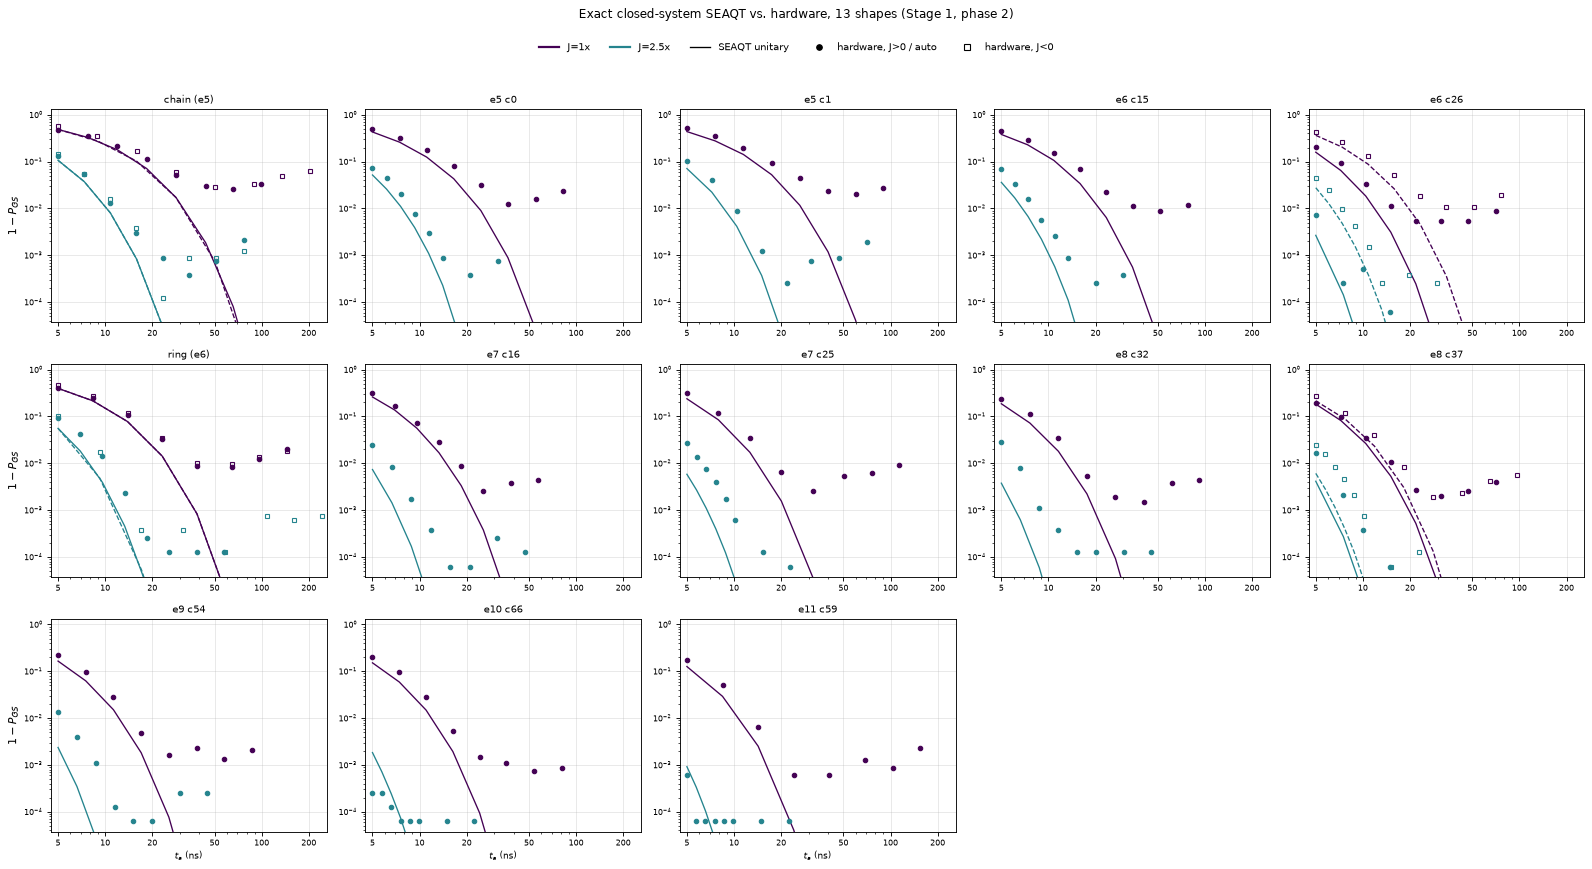

In [52]:
# 16.4: 1-P_GS vs t_a, one panel per shape (region r0 for the native shapes), J = 1x and 2.5x.
# Lines = exact closed-system SEAQT, markers = hardware (8000 reads); open markers / dashed = J < 0
# (ferromagnetic sign) where both signs were run, filled / solid = J > 0 or the auto-picked sign.
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter, ScalarFormatter

J_SHOW = [1.0, 2.5]
fig, axes = plt.subplots(3, 5, figsize=(20, 10.5))
for ax, shape in zip(axes.ravel(), shapes):
    topo = shape if shape in ("ring", "chain") else f"{shape}_r0"
    sub = s1b[s1b.topology == topo]
    for jm in J_SHOW:
        for sign, ls, mk in [("auto", "-", "o"), ("+", "-", "o"), ("-", "--", "s")]:
            g = sub[(sub.j_multiple == jm) & (sub.j_sign == sign)].sort_values("t_anneal_ns")
            if len(g) == 0:
                continue
            col = J_COL[jm]
            ax.loglog(g.t_anneal_ns, np.clip(1 - g.p_ground_seaqt_unitary, SIM_FLOOR_16_4, 1), ls, color=col, lw=1.2)
            ax.loglog(g.t_anneal_ns, np.clip(1 - g.p_ground_hw, HW_FLOOR_16_4, 1), mk, color=col, ms=4,
                      mfc="none" if sign == "-" else col)
    ax.set_title(_label(shape), fontsize=9)
    ax.set_ylim(HW_FLOOR_16_4 * 0.6, 1.3)
    ax.set_xlim(4.5, 260)
    ax.set_xticks([5, 10, 20, 50, 100, 200])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(shapes):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("$1-P_{GS}$")
for ax in axes[-1, :]:
    ax.set_xlabel("$t_a$ (ns)", fontsize=8)
handles = [Line2D([0], [0], color=J_COL[j], lw=2, label=f"J={j:g}x") for j in J_SHOW] + [
    Line2D([0], [0], color="k", lw=1.2, label="SEAQT unitary"),
    Line2D([0], [0], color="k", marker="o", lw=0, ms=5, label="hardware, J>0 / auto"),
    Line2D([0], [0], color="k", marker="s", lw=0, ms=5, mfc="none", label="hardware, J<0"),
]
fig.legend(handles=handles, loc="upper center", ncol=5, fontsize=9, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Exact closed-system SEAQT vs. hardware, 13 shapes (Stage 1, phase 2)", y=1.03, fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


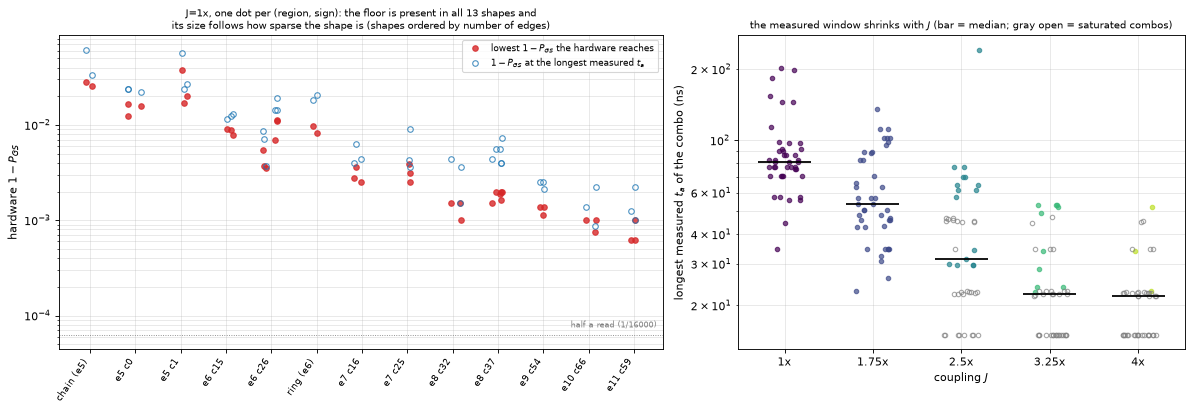

J=1x, median over combos of each shape: lowest hardware 1-P_GS | 1-P_GS at the longest t_a:
            floor_hw  om_last
shape                        
chain (e5)    0.0269   0.0474
e5 c0         0.0159   0.0238
e5 c1         0.0200   0.0268
e6 c15        0.0089   0.0124
e6 c26        0.0062   0.0115
ring (e6)     0.0089   0.0193
e7 c16        0.0027   0.0044
e7 c25        0.0031   0.0042
e8 c32        0.0015   0.0036
e8 c37        0.0019   0.0050
e9 c54        0.0014   0.0025
e10 c66       0.0010   0.0014
e11 c59       0.0006   0.0012
J=1x combos whose lowest hardware 1-P_GS is >= 0.3%: 22/43; whose last point is >= 0.3%: 33/43
median longest measured t_a (ns) by J: 1x 81, 1.75x 54, 2.5x 32, 3.25x 22, 4x 22


In [53]:
# 16.4: the hardware floor in every shape at J=1x (left), and how long the measured window is at each J (right).
last = s1b.sort_values("t_anneal_ns").groupby(["topology", "j_multiple", "j_sign"]).tail(1)
last = last.assign(om_last=1 - last.p_ground_hw)[["topology", "j_multiple", "j_sign", "om_last"]]
fl = summ.merge(last, on=["topology", "j_multiple", "j_sign"])
j1 = fl[fl.j_multiple == 1.0]
rng = np.random.default_rng(0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})
for k, s in enumerate(shapes):
    g = j1[j1["shape"] == s]
    x = k + rng.uniform(-0.18, 0.18, len(g))
    ax1.plot(x, g.floor_hw, "o", color="tab:red", ms=5, alpha=0.8, label="lowest $1-P_{GS}$ the hardware reaches" if k == 0 else None)
    ax1.plot(x, g.om_last, "o", mfc="none", color="tab:blue", ms=5, alpha=0.8, label="$1-P_{GS}$ at the longest measured $t_a$" if k == 0 else None)
ax1.axhline(HW_FLOOR_16_4, color="gray", ls=":", lw=0.8)
ax1.text(len(shapes) - 0.5, HW_FLOOR_16_4 * 1.2, "half a read (1/16000)", fontsize=7, color="gray", ha="right")
ax1.set_yscale("log")
ax1.set_xticks(range(len(shapes)))
ax1.set_xticklabels([_label(s) for s in shapes], rotation=55, ha="right", fontsize=8)
ax1.set_ylabel("hardware $1-P_{GS}$")
ax1.set_title("J=1x, one dot per (region, sign): the floor is present in all 13 shapes and\n"
              "its size follows how sparse the shape is (shapes ordered by number of edges)", fontsize=9)
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3, which="both")

for k, jm in enumerate(J_MULT):
    g = summ[summ.j_multiple == jm]
    x = k + rng.uniform(-0.2, 0.2, len(g))
    m = g.saturated.values
    ax2.plot(x[~m], g.t_max.values[~m], "o", color=J_COL[jm], ms=4, alpha=0.7)
    ax2.plot(x[m], g.t_max.values[m], "o", mfc="none", color="0.5", ms=4, alpha=0.7)
    ax2.hlines(g.t_max.median(), k - 0.3, k + 0.3, color="k", lw=1.6)
ax2.set_yscale("log")
ax2.set_xticks(range(len(J_MULT)))
ax2.set_xticklabels([f"{j:g}x" for j in J_MULT])
ax2.set_xlabel("coupling $J$")
ax2.set_ylabel("longest measured $t_a$ of the combo (ns)")
ax2.set_title("the measured window shrinks with $J$ (bar = median; gray open = saturated combos)", fontsize=9)
ax2.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

print("J=1x, median over combos of each shape: lowest hardware 1-P_GS | 1-P_GS at the longest t_a:")
print(j1.groupby("shape")[["floor_hw", "om_last"]].median().reindex(shapes).rename(index=_label).to_string(float_format=lambda x: f"{x:.4f}"))
print(f"J=1x combos whose lowest hardware 1-P_GS is >= 0.3%: {int((j1.floor_hw >= 0.003).sum())}/{len(j1)}; "
      f"whose last point is >= 0.3%: {int((j1.om_last >= 0.003).sum())}/{len(j1)}")
print("median longest measured t_a (ns) by J: " + ", ".join(f"{j:g}x {g.t_max.median():.0f}" for j, g in summ.groupby("j_multiple")))


In [54]:
# 16.4: summary tables, over the INFORMATIVE combos only (saturated ones say nothing about agreement).
# dP_tmin = P_hw - P_sim at each combo's shortest t_a; R_tmin = (1-P_hw)/(1-P_sim) there;
# t_dev = first t_a where hardware infidelity exceeds 2x the simulation's (beyond 2 sigma shot noise);
# floor_hw = lowest hardware infidelity reached (the 8000-read floor is 6e-5).
cols = ["rms", "dP_tmin", "R_tmin", "t_dev", "floor_hw"]
fmt = lambda x: f"{x:.4f}"
print("By coupling (median over informative combos; n = informative / total):")
t = inf.groupby("j_multiple")[cols].median()
t.insert(0, "n", [f"{len(inf[inf.j_multiple == j])}/{len(summ[summ.j_multiple == j])}" for j in t.index])
print(t.to_string(float_format=fmt))
print("\nBy shape and sign (median over informative combos; FM = J<0, AF = J>0; n = informative / total):")
rows_tab = []
for lab, mask in row_groups():
    g_inf = summ[mask & ~summ.saturated]
    rows_tab.append(pd.Series({**g_inf[cols].median().to_dict(), "n": f"{len(g_inf)}/{int(mask.sum())}"}, name=lab))
print(pd.DataFrame(rows_tab)[["n"] + cols].to_string(float_format=fmt))
print(f"\ncombos with a resolvable deviation (t_dev defined): {int(summ.t_dev.notna().sum())}/{len(summ)}")
print("\nHardware-only systematics -- measurements that share the same closed-system physics:")
for kind, g in syst.groupby("kind"):
    what = ("3 chip regions of the same native shape (isomorphic graphs)" if kind == "region"
            else "+J vs -J on ring/chain at equal programmed |J| (J <= 2.5x; gauge-equivalent: identical closed-system prediction)")
    pooled = (g.mean_spread * g.n_common_t).sum() / g.n_common_t.sum()
    print(f"  {kind:6s} {len(g):3d} groups, {int(g.n_common_t.sum()):3d} common t_a points: pooled mean |dP| = {pooled:.4f}, "
          f"worst single point = {g.max_spread.max():.4f}   [{what}]")


By coupling (median over informative combos; n = informative / total):
                n    rms  dP_tmin  R_tmin   t_dev  floor_hw
j_multiple                                                 
1.00        43/43 0.0285  -0.0576  1.2270 13.8976    0.0031
1.75        43/43 0.0147  -0.0368  1.6445  6.9967    0.0002
2.50        16/43 0.0112  -0.0266  1.4978  7.1926    0.0002
3.25        10/43 0.0076  -0.0189  1.8939  5.2272    0.0001
4.00         3/43 0.0099  -0.0214  1.6799  5.9907    0.0001

By shape and sign (median over informative combos; FM = J<0, AF = J>0; n = informative / total):
                          n    rms  dP_tmin  R_tmin   t_dev  floor_hw
chain (e5), FM (J<0)    5/5 0.0166  -0.0423  1.3968 10.7516    0.0002
chain (e5), AF (J>0)    5/5 0.0100  -0.0155  1.2039 13.2937    0.0004
e5 c0                 12/15 0.0147  -0.0334  1.3744 10.7623    0.0009
e5 c1                 12/15 0.0153  -0.0359  1.2681  9.9725    0.0011
e6 c15                 9/15 0.0179  -0.0443  1.3279 11.2312  

**Where there is a transition to predict, the exact closed-system simulation -- with no free parameters -- predicts the hardware's $P_{GS}$ to about 2% (median RMS 0.016) and almost always from above.**

- **What can be compared**: 100 of the 215 combos are saturated (see above), so only the other 115 say anything about agreement. On those 115 the median RMS$(P^{hw}-P^{sim})$ is 0.016 (interquartile range 0.011-0.024, maximum 0.06), and 0.029 at $J$=1x; on the saturated ones it is 0.0013, which only says that both curves are near 1. (Pooling all 215 gives 0.008, an average of the two populations that overstates the agreement.) The number of classical ground states agrees with the hardware's in all 215 combos.
- **One-sided**: on the informative combos the hardware lies more than $2\sigma$ *below* the closed-system prediction at 81% of the points (746/920) and above it at 0.7% (6/920); over all points the figures are 61% and 1%, diluted by the saturated combos. Real hardware is the closed system minus a systematic loss -- never a gain -- which is what an environment that only adds noise would do, and the same direction as the ring/chain result of 16.1.
- **Dependence on coupling**: among the informative combos the median RMS falls from 0.029 at $J$=1x and 0.015 at 1.75x to 0.011, 0.008 and 0.010 at 2.5x, 3.25x and 4x (16, 10 and 3 informative combos there), and $P^{hw}-P^{sim}$ at the shortest anneal from $-0.058$ to about $-0.02$. The RMS of 0.001-0.002 that pooling all combos gives at high $J$ was saturation, not agreement.
- **Where the hardware departs**: at the shortest anneal times the hardware infidelity is within a factor 1.2-1.6 of the simulation's ($J\leq1.75$x) and the gap opens with $t_a$: at $J$=1x the hardware first exceeds twice the simulated infidelity around 14 ns.
- **The floor is universal, and its size follows the shape** (third figure, left): at $J$=1x the hardware never gets close to the closed system in any of the 13 shapes. The lowest $1-P_{GS}$ it reaches is ~2.7% for the chain and ~0.9% for the ring, 0.3% for the 7-edge shapes, 0.15% for 8-9 edges and 0.06-0.10% for 10-11 edges -- always above the 6e-5 read floor. In 22 of the 43 combos at $J$=1x it never gets below 0.3%.
- **Signs**: split by sign, the RMS with the ferromagnetic sign is about twice that with the antiferromagnetic one at $J$=1x in all four shapes run with both -- chain 0.057/0.031, ring 0.040/0.019, `e6 c26` 0.038/0.018, `e8 c37` 0.024/0.011 (FM/AF). It happens in the ring and the chain, which are not frustrated, so it looks like a hardware sign asymmetry rather than frustration physics. Only four shapes have both signs (see the caveat in 16.3), so this asymmetry cannot be checked -- or corrected for -- in the other nine, which use the ferromagnetic sign only. In the two frustrated shapes the simulation separates the two signs (second figure) and the hardware follows in the same direction; their RMS is similar to the ring's.
- **Floor on how finely any model can be judged**: the 3 chip regions of a native shape, which run the same graph, differ by only 0.003 per point on average (worst single point 0.04), and within a heatmap cell the spread of the RMS across regions is small (median max-min 0.0025) -- the chip is homogeneous at this level. The $\pm J$ asymmetry on ring/chain, whose two signs are gauge-equivalent and therefore have identical closed-system predictions, is larger: 0.012 per point on average over the 34 points where both signs were measured at the same $t_a$ and the same programmed $|J|$, dominated by the shortest anneals (up to 0.08 for the ring at $J$=1x, 0.10 for the chain at 5 ns). At 3.25x and 4x the antiferromagnetic sign reaches the chip's limit ($|J|=1$) while the ferromagnetic one does not, so the two signs are different problems there and are excluded (each row is still simulated with the $J$ actually programmed). At the weakest coupling this is comparable to the model-vs-hardware RMS, so no single-parameter model can be judged much more finely than that.

**What this does and does not say.** Together with 16.1, the annealer's populations at $t_a$ = 5-240 ns follow the unitary, coherent evolution closely across many topologies -- consistent with a largely coherent annealer, with a modest dissipative loss on top. It does not yet *prove* coherence: that needs a decoherent null model (e.g. full dephasing in the instantaneous eigenbasis) that fails where the unitary succeeds, which has not been run. Limits of this section: the measured window of each combo is its own coherent window (6 points up to the 1000-read ceiling plus 2 beyond), so it is short where the transition is fast -- its longest anneal is 81 ns at $J$=1x and 22 ns at 4x (third figure, right; 15 ns for the dense shapes at 3.25x and 4x) -- and the plateau that dominates the long-$t_a$ end of the low-$J$ curves is not sampled at high $J$: those combos are both saturated and truncated. Also, the anti-Kibble-Zurek dip and thermal recovery seen in 16.3 lie outside the window (a closed system cannot reproduce them by construction), and the model uses six ideal logical qubits -- no embedding, no per-qubit or per-coupler control error (`results/qubit_calibration_snapshot.csv` holds the calibration data for a later refinement).

**For Stage 2**: because the hardware sits *below* the closed system, a dissipator has to lower $P_{GS}$ in the coherent window. Relaxation to an external bath (`bath_dissipator` on the full 64x64 $\rho$, 20 mK) only raises it there: for a bath that never freezes out, no $\tau$ improves the RMS over the unitary limit (`calibrate_tau_bath.py`, and again with a positivity-preserving integrator down to $\tau=10$ ns in 16.5). Section 16.5 adds a freeze-out of the relaxation: it predicts the hardware's late-time floor to about one decade instead of five, and leaves the coherent-window gap untouched.


### 16.5 Stage 2: SEAQT with dissipation -- two dissipators against the hardware

Sections 16.1-16.4 compared the *closed-system* SEAQT with the hardware. This section adds dissipation, following the advisor's suggestion, with **two dissipators calibrated on the same data with the same rule and tested on the same combinations**, so they can be compared directly (last figures of the section):

| | **Global bath with freeze-out** | **Local SEAQT dissipator** |
|---|---|---|
| Equation | $\dot\rho=-i[H,\rho]-\frac{\beta}{2\tau}\,w(s)\,\{F,\rho\}$, $F=(H-\langle H\rangle)-\beta^{-1}(S_{op}-\langle S_{op}\rangle)$, $S_{op}=-\ln\rho$: the relaxation-to-a-bath of sections 2-8 applied to the whole $64\times64$ $\rho$; $w(s)=1/(1+e^{(s-s_f)/0.02})$ switches it off after the freeze-out point $s_f$ | `local_seaqt_dissipator_n` of sections 9-15: $-\sum_J\tau_J^{-1}\,D_J\otimes\rho_{\bar J}$, built from single-qubit partial traces, one constant $\tau$ on every qubit, no switch |
| Temperature | 20 mK, the measured one ($\beta=0.382$ ns) | an **effective** $T$: at 20 mK this model does not stay physical ($P_{GS}>1$), so $T$ is raised. That failure is the only reason for the value; it is not the chip's temperature (94.2 mK is the demo temperature already used in sections 6-15) |
| Fitted parameters | $\tau$ and $s_f$ (the switch width 0.02 is a fixed constant, never varied) | $T$ and $\tau$ |
| Initial state | Gibbs state of $H(0)$ at 20 mK (full rank; excited population $\sim10^{-11}$) | pure ground state of $H(0)$ |
| Positivity | guaranteed by construction (below) | **not guaranteed**: smallest eigenvalues of order $-10^{-4}$ to $-6\times10^{-4}$ along the valid trajectories, and $P_{GS}>1$ at low $T$ |
| Code | `calibrate_tau_freezeout.py`, `check_freezeout_direction.py` | `scan_local_dissipator_ring.py`, `run_local_dissipator_subsample.py` |

Both use the real Advantage2 fast-anneal Hamiltonian in rad/ns (with the $2\pi$) and the observable of the earlier sections, the classical-ground-state population. Besides the closed system, a **null model** is used as a control: unitary evolution from a Gibbs state at 94 mK, with no dissipator (`run_null_model_hotstart.py`). It starts with 1.8% excited population, which sets a floor $1-P_{GS}\approx1.5\times10^{-2}$ independent of $J$; a dissipator only explains something if it does better than merely starting hot.

**Metrics** (16.4's, per combination, then the median over combinations; $1-P_{GS}$ is floored at $0.5/8000$ for the hardware and at $10^{-9}$ for the models). The *whole-curve error* is the mean $|\log_{10}(\text{model}/\text{hardware})|$ of $1-P_{GS}$: every point weighs the same, so it rewards getting the order of magnitude of the small $1-P_{GS}$ of the floor. The *RMS* of $1-P_{GS}$ is linear and is dominated by the coherent regime, where $1-P_{GS}$ is large. The *coherent window* is the part of a combination's curve up to the hardware's first minimum of $1-P_{GS}$ and the *floor regime* the part after it (on the ring calibration, fixed cuts at $t_a\leq24$ ns and $t_a\geq38$ ns). The two families of metrics answer different questions and, as the results show, they do not rank the models in the same way. Calibration rule for both dissipators: minimise the whole-curve error subject to the whole-curve RMS being at most 1.1x the closed system's.

**Positivity of the global bath was an integrator artifact, not a property of the equation.** The equation has the form $\dot\rho = A\rho+\rho A^\dagger$ with $A=-iH-\frac{\beta}{2\tau}wF$ and $F$ Hermitian, so its exact solution is $\rho(t)=G(t)\rho_0G(t)^\dagger$ with $G$ invertible: a positive-definite $\rho_0$ stays positive definite for all time, and the trace is conserved -- as the advisor expected. What broke the earlier runs at $\tau\lesssim50$ ns was the integrator: `evolve` (RK45 on the *entries* of $\rho$) adds an error that is additive, so eigenvalues far below `atol` -- the Gibbs weights at 20 mK reach $10^{-30}$ -- drift negative, and once negative the floored logarithm makes them grow without bound. `evolve_bath_factorized` and `evolve_bath_split` integrate a factor instead ($\rho=\Gamma\Gamma^\dagger$, $\dot\Gamma=A\Gamma$), so $\rho$ is positive semidefinite with trace 1 *by construction*, whatever the step. (This concerns the bath equation only. The local dissipator is a different one -- a tensor-product term $D_J\otimes\rho_{\bar J}$ built from partial traces, not of the form $A\rho+\rho A^\dagger$ -- so the argument does not cover it; its positivity is checked run by run instead.)

In [55]:
# 16.5: what the factorized integrator changes. (1) The same ring, J=1x, 20 mK, bath on for the whole anneal (no freeze-out),
# constant tau: the earlier plain-RK45 log vs. the factorized runs. (2) A 3-qubit anneal, where both can be run in seconds.
import sys
import time
import pandas as pd
from seaqt import evolve_bath_split
from seaqt.operators import ising_hamiltonian

EXP_DIR = REPO_ROOT / "experiments" / "advantage2_lz_crossover"
RES_DIR = EXP_DIR / "results"

old = pd.read_csv(RES_DIR / "tau_calibration_ring1x_bath_log.csv")   # plain `evolve` (RK45 on rho's entries), rho0 = (1-eps)|psi0><psi0| + eps I/64
new = pd.read_csv(RES_DIR / "stage2_freezeout_log.csv")              # `evolve_bath_split`, rho0 = Gibbs(H(0))
old = old[np.isclose(old.eps, 1e-4)]
new = new[(new["set"] == "ring1x") & np.isinf(new.s_f)]
rows = []
for tau in (10.0, 100.0):
    for ta in (64.479, 96.718, 145.077):
        o = old[np.isclose(old.tau_ns, tau) & np.isclose(old.t_a_ns, ta, atol=1e-3)].iloc[0]
        n_ = new[np.isclose(new.tau_ns, tau) & np.isclose(new.t_a_ns, ta, atol=1e-3)].iloc[0]
        rows.append({"tau (ns)": tau, "t_a (ns)": ta,
                     "plain: status": o.status, "plain: 1-P_GS": 1 - o.p_gs, "plain: min eig": o.min_eig,
                     "factorized: 1-P_GS": 1 - n_.p_gs, "factorized: min eig": n_.min_eig})
print("6-qubit ring, J=1x, constant tau (no freeze-out), 20 mK -- 64x64 density matrix")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.3g}"))
allrun = pd.concat([pd.read_csv(RES_DIR / "stage2_freezeout_log.csv"), pd.read_csv(RES_DIR / "stage2_freezeout_heldout_log.csv")])
print(f"\nall {len(allrun)} factorized runs of this section (ring scan + the two 215-combo tests): "
      f"smallest eigenvalue over every trajectory {allrun.min_eig.min():+.1e}")

# (2) small system: 3 qubits, Gibbs initial state at beta=3 (energies in the same units), anneal of length 8
rng = np.random.default_rng(11)
h_loc = rng.normal(size=3)
Jc = {(0, 1): 0.9, (1, 2): -0.7, (0, 2): 0.4}
Hd, Hp = ising_hamiltonian(3, list(h_loc), Jc, A=1.0, B=0.0), ising_hamiltonian(3, list(h_loc), Jc, A=0.0, B=1.0)
T_A, BETA3 = 8.0, 3.0
H3 = lambda t: (1 - t / T_A) * 6.0 * Hd + (t / T_A) * 6.0 * Hp
rho3 = gibbs_state(H3(0.0), BETA3)
print("\n3 qubits (smallest initial eigenvalue ~1e-17; the trajectory's minimum eigenvalue should stay >= 0):")
for tau in (0.5, 2.0):
    res_p = evolve(rho3, hamiltonian=H3, t_span=(0, T_A), dissipator=lambda t, r, hh: bath_dissipator(r, hh, BETA3, tau),
                   n_points=40, rtol=1e-9, atol=1e-11)
    res_f = evolve_bath_split(rho3, hamiltonian=H3, t_span=(0, T_A), beta=BETA3, rate=1.0 / tau, dt=0.005, n_points=40)
    m_p = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_p.rho)
    m_f = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_f.rho)
    print(f"  tau = {tau}: plain evolve min eigenvalue {m_p:+.1e}   factorized {m_f:+.1e}")

6-qubit ring, J=1x, constant tau (no freeze-out), 20 mK -- 64x64 density matrix
 tau (ns)  t_a (ns) plain: status  plain: 1-P_GS  plain: min eig  factorized: 1-P_GS  factorized: min eig
       10      64.5      diverged            NaN             NaN             4.5e-05            -5.23e-16
       10      96.7      diverged            NaN             NaN             2.5e-05            -4.69e-16
       10       145      diverged            NaN             NaN            1.42e-05            -4.42e-16
      100      64.5            ok          2e-05       -6.42e-10            2.53e-07            -5.02e-16
      100      96.7            ok       2.54e-05       -7.75e-10            1.15e-07            -4.21e-16
      100       145            ok       3.68e-05        -2.3e-09            1.26e-06            -4.73e-16

all 3312 factorized runs of this section (ring scan + the two 215-combo tests): smallest eigenvalue over every trajectory -1.1e-15

3 qubits (smallest initial eigenvalue ~1e-17;

The table is the failure in one line: with the plain integrator every constant-$\tau=10$ ns run at these anneal times diverged (and $\tau=20$ ns gave $P_{GS}=3.6$, minimum eigenvalue $-1.1$, at $t_a=64$ ns, in the same log), while the factorized one returns a clean $P_{GS}$ and a minimum eigenvalue at rounding level, $\sim10^{-16}$. On the small system the plain integrator's minimum eigenvalue is already negative, at the size of its tolerance ($10^{-11}$-$10^{-9}$); on the $64\times64$ ring over 60-150 ns that is what gets amplified. (The two integrators use different initial states in the table -- a small mixture with the maximally mixed state for the plain one, the Gibbs state for the factorized one -- which only matters for the size of $1-P_{GS}$, not for the divergence.)

The factorized integrator was checked against the adaptive high-order one on the ring at $\tau=20$ and 50 ns, $t_a=64$ ns (the cases that used to diverge): $1-P_{GS}$ agrees to four digits, is identical to five digits for steps of 0.02, 0.01 and 0.005 ns, and does not change for a logarithm floor $\le10^{-30}$ (`tests/test_bath_factorized.py`; details in `experiments/advantage2_lz_crossover/README.md`).

**Calibration on the ring, $J$=1x.** Two parameters, $\tau$ and $s_f$, were scanned against the three hardware series at hand (original campaign, extended campaign with both signs; ring $\pm J$ are gauge-equivalent, so one simulation serves all three). Left: $1-P_{GS}$ against $t_a$ for the chosen pair and some alternatives. Right: each dot is one $(\tau,s_f)$ -- the horizontal axis is the error in the *coherent* regime ($t_a\leq24$ ns), the vertical one the error in the *floor* regime ($t_a\geq38$ ns, in decades).

ring, J=1x, mean over the 3 hardware series; the selection rule's RMS cap is 1.1 x closed = 0.0343
        dissipator            parameters  coherent RMS(1-P)  floor |log10| (dec.)  whole-curve |log10| (dec.)  whole-curve RMS(1-P)                                  note
     closed system                                  0.04214                 4.253                       2.214               0.03119                                      
global bath, 20 mK    tau=7 ns, s_f=0.45            0.04485                0.5952                      0.3923               0.03236                                chosen
global bath, 20 mK   tau=7 ns, s_f=0.475            0.05017                0.5683                      0.3927               0.03788 same error as 0.45, RMS above the cap
global bath, 20 mK    tau=5 ns, s_f=0.45             0.0459                0.5021                      0.3486               0.03676                     RMS above the cap
global bath, 20 mK   tau=10 ns, s_f=0.45           

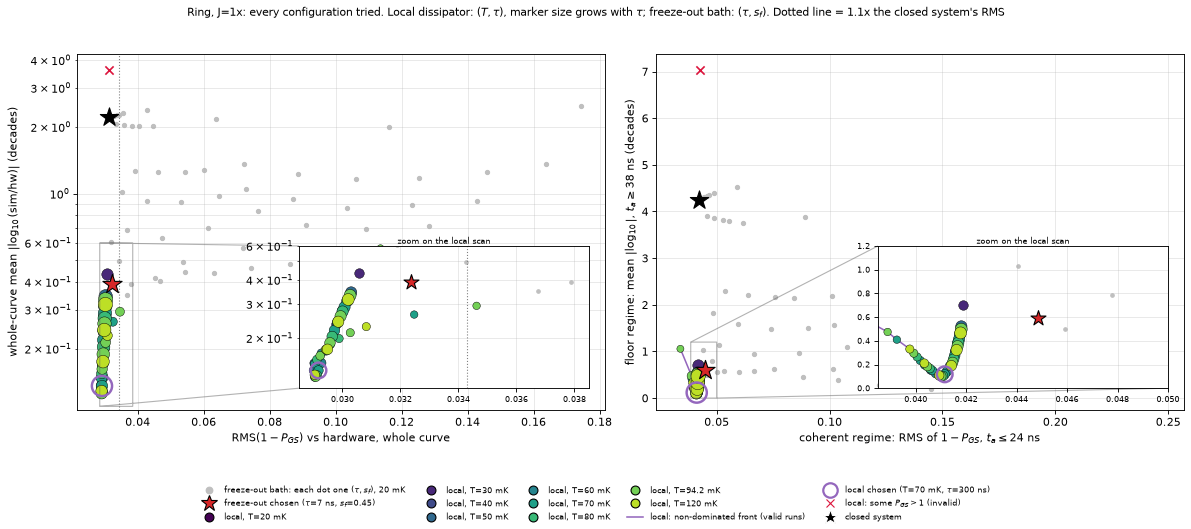

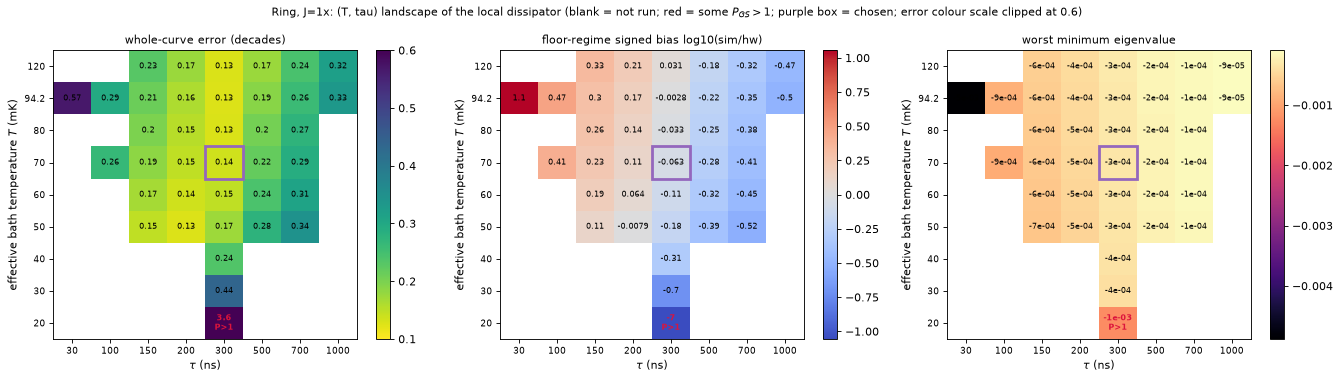

In [65]:
# 16.5: calibration on the ring, J=1x -- both dissipators on the same three hardware series and with the same rule. The scans themselves
# (calibrate_tau_freezeout.py: 368 runs; scan_local_dissipator_ring.py: 309 anneals) run outside the notebook; their logs are read here
# through the scripts' own functions.
sys.path.insert(0, str(EXP_DIR))
import calibrate_tau_freezeout as c165
import scan_local_dissipator_ring as sc165

series165 = c165.hardware_series("ring1x")
closed165 = sc165.closed_metrics(series165)
loc165, _, _, glob165 = sc165.quiet_analyze()      # local: one row per (T, tau); global: one row per (tau, s_f)
cap165 = 1.1 * closed165["rms_P"]


def row(kind, params, m, note=""):
    return {"dissipator": kind, "parameters": params, "coherent RMS(1-P)": m["early_rms"], "floor |log10| (dec.)": m["late_log"],
            "whole-curve |log10| (dec.)": m["log_err"], "whole-curve RMS(1-P)": m["rms_P"], "note": note}


def g_pick(tau, sf):
    q = glob165[np.isclose(glob165.tau_ns, tau) & (np.isclose(glob165.s_f, sf) | (np.isinf(glob165.s_f) & np.isinf(sf)))]
    return q.iloc[0]


def l_pick(T, tau):
    return loc165[np.isclose(loc165.T_mK, T) & np.isclose(loc165.tau_ns, tau)].iloc[0]


rows = [row("closed system", "", closed165)]
for tau, sf, note in [(7.0, 0.45, "chosen"), (7.0, 0.475, "same error as 0.45, RMS above the cap"), (5.0, 0.45, "RMS above the cap"), (10.0, 0.45, ""),
                      (10.0, 0.475, ""), (10.0, 0.6, ""), (30.0, 0.6, ""), (100.0, 0.6, ""), (10.0, float("inf"), "no freeze-out")]:
    rows.append(row("global bath, 20 mK", f"tau={tau:g} ns, s_f={'none' if np.isinf(sf) else sf}", g_pick(tau, sf), note))
for T, tau, note in [(70.0, 300.0, "chosen"), (50.0, 200.0, "best on the ring; P_GS>1 at J>=1.75x"), (94.2, 300.0, ""), (80.0, 300.0, ""),
                     (120.0, 300.0, ""), (70.0, 200.0, ""), (70.0, 100.0, ""), (94.2, 30.0, ""), (50.0, 300.0, "P_GS>1 at J>=1.75x"), (20.0, 300.0, "")]:
    r_ = l_pick(T, tau)
    rows.append(row("local dissipator", f"T={T:g} mK, tau={tau:g} ns", r_, note + ("" if r_.valid else "P_GS>1 already on the ring")))
print("ring, J=1x, mean over the 3 hardware series; the selection rule's RMS cap is 1.1 x closed = %.4f" % cap165)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.4g}"))
print(f"\nlocal scan: {len(loc165)} complete (T, tau) pairs, {int(loc165.valid.sum())} valid; global scan: {len(glob165)} (tau, s_f) pairs, "
      f"{int(((glob165.rms_P <= cap165) & np.isfinite(glob165.s_f)).sum())} satisfy the cap")

fig = sc165.figure_pareto(loc165, closed165, glob165)
plt.show()
fig = sc165.figure_landscape(loc165)
plt.show()

**How each dissipator was fitted.** Ring, $J$=1x, against the three hardware series at hand (original campaign; extended campaign, both signs -- ring $\pm J$ are gauge-equivalent, so one simulation serves all three). The table gives each chosen pair and some alternatives. In the first figure both scans share the same planes (grey: global bath, one dot per $(\tau,s_f)$; coloured: local dissipator, one dot per $(T,\tau)$, larger dot = longer $\tau$; inset = zoom on the local scan). The left plane is the one the selection rule works in; the right one separates the coherent regime from the floor. The heat maps show the local $(T,\tau)$ landscape.

*Global bath.* 368 runs (46 pairs; 54 with 16.6's forward runs) at 20 mK, $\tau\in\{5,\dots,300\}$ ns, $s_f\in\{0.45,\dots,0.75,\text{never}\}$, widened sequentially -- not a full grid ($s_f=0.45$ exists only for $\tau=5$, 7 and 10 ns). Only 8 of the 54 pairs satisfy the RMS cap; the rule picks $\tau=7$ ns, $s_f=0.45$: whole-curve error 0.39 decades (closed system 2.21), RMS 0.0324 (closed 0.0312). The trade-off: a long $\tau$ ($\geq100$ ns) leaves the coherent regime alone but misses the floor by ~4 decades; a short $\tau$ with no freeze-out cools everything and still misses the floor by 2.6; a bath that lives long enough to build the floor (large $s_f$) reproduces it but damages the coherent regime (e.g. $\tau=10$ ns, $s_f=0.6$: floor within 0.6 decades, coherent RMS 0.10 against 0.042 for the closed system). What fixes $s_f$ is the cap, not a minimum of the error: at $\tau=7$ ns the error is the same at $s_f=0.45$ and 0.475 (0.3923 and 0.3927) and only the RMS separates them (0.0324 against 0.0379, cap 0.0343). $s_f=0.45$ is also the lowest value tried on the ring (the chain tried 0.40 and its optimum is 0.45, 16.6). The switch width, 0.02, was fixed from the start and never varied; at the ring's crossing ($s_c=0.4597$) the switch is still at $w=0.38$ (0.5 at $s_f$, 0.08 at $s=0.50$), so "frozen out just before the crossing" (16.6) is a soft cut-off, not a sharp one.

*Local dissipator.* 309 anneals (125 exploratory ones and 184 on the grid $T\in\{50,60,70,80,94.2,120\}$ mK $\times$ $\tau\in\{150,200,300,500,700\}$ ns): 38 complete $(T,\tau)$ pairs with $T$ = 20-120 mK and $\tau$ = 30-1000 ns, 37 of them valid on the ring (only 20 mK gives $P_{GS}>1$). The scan finds a **valley, not a point**: $(T,\tau)=(50,200)$ 0.1258, $(94.2,300)$ 0.1260, $(80,300)$ 0.1282, $(120,300)$ 0.1291, $(70,300)$ 0.1360 decades -- a shorter $\tau$ at a lower $T$ gives the same floor. For $\tau\geq150$ ns the RMS hardly moves (0.029-0.030) and the coherent RMS stays at 0.040-0.042 against 0.0421 for the closed system: unlike the global bath, this dissipator does not touch the coherent regime, so there is no coherent-versus-floor trade-off, and the non-dominated front has two points that differ by $4\times10^{-5}$ in RMS. Resampling the hardware's shot noise (`scan_local_dissipator_ring.py bootstrap`), $(50,200)$ beats $(70,300)$ in 96% of the draws (difference $0.0075\pm0.0042$ decades) and ties with $(94.2,300)$ (65%). So the ring at $J$=1x does not fix $T$, and the formal winner is ruled out by validity elsewhere: at 50 mK with $\tau=300$ ns, 55 of the 302 anneals of the test set below have $P_{GS}>1$ (13 of the 42 combinations, all at $J\geq1.75$x); re-running exactly those 55 anneals with $\tau=200$ ns gives $P_{GS}>1$ in all 55, with a violation 1.5x larger (median $1-P_{GS}$ of $-1.3\times10^{-3}$ against $-8.5\times10^{-4}$), as expected if the violation grows like $1/\tau$ (`results/local_dissipator_T50_tau200_vs_300_invalid_points.csv`). The pair used from here on is $(T,\tau)=(70\text{ mK},300\text{ ns})$: inside the ring's valley (5th of 37 valid pairs, 0.010 decades from the best), the lowest temperature tested with no $P_{GS}>1$ in the whole test set, and with a smaller floor overshoot at $J\geq1.75$x than 94.2 mK (table below). 60 mK, also in the valley at $\tau=300$, was not tested outside the ring. **This choice was made looking at the same test set the local dissipator is evaluated on**, so its numbers below are not a blind prediction as the global bath's are, and both $T$ and $\tau$ are effective parameters.

In [66]:
# 16.5: tables for the global bath on all 215 combinations (2 x 1472 anneals, made outside the notebook by calibrate_tau_freezeout.py heldout
# and analyze-heldout), over the INFORMATIVE combos only (closed system < 99% at the shortest anneal).
TAG1, TAG2 = "tau7_sf0.45_T20", "tau7_off-0.01_T20"
S1 = pd.read_csv(RES_DIR / f"stage2_freezeout_heldout_{TAG1}_summary.csv")
S2 = pd.read_csv(RES_DIR / f"stage2_freezeout_heldout_{TAG2}_summary.csv")
P1 = pd.read_csv(RES_DIR / f"stage2_freezeout_heldout_{TAG1}_points.csv")
P2 = pd.read_csv(RES_DIR / f"stage2_freezeout_heldout_{TAG2}_points.csv")
I1, I2 = S1[~S1.saturated], S2[~S2.saturated]
print(f"{len(S1)} combos, {len(I1)} informative; {int(I1.log_post_bath.notna().sum())} have points after the hardware's first minimum\n")

head = pd.DataFrame({
    "closed system": [I1.rms_window_unitary.median(), I1.log_post_unitary.median(), I1.log_all_unitary.median()],
    "bath, s_f = 0.45": [I1.rms_window_bath.median(), I1.log_post_bath.median(), I1.log_all_bath.median()],
    "bath, s_f = s_c - 0.01": [I2.rms_window_bath.median(), I2.log_post_bath.median(), I2.log_all_bath.median()]},
    index=["coherent regime: median RMS of 1-P", "floor regime: median |log10(model/hw)| (decades)", "all points: median |log10(model/hw)| (decades)"])
print(head.to_string(float_format=lambda x: f"{x:.3f}"))
has = I1.log_post_bath.notna()
print(f"\nbath (s_f=0.45) closer than the closed system: coherent regime in {100 * (I1.rms_window_bath < I1.rms_window_unitary).mean():.0f}% of the "
      f"informative combos, floor regime in {100 * (I1.log_post_bath < I1.log_post_unitary)[has].mean():.0f}% of the {int(has.sum())} that have one")
print(f"signed floor-regime bias of the bath (median of mean log10(1-P_bath / 1-P_hw)): {I1.logbias_post_bath.median():+.2f} decades "
      f"(negative = the model floor is below the measured one)")
ring1 = (I1["shape"] == "ring") & (I1.j_multiple == 1.0)
print(f"excluding the ring at J=1x (the calibration data): floor-regime median {I1[~ring1].log_post_bath.median():.2f} (bath) "
      f"vs {I1[~ring1].log_post_unitary.median():.2f} (closed system); coherent RMS {I1[~ring1].rms_window_bath.median():.4f} vs "
      f"{I1[~ring1].rms_window_unitary.median():.4f}")

print("\nBy J multiple (informative combos, medians):")
byj = pd.DataFrame({
    "n": I1.groupby("j_multiple").size(),
    "floor: closed": I1.groupby("j_multiple").log_post_unitary.median(),
    "floor: s_f=0.45": I1.groupby("j_multiple").log_post_bath.median(),
    "floor: s_f=s_c-.01": I2.groupby("j_multiple").log_post_bath.median(),
    "coherent RMS: closed": I1.groupby("j_multiple").rms_window_unitary.median(),
    "coherent RMS: s_f=0.45": I1.groupby("j_multiple").rms_window_bath.median(),
    "coherent RMS: s_f=s_c-.01": I2.groupby("j_multiple").rms_window_bath.median()})
print(byj.to_string(float_format=lambda x: f"{x:.3f}"))

# shot noise: a point with fewer than 5 hardware failures in 8000 reads says little about the SIZE of 1-P
print("\nShot noise (points after the hardware's first minimum, informative combos):")
for name, P in (("s_f = 0.45", P1), ("s_f = s_c - 0.01", P2)):
    post = P[(~P.saturated) & (~P.in_window)]
    good = post[post.om_hw * 8000 >= 5]
    lu = np.log10(np.clip(good.om_unitary, 1e-12, None) / good.om_hw)
    lb = np.log10(np.clip(good.om_bath, 1e-12, None) / good.om_hw)
    print(f"  {name}: {len(post) - len(good)} of {len(post)} points ({100 * (1 - len(good) / len(post)):.0f}%) have < 5 hardware failures; "
          f"on the other {len(good)}: median |log10 ratio| bath {np.abs(lb).median():.2f} vs closed {np.abs(lu).median():.2f}; "
          f"within x3: {100 * (np.abs(lb) < np.log10(3)).mean():.0f}% vs {100 * (np.abs(lu) < np.log10(3)).mean():.0f}%; "
          f"within x10: {100 * (np.abs(lb) < 1).mean():.0f}% vs {100 * (np.abs(lu) < 1).mean():.0f}%")

print("\nBy shape, s_f = 0.45 (informative combos, medians):")
byshape = I1.groupby("shape").agg(n=("shape", "size"), floor_closed=("log_post_unitary", "median"), floor_bath=("log_post_bath", "median"),
                                  bias=("logbias_post_bath", "median"), coh_closed=("rms_window_unitary", "median"),
                                  coh_bath=("rms_window_bath", "median"))
byshape["edges"] = [{"ring": 6, "chain": 5}.get(s) or int(s.split("_")[1][1:]) for s in byshape.index]
print(byshape.sort_values("edges").drop(columns="edges").to_string(float_format=lambda x: f"{x:.3f}"))

215 combos, 115 informative; 110 have points after the hardware's first minimum

                                                  closed system  bath, s_f = 0.45  bath, s_f = s_c - 0.01
coherent regime: median RMS of 1-P                        0.019             0.022                   0.020
floor regime: median |log10(model/hw)| (decades)          5.283             1.133                   1.484
all points: median |log10(model/hw)| (decades)            2.137             0.772                   0.855

bath (s_f=0.45) closer than the closed system: coherent regime in 3% of the informative combos, floor regime in 99% of the 110 that have one
signed floor-regime bias of the bath (median of mean log10(1-P_bath / 1-P_hw)): -1.13 decades (negative = the model floor is below the measured one)
excluding the ring at J=1x (the calibration data): floor-regime median 1.14 (bath) vs 5.27 (closed system); coherent RMS 0.0222 vs 0.0185

By J multiple (informative combos, medians):
             n  floo

**The global bath on all 215 combinations** (1472 distinct anneals; $\tau=7$ ns, $s_f=0.45$, 20 mK, unchanged from the ring calibration). The ring at $J$=1x, both signs, is calibration data (leaving it out changes the medians marginally, see the line printed above); the chain, the 33 native shapes and the ring at $J>1$x are predictions -- for $J>1$x also an extrapolation of parameters fitted at $J$=1x.

- **Floor regime (after the hardware's first minimum of $1-P_{GS}$)**: median error 1.13 decades for the bath against 5.28 for the closed system, and the bath is the closer one in 99% of the 110 informative combinations that have such points. By $J$ (1x, 1.75x, 2.5x, 3.25x, 4x) the bath's error is 0.84, 1.36, 1.38, 1.56 and 1.30 decades, against 4.3-5.5: it degrades away from the calibrated $J$ but stays 3-4 decades better. Since 39% of these points have fewer than 5 hardware failures in 8000 reads (and say little about the size of $1-P_{GS}$), the shot-noise-aware version is the one to quote: on the other 143 points the median error is 0.73 decades against 5.94, within a factor 10 for 61% of them against 1%, within a factor 3 for 33% against 0%.
- **Coherent regime (up to the first minimum)**: the bath does **not** help: median RMS of $1-P_{GS}$ 0.022 against 0.019 (0.0222 against 0.0185 without the ring), better in only 3% of the combinations, and worse at every $J$ (0.017 against 0.011 at 4x). The hardware sits *above* the closed system in $1-P_{GS}$ there (about 0.04 for the ring, 16.1 and 16.4), and in that window the bath can only remove a little excitation (ring, $t_a=23$ ns: the excitation energy at the end of the sweep goes from 0.212 to 0.198 $k_BT$; `check_bath_energy_flow.py`, `results/stage2_bath_energy_flow_ring1x.csv`). The bath is not a one-way cooler, though: at $t_a=97$ ns the state is *colder* than the 20 mK bath early in the sweep and the bath heats it (from $3.5\times10^{-7}$ to 0.115 $k_BT$ at the end), which is what builds the model's floor at long anneals. This coherent-window gap -- the systematic shortfall of the hardware relative to the closed system that 16.4 documented -- is not explained by relaxation.
- **By shape**: the bath beats the closed system in the floor regime in each of the 13 shapes (median error 0.65-1.25 decades for 12 of them and 1.9 for `native_e6_c26`, against 4.9-5.5) and is slightly worse in the coherent regime in each of them, so nothing here is driven by one topology.
- **Where the bath freezes out**: tying $s_f$ to each combination's crossing ($s_f=s_c-0.01$) is no better than the fixed $s_f=0.45$ at $J$=1x and clearly worse for $J\geq1.75$x (floor error 1.8-2.4 decades against 1.3-1.6). Only these two hypotheses were tried.
- **What it still gets wrong**: it puts the floor about one decade too low on average (signed median $-1.13$), and on the ring the modelled $1-P_{GS}$ rises with $t_a$ much more steeply than the hardware's slow drift (a plausible reason, not tested here, is that the SEAQT bath term relaxes each population at a rate set by its *logarithmic* distance from equilibrium, which makes the approach to the thermal floor exponential in $t_a$).

42 informative combos, 336 points, the same for every row (6 combos are the ring at J=1x, calibration data of both dissipators). Medians over combos.

                                         combos with P_GS>1  whole-curve |log10| (dec.)  RMS(1-P) whole curve  RMS(1-P) coherent window  floor |log10| (dec.)  floor signed bias (dec.)  floor |log10|, >=5 hw failures
model                                                                                                                                                                                                                  
closed system                                             0                       2.139               0.01788                   0.02024                 5.205                    -5.205                           5.574
global bath (tau 7 ns, s_f 0.45, 20 mK)                   0                      0.6928               0.02143                   0.02493                0.9767                   -0.9767                  

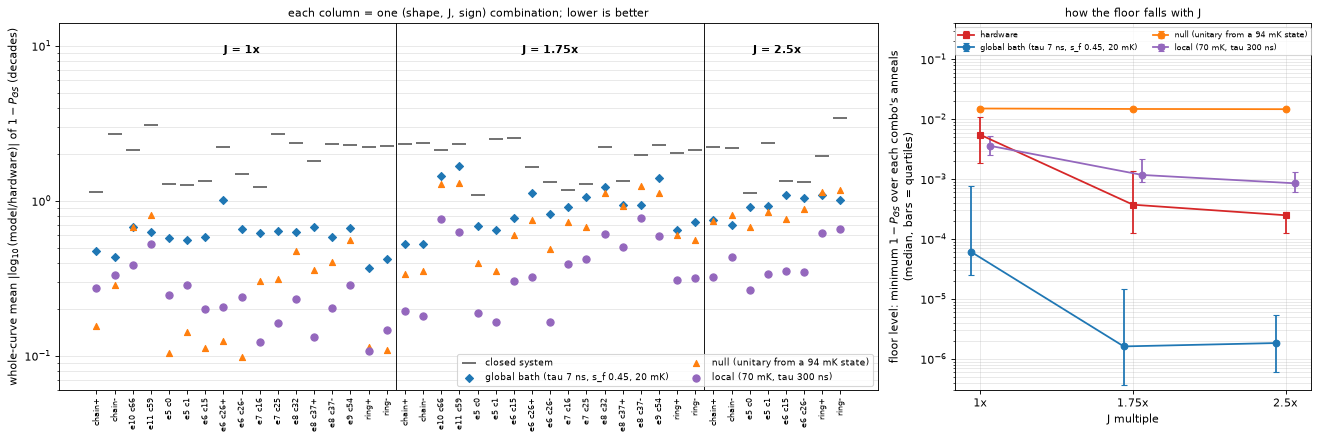

In [67]:
# 16.5: both dissipators on the SAME 42 informative combos (region r0 of the 13 shapes at J=1x, 1.75x and the informative 2.5x; 302 anneals).
# The local runs (run_local_dissipator_subsample.py) and the null model (run_null_model_hotstart.py) are made outside the notebook.
import compare_dissipators as cmp165

P165 = cmp165.build_points()
C165 = cmp165.combo_metrics(P165)
n165 = C165[C165.model == cmp165.M_LOCAL].shape[0]
print(f"{n165} informative combos, {len(P165)} points, the same for every row (6 combos are the ring at J=1x, calibration data of both dissipators). "
      "Medians over combos.\n")
tab165 = cmp165.summary_table(C165)
tab165.columns = ["combos with P_GS>1", "whole-curve |log10| (dec.)", "RMS(1-P) whole curve", "RMS(1-P) coherent window", "floor |log10| (dec.)",
                  "floor signed bias (dec.)", "floor |log10|, >=5 hw failures"]
print(tab165.to_string(float_format=lambda x: f"{x:.4g}"))
print("\nwhole-curve |log10| by J (median over combos):")
print(cmp165.by_j_table(C165, "whole").to_string(float_format=lambda x: f"{x:.3f}"))
print("\nfloor signed bias by J (median over combos; positive = model above the hardware):")
print(cmp165.by_j_table(C165, "bias").to_string(float_format=lambda x: f"{x:+.2f}"))
lvl_models = [cmp165.M_GLOBAL, cmp165.M_NULL] + [m for m in cmp165.LOCAL_RUNS if "50 mK" not in m]     # 50 mK: invalid combos
lvl = cmp165.by_j_table(C165, "floor_model", lvl_models)
lvl.loc["hardware"] = C165[C165.model == cmp165.M_LOCAL].groupby("j").floor_hw.median()
lvl["J=1x / J=2.5x"] = lvl[1.0] / lvl[2.5]
print("\nfloor level by J: median over combos of each combo's lowest 1-P (the closed system sits at the 1e-9 floor of the simulation); "
      "last column: how much the floor falls from J=1x to 2.5x:")
print(lvl.to_string(float_format=lambda x: f"{x:.1f}" if x >= 1 else f"{x:.2e}"))
w165 = C165.pivot_table(index=["topology", "j", "sign"], columns="model", values="whole")
print("\nfraction of the combos where a model has a smaller whole-curve error than the global bath / than the null model:")
print(f"  local (70 mK, tau 300 ns): {100 * (w165[cmp165.M_LOCAL] < w165[cmp165.M_GLOBAL]).mean():.0f}% / {100 * (w165[cmp165.M_LOCAL] < w165[cmp165.M_NULL]).mean():.0f}%")
print(f"  global bath: -- / {100 * (w165[cmp165.M_GLOBAL] < w165[cmp165.M_NULL]).mean():.0f}%")
fig = cmp165.figure_combos(C165)
plt.show()

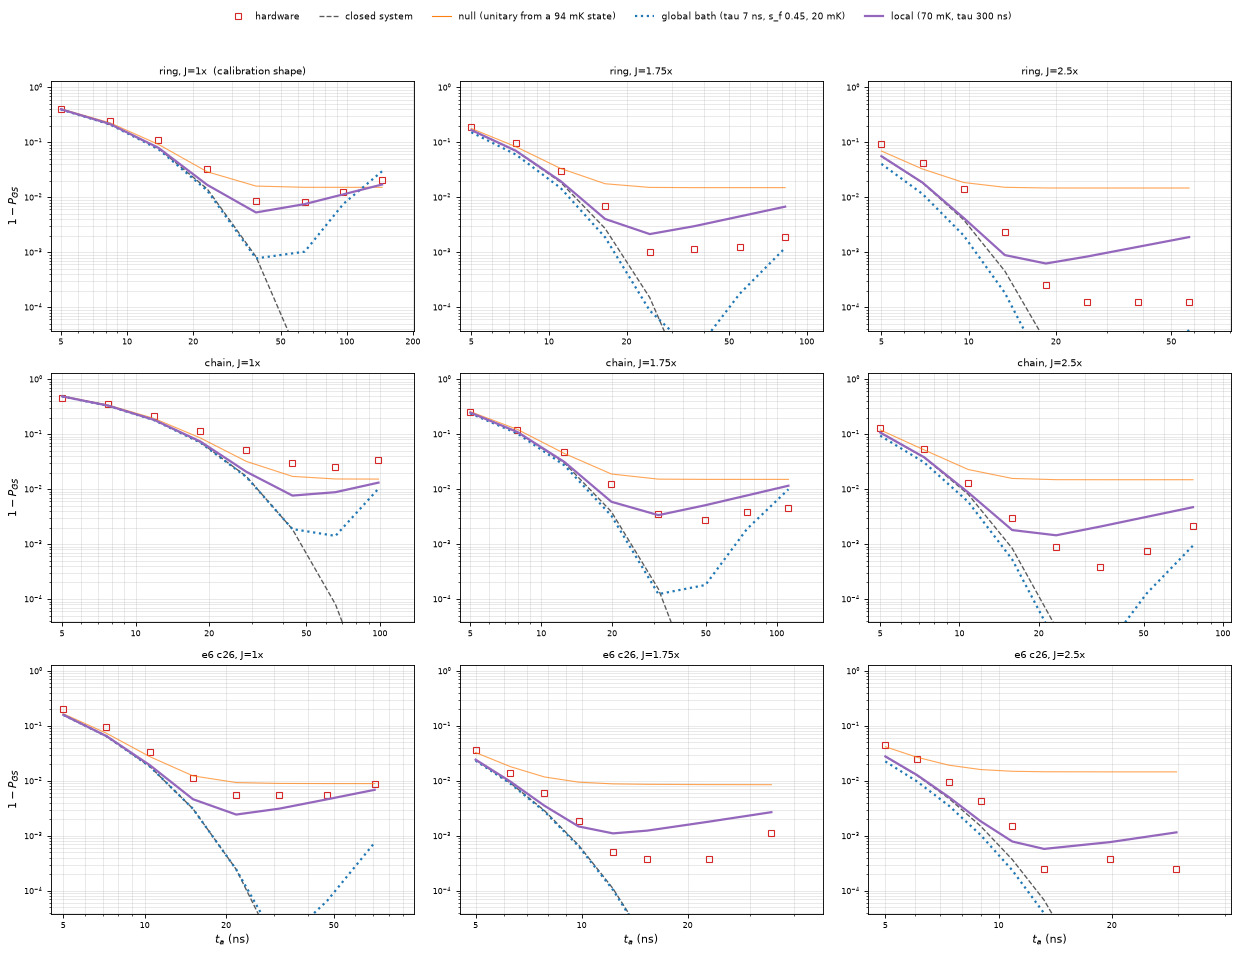

In [68]:
# 16.5: the curves themselves -- hardware and all four models on the same axes, for the calibration shape (ring, J=1x) and, at J=1x, 1.75x and 2.5x,
# for the ring, the chain and native_e6_c26 (region r0; the sign shown is J>0 or the only one measured). Where the closed system is already
# saturated, the panel says so.
fig = cmp165.figure_examples(P165)
plt.show()

**Both dissipators against the hardware, on the same 42 combinations.** The table and the first figure put the log metrics and the linear RMS side by side (last two columns of the table: only floor points with at least 5 hardware failures); the second figure shows the curves for the calibration shape (ring) and for two shapes the dissipators were not fitted on.

- **In the log metrics the local dissipator is the best model -- with one more fitted, effective parameter.** Whole-curve error 0.31 decades against 0.69 (global bath), 0.58 (null model) and 2.14 (closed system); floor regime 0.43 against 0.98, 0.92 and 5.2 (0.35, 0.77, 0.57 and 5.6 counting only the points with at least 5 hardware failures). The local dissipator has a smaller whole-curve error than the global bath in all 42 combinations and than the null model in 81% of them; the global bath is closer than the null model in only 14%. Both dissipators and the null model improve on the closed system by 1.4-1.8 decades. (Six of the 42 combinations are the ring at $J$=1x, the calibration data of both dissipators.)
- **The linear RMS does not rank them in the same way.** Whole curve: null 0.0145, local 0.0173, closed 0.0179, global 0.0214; coherent window: 0.0150, 0.0198, 0.0202, 0.0249. In terms of $P_{GS}$ itself, neither dissipator explains the hardware better than simply starting hot; the local one is 3% better than the closed system and the global bath 20% worse, because neither closes the coherent-window gap of 16.4 and the global bath widens it. What both do is bring the *order of magnitude* of the floor into range, which the closed system (5 decades off) cannot.
- **They miss the floor in opposite directions, and only the global bath gets its fall with $J$.** The hardware floor (median over combinations of each one's lowest $1-P_{GS}$) falls from $5.5\times10^{-3}$ at $J$=1x to $3.8\times10^{-4}$ and $2.5\times10^{-4}$ at 1.75x and 2.5x, a factor 22. The global bath falls about as fast (a factor 33) but sits two decades *below* it at every $J$ ($6\times10^{-5}$, then $\sim2\times10^{-6}$) and climbs back at long $t_a$. The local dissipator has about the right level at $J$=1x ($3.6\times10^{-3}$) but falls only by a factor 4, whatever $\tau$ is (4.0 with 200 ns, 4.2 with 300 ns), so it stays 3-4 times *above* the hardware at $J\geq1.75$x ($1.2\times10^{-3}$ and $8.5\times10^{-4}$): $\tau$ moves the *level* (the floor scales roughly like $1/\tau$: 1.4x higher with 200 ns) but not the slope. A lower $T$ steepens it (94.2 mK: factor 2.4), but lowering $T$ is limited by validity (50 mK gives $P_{GS}>1$), and the local dissipator's smallest eigenvalues ($-10^{-4}$ to $-6\times10^{-4}$) are of the size of the hardware floors it is asked to reproduce at $J\geq1.75$x ($2.5$-$3.8\times10^{-4}$).
- **What this does and does not establish.** The local dissipator's $T$ is a fitted effective temperature whose only justification is that the model fails at 20 mK; it was chosen on the test set; it was not run at $J$=3.25x and 4x nor on the other chip regions; and it has no positivity guarantee. The global bath keeps the measured temperature, is positive by construction and was tested blind on all 215 combinations, but it does not reproduce the shape of the floor either and worsens the coherent regime. Neither dissipator explains the coherent-window gap.
- **Consequence for the next steps.** The local dissipator's temperature cannot be justified physically, so the next tests go to the global bath, which stays valid at any $T$ and $\tau$. Untested variations, cheapest first: the width of the switch (fixed at 0.02), an effective temperature for the global bath (positivity is kept by construction, unlike the local one), a smooth $\tau(s)$ instead of an on/off switch, and a dephasing term.

### 16.6 Is $s_f$'s sign backwards?

The calibrated freeze-out point, $s_f=0.45$, is **below** the ring's crossing $s_c=0.460$ -- the bath in 16.5 is switched off just *before* reaching the small-gap region, not after it. That is the opposite of the usual quantum-annealing freeze-out picture (e.g. Amin, Truncik & Averin 2009): relaxation should stay effective while the gap is small, close to $s_c$ on both sides, and freeze out once the gap reopens *after* the crossing -- which is also where the thesis's own freeze-out point, $s_f=0.684$, sits. If the calibration is telling us the bath is only useful before the interesting part of the sweep, either the fit is an artifact, or this two-parameter family is finding a real but different effect than the one it was named after. Three checks (`check_freezeout_direction.py`, 384 runs, positive by construction as in 16.5 -- worst minimum eigenvalue $-7.6\times10^{-16}$):

**(A) Fill the grid.** 16.5's scan narrowed sequentially and never tried the thesis's $s_f=0.684$ together with the short $\tau$ (5-20 ns) that ended up fitting best -- so the comparison with $s_f<s_c$ wasn't like-for-like. Fill those cells, same sense of the switch (bath ON for $s<s_f$).

**(B) Reverse the switch.** Try the physically-motivated alternative directly: bath OFF for $s<s_f$, ON for $s>s_f$ -- relaxation active through and after the small-gap region, frozen once the gap reopens.

**(C) An independent instance.** Repeat the calibrated model's own sense on the chain, $J$=1x -- same crossing $s_c=0.4597$ as the ring (the condition $\Gamma(s_c)=J_{cal}(s_c)|J|$ depends only on the schedule and $|J|$, not the graph), independent hardware data. If its own optimum also lands at or below $s_c$, the pattern is structural, not a ring-specific fluke.

In [59]:
# 16.6: setup -- reuse check_freezeout_direction.py's own helper functions (same dissipator, integrator and
# observable as 16.5; the only new things are the `direction` switch and generalizing to chain).
sys.path.insert(0, str(EXP_DIR))
import check_freezeout_direction as c166

dlog = pd.read_csv(c166.LOG_PATH)
ring_series166, chain_series166 = c166.series_for("ring"), c166.series_for("chain")
closed_ring166, closed_chain166 = c166.closed_system_metrics(ring_series166), c166.closed_system_metrics(chain_series166)
chosen166 = c166.chosen_model_metrics(ring_series166)
print(f"{len(dlog)} runs; worst min eigenvalue {dlog.min_eig.min():+.1e}\n")
print(f"closed system:    ring log_err={closed_ring166[0]:.3f} ({10**closed_ring166[0]:.0f}x)  rms_P={closed_ring166[1]:.4f}")
print(f"                  chain log_err={closed_chain166[0]:.3f} ({10**closed_chain166[0]:.0f}x)  rms_P={closed_chain166[1]:.4f}")
print(f"calibrated model: tau={c166.CHOSEN_TAU:g} ns, s_f={c166.CHOSEN_SF:g} (16.5): log_err={chosen166[0]:.3f} "
      f"({10**chosen166[0]:.2f}x)  rms_P={chosen166[1]:.4f}")

384 runs; worst min eigenvalue -7.6e-16

closed system:    ring log_err=2.214 (164x)  rms_P=0.0312
                  chain log_err=1.960 (91x)  rms_P=0.0490
calibrated model: tau=7 ns, s_f=0.45 (16.5): log_err=0.392 (2.47x)  rms_P=0.0324


**(A):** at the *same* short $\tau$, the thesis's $s_f=0.684$ is not competitive with the calibrated $s_f=0.45$ -- worse in both the error and the RMS, by a wide margin, everywhere in the grid that was filled in. This was not a gap in the exploration: within this model, $s_f$ below the crossing genuinely fits the ring better than $s_f$ after it, at every $\tau$ tried.

In [60]:
# 16.6 (A): ring, forward switch, s_f=0.684 (thesis value, AFTER the crossing) x the short tau values that fit best in 16.5.
sub = dlog[(dlog.topology == "ring") & (dlog.direction == "before")]
rows = [{"tau (ns)": tau, "s_f": sf, **dict(zip(("log_err (dec.)", "x", "rms_P"),
        (lambda le, rp: (le, 10**le, rp))(*c166.metrics(c166.curve_from(sub, "ring", tau, sf, "before"), ring_series166))))}
        for tau in (5.0, 7.0, 14.0, 20.0) for sf in (0.684, 0.75)]
print(f"(for reference, the calibrated model, tau=7 s_f=0.45: log_err={chosen166[0]:.3f} ({10**chosen166[0]:.2f}x) rms_P={chosen166[1]:.4f})\n")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

(for reference, the calibrated model, tau=7 s_f=0.45: log_err=0.392 (2.47x) rms_P=0.0324)

 tau (ns)   s_f  log_err (dec.)      x  rms_P
    5.000 0.684           0.923  8.381  0.143
    5.000 0.750           1.364 23.139  0.164
    7.000 0.684           0.886  7.684  0.123
    7.000 0.750           1.258 18.101  0.146
   14.000 0.684           0.942  8.746  0.087
   14.000 0.750           1.165 14.624  0.106
   20.000 0.684           1.047 11.134  0.073
   20.000 0.750           1.228 16.920  0.089


**(B):** reversing the switch is not a modest change -- it is decisively worse, everywhere in the grid, than *not using a dissipator at all*. The best reversed configuration (out of 20 tried) is 247x off on the floor, against the closed system's own 164x; none come close to the RMS the closed system already achieves, let alone the calibrated model's. At matched $(\tau, s_f)$ the gap is stark: $\tau=5$ ns, $s_f\approx0.46$ gives 2.2x forward and 1400x reversed -- a factor of 600 apart from flipping one sign. A plausible reason: a bath that is mostly ON for the second half of the sweep behaves like the *undifferentiated* bath of 16.4/`calibrate_tau_bath.py` (no freeze-out at all), which over-cools relative to the hardware's floor in the same direction already documented there -- and does so on top of the closed system's own shortfall (16.4: hardware sits below the closed system by 4-5 decades) rather than fixing it. The calibrated model does the opposite: it switches the bath off before the tail, so the late-time population is whatever a largely-unitary evolution leaves behind (starting from a state already mixed by the bath earlier in the sweep) -- which decays with $t_a$ far more slowly than either extreme. This is a plausible mechanism, not a proof; it does not explain *why* the cutoff lands where it does.

In [61]:
# 16.6 (B): ring, REVERSED switch (bath OFF for s<s_f, ON for s>s_f).
sub = dlog[(dlog.topology == "ring") & (dlog.direction == "after")]
rows = [{"tau (ns)": tau, "s_f": sf, **dict(zip(("log_err (dec.)", "x", "rms_P"),
        (lambda le, rp: (le, 10**le, rp))(*c166.metrics(c166.curve_from(sub, "ring", tau, sf, "after"), ring_series166))))}
        for tau in (5.0, 10.0, 20.0, 50.0, 100.0) for sf in (0.46, 0.55, 0.65, 0.684)]
rdf = pd.DataFrame(rows).sort_values("log_err (dec.)")
print(rdf.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
ok = rdf[rdf.rms_P <= 1.1 * closed_ring166[1]]
print(f"\nreversed configs with rms_P <= {1.1 * closed_ring166[1]:.4f} (1.1x the closed system's): {len(ok)} of {len(rdf)}")
print(f"best reversed vs. best forward at matched (tau, s_f~0.46): reversed tau=5 s_f=0.46 -> "
      f"{rdf.set_index(['tau (ns)','s_f']).loc[(5.0,0.46),'x']:.0f}x   vs forward tau=5 s_f=0.45 (16.5 grid) -> ~2.2x")

 tau (ns)   s_f  log_err (dec.)        x  rms_P
   20.000 0.460           2.393  247.262  0.140
   50.000 0.460           2.399  250.501  0.090
  100.000 0.460           2.472  296.670  0.064
   20.000 0.550           2.563  365.353  0.136
   50.000 0.550           2.569  370.813  0.087
  100.000 0.550           2.585  384.460  0.062
  100.000 0.650           2.660  456.581  0.058
  100.000 0.684           2.665  462.172  0.056
   50.000 0.650           2.675  472.890  0.080
   20.000 0.650           2.676  474.190  0.126
   50.000 0.684           2.699  500.343  0.077
   20.000 0.684           2.711  513.641  0.122
   10.000 0.460           2.718  521.944  0.174
   10.000 0.550           2.838  688.642  0.172
   10.000 0.650           2.875  750.097  0.165
   10.000 0.684           2.884  765.453  0.161
    5.000 0.460           3.157 1434.385  0.187
    5.000 0.550           3.265 1840.995  0.187
    5.000 0.684           3.277 1892.192  0.184
    5.000 0.650           3.292 1959.655

**(C):** calibrated independently on the chain -- different hardware data, same $s_c$ -- the optimum lands at essentially the same point: $\tau=5$ ns, $s_f=0.45$, even *better* than the ring's own best (2.0x vs 2.5x). This is the structural signal: it is not a ring-specific coincidence of the fit.

In [62]:
# 16.6 (C): chain, forward switch, independent hardware data, same s_c as the ring.
sub = dlog[(dlog.topology == "chain") & (dlog.direction == "before")]
rows = [{"tau (ns)": tau, "s_f": sf, **dict(zip(("log_err (dec.)", "x", "rms_P"),
        (lambda le, rp: (le, 10**le, rp))(*c166.metrics(c166.curve_from(sub, "chain", tau, sf, "before"), chain_series166))))}
        for tau in (5.0, 10.0, 20.0, 50.0) for sf in (0.40, 0.45, 0.5, 0.6, 0.684)]
cdf = pd.DataFrame(rows).sort_values("log_err (dec.)")
print(f"closed system (chain): log_err={closed_chain166[0]:.3f} ({10**closed_chain166[0]:.0f}x)  rms_P={closed_chain166[1]:.4f}\n")
print(cdf.head(8).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

closed system (chain): log_err=1.960 (91x)  rms_P=0.0490

 tau (ns)   s_f  log_err (dec.)     x  rms_P
    5.000 0.450           0.309 2.035  0.048
    5.000 0.500           0.371 2.352  0.083
    5.000 0.600           0.449 2.814  0.110
   10.000 0.600           0.455 2.851  0.078
   10.000 0.500           0.455 2.854  0.052
    5.000 0.684           0.457 2.867  0.137
   10.000 0.684           0.470 2.951  0.100
    5.000 0.400           0.631 4.275  0.050


saved C:\Users\andre\OneDrive\Documentos\GitHub\SEAQT-quantum-annealing-evolution\experiments\advantage2_lz_crossover\results\plots\stage2_freezeout_direction_pareto.png


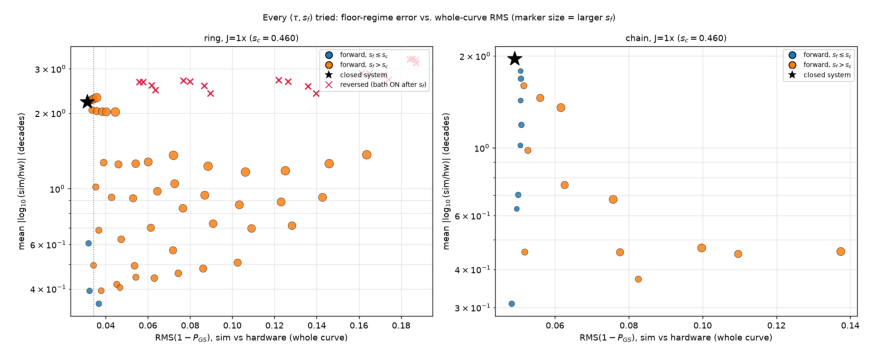

In [63]:
# 16.6: every (tau, s_f, direction) tried -- floor-regime error vs. whole-curve RMS, ring and chain.
c166.figure()
plt.close("all")   # figure() builds its own two-panel plot (matplotlib.use("Agg")) and saves it without showing it
img = plt.imread(c166.PLOT_PATH)
fig, ax = plt.subplots(figsize=(img.shape[1] / 130, img.shape[0] / 130))
ax.imshow(img)
ax.axis("off")
plt.show()

**$s_f$ below the crossing is not a grid artifact and not an accident of the ring: it is what this two-parameter family finds whenever it is asked to fit real hardware data, and it is the opposite of where a bath is usually argued to matter most.**

- **The reversed switch is ruled out, decisively**, at least within this model: bath-active-after-$s_f$ is worse than no dissipator at all, by 1.5-2.5 orders of magnitude, for every $(\tau,s_f)$ tried. This directly answers the question that started this section: no, inverting $w(s)$ does not "encajar mejor" -- it is a much worse fit than what 16.5 already has.
- **The forward model ($s_f<s_c$) is confirmed on a second, independent instance** (chain, $\tau=5$ ns, $s_f=0.45$, 2.0x), which argues against "this is what curve-fitting six free hardware points on the ring happens to prefer" and for a real, reproducible effect of *some* mechanism that this switch direction captures.
- **What is not resolved**: *why* the cutoff sits before $s_c$ rather than at or after it, as the usual freeze-out picture would suggest. The plausible-but-untested mechanism above -- pre-crossing bath exposure leaves a mixed state that then evolves unitarily through the crossing and beyond, decaying more slowly than either a fully-thermalizing or a fully-coherent trajectory -- is offered as a hypothesis, not a result: it has not been checked against, for instance, the actual population distribution at $s_f$, or against a $\tau(s)$ that grows smoothly (rather than switching sharply) as $s\to s_c$ from both sides, which is closer to the textbook picture and was not tried.
- **Framing**: $s_f$ in this model should not be read as "the chip's physical freeze-out point" -- it is a fitted parameter in a specific, crude (step-function) family, whose value and even its *sign convention* matter enormously to the fit, and whose physical interpretation remains open. Sections 16.5-16.6 together substantially reduce (not eliminate) the SEAQT/hardware gap in the floor regime, without yet explaining it.

### 16.7 Where does the floor-regime improvement hold, shape by shape?

16.5's tables (and 16.6's chain check) report *medians* over 13 shapes: the bath cuts the floor-regime error by 3-4 decades and costs a little in the coherent regime. A median cannot show *where* that holds and where it does not. This extends 16.4's original per-shape curves grid (13 shapes, $J$=1x and 2.5x, exact closed-system SEAQT vs. 8000-read hardware) with the calibrated dissipative model ($\tau=7$ ns, $s_f=0.45$, the same points already computed for 16.5/16.6 -- no new simulation) as a dotted/dash-dot line, wherever that (shape, $J$) combination is not saturated (`saturated` in the 16.5 points file: the closed system already exceeds 99% ground-state population at the shortest anneal, so there is nothing left to resolve there -- true for 8 of the 13 shapes at $J$=2.5x, including the three densest ones, `e9 c54`/`e10 c66`/`e11 c59`, whose hardware curves are already close to their measurement floor over the whole visible range even without the bath).

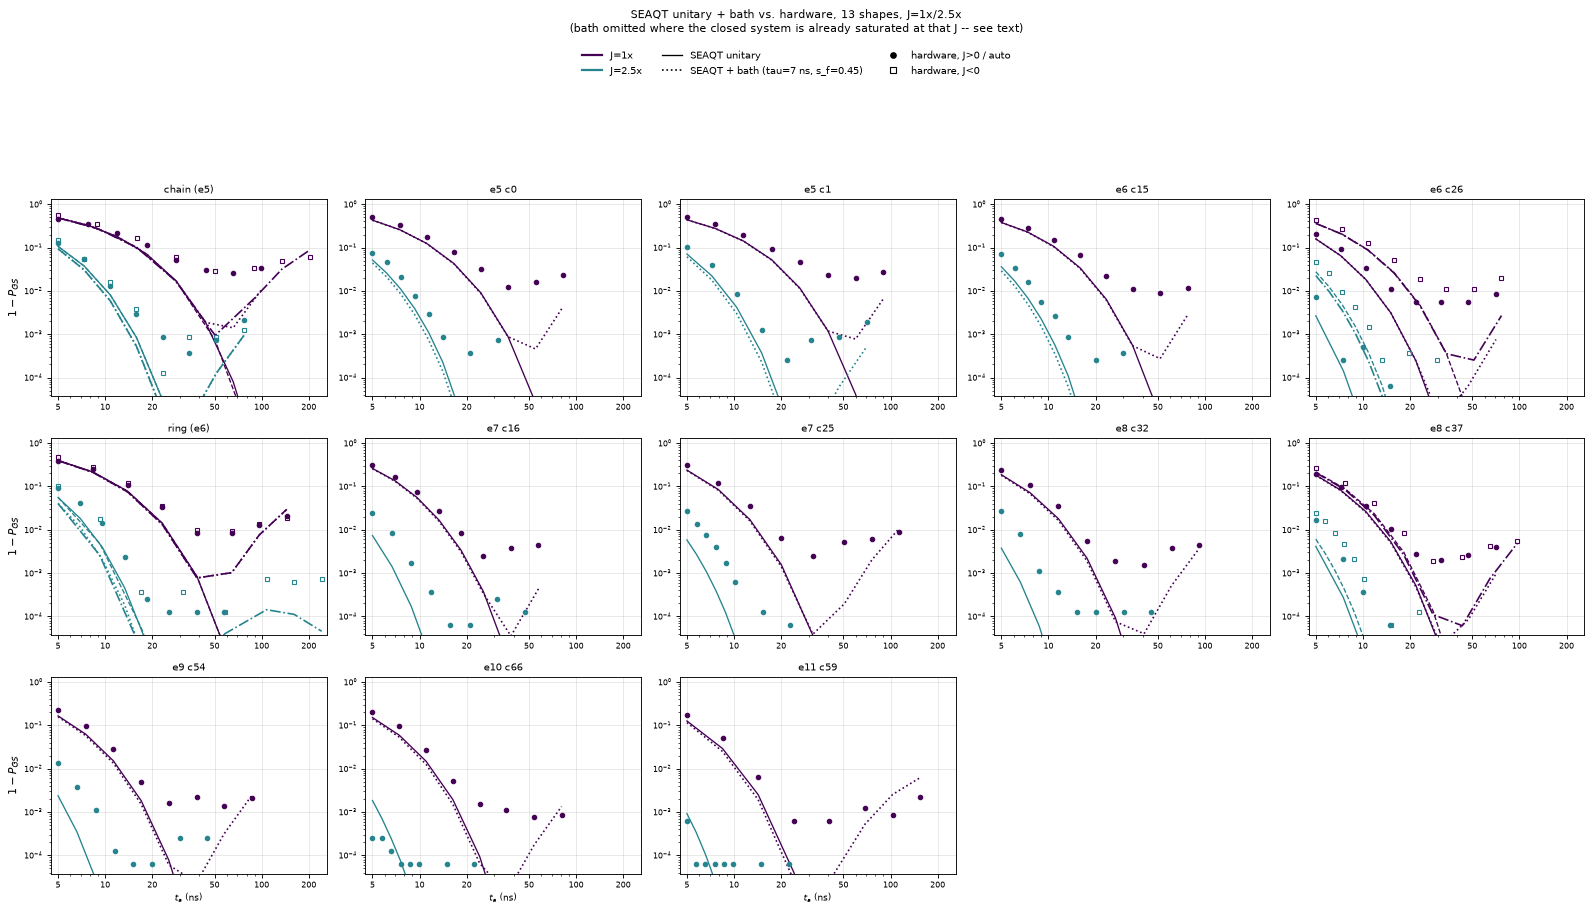

In [64]:
# 16.7: 16.4's grid (unitary + hardware, J=1x/2.5x) with the calibrated bath model (tau=7, s_f=0.45) added as a
# dotted/dash-dot line wherever the closed system is not saturated there. Reuses results/
# stage2_freezeout_heldout_tau7_sf0.45_T20_points.csv (16.5/16.6's own points, om_bath column) -- no new simulation.
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter, ScalarFormatter

J_SHOW = [1.0, 2.5]
bath_pts = pd.read_csv(RES_DIR / "stage2_freezeout_heldout_tau7_sf0.45_T20_points.csv")

fig, axes = plt.subplots(3, 5, figsize=(20, 10.5))
for ax, shape in zip(axes.ravel(), shapes):
    topo = shape if shape in ("ring", "chain") else f"{shape}_r0"
    sub = s1b[s1b.topology == topo]
    for jm in J_SHOW:
        for sign, ls_u, ls_b, mk in [("auto", "-", ":", "o"), ("+", "-", ":", "o"), ("-", "--", "-.", "s")]:
            g = sub[(sub.j_multiple == jm) & (sub.j_sign == sign)].sort_values("t_anneal_ns")
            if len(g) == 0:
                continue
            col = J_COL[jm]
            ax.loglog(g.t_anneal_ns, np.clip(1 - g.p_ground_seaqt_unitary, SIM_FLOOR_16_4, 1), ls_u, color=col, lw=1.2)
            ax.loglog(g.t_anneal_ns, np.clip(1 - g.p_ground_hw, HW_FLOOR_16_4, 1), mk, color=col, ms=4,
                      mfc="none" if sign == "-" else col)
            bg = bath_pts[(bath_pts.topology == topo) & (bath_pts.j_multiple == jm) & (bath_pts.j_sign == sign)]
            if len(bg) and not bool(bg.saturated.iloc[0]):
                bg = bg.sort_values("t_anneal_ns")
                ax.loglog(bg.t_anneal_ns, np.clip(bg.om_bath, SIM_FLOOR_16_4, 1), ls_b, color=col, lw=1.5)
    ax.set_title(_label(shape), fontsize=9)
    ax.set_ylim(HW_FLOOR_16_4 * 0.6, 1.3)
    ax.set_xlim(4.5, 260)
    ax.set_xticks([5, 10, 20, 50, 100, 200])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(shapes):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("$1-P_{GS}$")
for ax in axes[-1, :]:
    ax.set_xlabel("$t_a$ (ns)", fontsize=8)
handles = [Line2D([0], [0], color=J_COL[j], lw=2, label=f"J={j:g}x") for j in J_SHOW] + [
    Line2D([0], [0], color="k", lw=1.2, ls="-", label="SEAQT unitary"),
    Line2D([0], [0], color="k", lw=1.5, ls=":", label="SEAQT + bath (tau=7 ns, s_f=0.45)"),
    Line2D([0], [0], color="k", marker="o", lw=0, ms=5, label="hardware, J>0 / auto"),
    Line2D([0], [0], color="k", marker="s", lw=0, ms=5, mfc="none", label="hardware, J<0"),
]
fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.suptitle("SEAQT unitary + bath vs. hardware, 13 shapes, J=1x/2.5x\n"
             "(bath omitted where the closed system is already saturated at that J -- see text)", y=1.08, fontsize=10)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**The dotted bath curve reproduces the hardware's dip-and-recovery shape that the closed system cannot produce by construction (monotonic decay to zero) -- how closely it matches the recovery's *size* varies by shape, and at $J$=2.5x it visibly costs coherent-window accuracy, exactly as the bar charts predicted.**

- **$J$=1x, the calibration case (ring)**: the bath tracks the closed system almost exactly through the coherent window (both near $1-P_{GS}\approx0.40$ at 5 ns), dips to its own minimum around 40-65 ns (where the closed system has already collapsed to $10^{-6}$-$10^{-8}$), then rises with the hardware -- at 96.5 ns it is $7.6\times10^{-3}$ against hardware's $1.3\times10^{-2}$ (1.7x low, where the closed system is off by $5\times10^5$), and at the longest anneal (145 ns) it slightly *overshoots*: $3.0\times10^{-2}$ against $2.0\times10^{-2}$.
- **Elsewhere the recovery is real but partial**: in `chain`, the bath reaches $1.0\times10^{-2}$ at the longest measured anneal (99 ns) against hardware's $3.3\times10^{-2}$ -- still 3x low, not caught up within the measured window. This is the shape-by-shape picture behind 16.5's "floor about one decade too low on average": some shapes (ring) end up matching or slightly overshooting by the last point, others (chain, and most of the native shapes in the bottom two rows) remain below throughout.
- **`e9 c54`, `e10 c66`, `e11 c59`**: only $J$=1x has anything to show -- at 2.5x even the *closed system* is already saturated (hardware itself sits at its measurement floor, $\lesssim2.5\times10^{-4}$, over the whole visible range), so no line was added there.
- **The two frustrated shapes, `e6 c26` and `e8 c37`**, are the busiest panels (both signs $\times$ two models $\times$ hardware): the ferromagnetic/antiferromagnetic split is visible mainly at short $t_a$, and the same dip-recovery pattern holds for both signs. A dedicated FM/AF panel would help at print resolution; not built here.
- **$J$=2.5x, where it is still informative (`ring`, `chain`, `e5 c0`, `e5 c1`, `e6 c15`)**: the coherent-window cost from 16.5/16.6's bar chart is visible directly, not just as an RMS number -- the dotted line sits systematically *below* the solid unitary line (itself already below hardware) through the whole coherent window, not only at long $t_a$. E.g. ring at 5 ns: hardware 0.092, unitary 0.056, bath 0.041; chain at 5 ns: 0.130, 0.107, 0.094. The bath's extra cooling is small in absolute terms but consistent, and it never helps in this regime.
- **A speculative remark, not tested**: $s_f=0.45$ is the same *fraction* of every anneal (bath on for the first 45% of $s$, regardless of shape or $J$), so how well the recovery matches at the end depends on how that fixed fraction happens to fall relative to each combo's own transition -- plausibly why it lines up almost exactly for the ring (where it was calibrated) and only partially for the rest.

### 16.8 A physical center for the switch: width, generalization, and why this isn't called "freeze-out" yet

16.6 left two things unresolved: *why* the fitted freeze-out point sits below $s_c$ rather than at or after it, and whether the switch's width (fixed at 0.02 from the start, never varied) means anything. The standard two-level result for $\sigma^z$-coupled relaxation, $|\langle e|\sigma^z|g\rangle|^2=\sin^2\theta(s)$ (largest where the instantaneous eigenstates are most mixed, i.e. near $s_c$), motivates a smooth switch built from the schedule itself: near $s_c$, the natural "how quantum is $H(s)$" ratio

$$\tilde Q(s) = \frac{\Gamma(s)}{J_{cal}(s)|J|} = \frac{A(s)}{B(s)|J|}, \qquad \tilde Q(s_c)=1 \text{ by the definition of } s_c,$$

gives $w_{fis}(s) = \tilde Q^2/(1+\tilde Q^2) = 1/(1+e^{-2\ln\tilde Q(s)})$, which *linearizes*, right at $s_c$, into exactly the fitted logistic switch with $s_f = s_c$ and $\delta_{fis} = 1/(2k)$, $k=|d\ln\tilde Q/ds|_{s_c} = |d\ln A/ds - d\ln B/ds|_{s_c}$ (`check_switch_width.py`). This $\tilde Q$ is related to, but not the same object as, Marshall, Rieffel & Hen's $Q(s)=A(s)/B(s)$ (no $|J|$ normalization, used as a regime indicator rather than a smooth weight) [Marshall, Rieffel & Hen, *Thermalization, Freeze-out and Noise: Deciphering Experimental Quantum Annealers*, arXiv:1703.03902].

**Why this section does not say "freeze-out point".** The freeze-out conjecture [Amin, *Phys. Rev. A* **92**, 052323 (2015); Marshall, Rieffel & Hen, arXiv:1703.03902] needs TWO separate things, which is easy to run together: (i) *quasi-staticity*, $\rho(s^*)\approx\text{Gibbs}(H(s^*))$ -- a freeze-out is well-defined at all; and (ii) *small $Q(s^*)=A(s^*)/B(s^*)$* -- that Gibbs state is close to a *classical* Boltzmann distribution of $H_p$ alone, Marshall et al.'s threshold being $Q(s^*)\lesssim0.1$. These are independent: a system can freeze out quasi-statically into a state that still has a large quantum component (what Amin, Andriyash, Rolfe, Kulchytskyy & Melko call a *quantum* Boltzmann distribution), if $Q(s^*)$ isn't small. Here (ii) is exactly known with no simulation, because $Q(s_c)=A(s_c)/B(s_c)=|J|$ by the very definition of $s_c$ -- $Q(s_c)=0.212$ at $J$=1x and $0.479$ at $J$=1.75x (16.8, further down), both far above 0.1. So **even a fully quasi-static freeze-out at $s_c$ would land in the quantum, not the classical, regime** -- structurally, not as a numerical accident of these two $J$'s. Whether (i) holds at all is checked below; $s_c$ in this section is called a **bath-decoupling point** until it does.

In [69]:
# 16.8: the width sweep (ring, J=1x, tau=7 ns fixed, 20 mK; check_switch_width.py, 64 anneals) -- does the physical
# width (delta_fis, from Qtilde) matter, and does moving the center to s_c help independently of the width?
sys.path.insert(0, str(EXP_DIR))
import config
import check_switch_width as c168

_, j_dimless168 = c168._combo()
schedule168 = config.load_advantage2_schedule()
Qtilde168, k168 = c168.qtilde_and_k(schedule168, abs(j_dimless168), c168.S_C)
delta_fis168 = 1 / (2 * k168)
print(f"ring, J=1x: |J|={abs(j_dimless168):.6f}, S_C={c168.S_C:.6f}, Qtilde(S_C)={Qtilde168(c168.S_C):.6f}")
print(f"k={k168:.3f}  ->  delta_fis=1/(2k)={delta_fis168:.4f}  (the fixed switch width used since 16.5: 0.02)\n")

d168 = pd.read_csv(c168.LOG_PATH)
series168 = c168.cd.series_for("ring")
closed168 = c168.cd.closed_system_metrics(series168)
main168 = pd.read_csv(RES_DIR / "stage2_freezeout_log.csv")
main168 = main168[main168["set"] == "ring1x"]
rows168 = [{"config": "reference: s_f=0.45, delta=0.02", "s_f": 0.45, "delta": 0.02,
            **dict(zip(("log_err", "rms_P"), c168.cd.metrics(c168.cf.sim_curve(main168, 7.0, 0.45, 20.0), series168)))}]
for label, g in d168.groupby("label"):
    curve = pd.Series(g.p_gs.values, index=g.t_a_ns.round(3).values).sort_index()
    le, rp = c168.cd.metrics(curve, series168)
    s_f, delta, full = g.s_f.iloc[0], g.delta.iloc[0], bool(g.full_wfis.iloc[0])
    rows168.append({"config": label, "s_f": np.nan if full else s_f, "delta": np.nan if full else delta,
                    "log_err": le, "rms_P": rp})
order168 = ["reference: s_f=0.45, delta=0.02", "sf0.45_d0.005", "sf0.45_d0.01", "sf0.45_d0.04", "sf0.45_dfis",
            "sfSC_dfis", "full_wfis", "sfSC_d0.005", "sfSC_d0.01"]
tab168 = pd.DataFrame(rows168).set_index("config").reindex(order168)
print(f"closed system: log_err={closed168[0]:.3f} ({10**closed168[0]:.0f}x)  rms_P={closed168[1]:.4f}  "
      f"(1.1x cap = {1.1*closed168[1]:.4f})\n")
print(tab168.to_string(float_format=lambda x: f"{x:.4g}"))

ring, J=1x: |J|=0.212386, S_C=0.459731, Qtilde(S_C)=1.000011
k=24.180  ->  delta_fis=1/(2k)=0.0207  (the fixed switch width used since 16.5: 0.02)

closed system: log_err=2.214 (164x)  rms_P=0.0312  (1.1x cap = 0.0343)

                                   s_f   delta  log_err   rms_P
config                                                         
reference: s_f=0.45, delta=0.02   0.45    0.02   0.3923 0.03236
sf0.45_d0.005                     0.45   0.005   0.3769 0.02973
sf0.45_d0.01                      0.45    0.01   0.3803  0.0304
sf0.45_d0.04                      0.45    0.04   0.4255  0.0381
sf0.45_dfis                       0.45 0.02068   0.3933 0.03251
sfSC_dfis                       0.4597 0.02068   0.3849 0.03418
full_wfis                          NaN     NaN   0.3864 0.03389
sfSC_d0.005                     0.4597   0.005   0.3597 0.03127
sfSC_d0.01                      0.4597    0.01   0.3689 0.03203


**Two independent effects, and the width does not saturate.** Moving the center to $s_c$ (at fixed width $\approx\delta_{fis}$) and narrowing the width (at fixed $s_f=0.45$) each improve the fit on their own, and combine: $s_f=s_c,\ \delta=0.005$ is the best of the eight, better than the two-parameter fitted reference on *both* metrics (whole-curve error **and** RMS -- unusual, since for the global bath 16.5 these two costs normally trade off against each other). But $\delta_{fis}\approx0.021$ is barely different from the switch's original $0.02$, so this pair does not by itself show the physical width is right: a follow-up at $\delta=0.001$ (not shown in the table -- `stage2_switch_width_log.csv`'s history) improved *further*, to 0.350, with no sign of saturating. **The data prefer an increasingly sharp cutoff at $s_c$; the width is not resolved by this test, and $s_f=0.45$'s displacement from $s_c$ in 16.6 was compensating for a switch that was, if anything, too soft, not too sharp.** From here on "the step at $s_c$" means the $\delta\to0$ limit of this switch, not a specific finite width.

**How much of this is real, and how much is hardware noise?** A shot-noise-only bootstrap (Binomial(8000, $p$), the *verified* number of reads at every point of all three ring hardware series) says the step at $s_c$ beats the reference in 100% of 3000 resampled draws (paired: the same resampled hardware curve for every model, so shot noise partly cancels in the comparison). But shot noise is not the only source of hardware variability: `second_embedding_ring1x.csv` -- a second, physically disjoint embedding of this exact (ring, $J$=1x) problem, same 8000 reads, run specifically to check this -- disagrees with the original embedding by only 0.05-0.34$\sigma$ of shot noise at short $t_a$ (5-23 ns) but by 1.2-2.4$\sigma$ at $t_a=$ 38.7-64.5 ns, exactly where the floor sits. Marshall, Rieffel & Hen measured this directly across 22 programming cycles on much larger instances ($N=31$-$501$) and found actual fluctuations typically an *order of magnitude* above shot noise, worsening with problem size -- our 6-qubit system is far smaller than their smallest instance, so is plausibly less affected, but the direction (real variability beyond counting statistics, concentrated where $1-P_{GS}$ is smallest) is the same effect. Breaking the improvement down by $t_a$: the step-at-$s_c$ configuration draws 71% of its gain from the ($t_a\geq38$ ns) floor and 29% from the ($t_a\leq24$ ns) coherent window; narrowing $\delta$ alone at fixed $s_f=0.45$ draws *more than half* (63%) of its gain from the coherent window, where $1-P_{GS}\sim5$-$40\%$ and shot noise is negligible. So this is not pure floor-noise riding on the metric, but the largest single gain (moving to $s_c$) is concentrated exactly where hardware repeatability is weakest.

**The chain generalization test needed a second look.** Run unchanged (same $\tau=7$ ns fitted on the ring) on the chain -- independent hardware data, same $s_c=0.4597$ since $s_c$ depends only on the schedule and $|J|$ -- both the step at $s_c$ and the full $w_{fis}$ did *worse* (0.398, 0.404) than the chain's own from-scratch fit ($\tau=5$, $s_f=0.45$: 0.309). But $\tau=7$ was fitted for the *original* two-parameter switch, not for these; a $\tau$ sweep (`check_switch_tau_sweep.py`, 160 anneals, both shapes on both ring and chain) shows it was never the ring's own optimum for the step either -- that is $\tau=5$ ns.

**Does the width story hold at a different $\tau$?** The $\delta=0.001\to0.350$ non-saturation result above used $\tau=7$ ns -- the ring's own optimum for the *original* two-parameter switch, not for these one-parameter shapes (see below: it is $\tau=5$ ns). Repeating the same $\delta$ sweep at $\tau=5$ ns (`check_width_at_tau5.py`, 32 anneals) gives the same pattern:

In [74]:
# 16.8: does narrowing keep helping at tau=5 ns too (not just tau=7)? check_width_at_tau5.py, ring, J=1x, s_f=s_c.
w5 = pd.read_csv(RES_DIR / "stage2_switch_width_tau5_log.csv")
rows_w5 = []
for delta, g in w5.groupby("delta"):
    curve = pd.Series(g.p_gs.values, index=g.t_a_ns.round(3).values).sort_index()
    le, rp = c168.cd.metrics(curve, series168)
    rows_w5.append(dict(delta=delta, log_err=le, rms_P=rp, worst_min_eig=g.min_eig.min()))
tab_w5 = pd.DataFrame(rows_w5).sort_values("delta", ascending=False)
print("tau=5 ns, s_f=s_c, ring J=1x:")
print(tab_w5.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

tau=5 ns, s_f=s_c, ring J=1x:
 delta  log_err   rms_P  worst_min_eig
  0.04   0.3691 0.04471     -2.988e-16
  0.01   0.3517 0.04024     -2.988e-16
 0.005    0.344 0.03993     -2.988e-16
 0.001   0.3351 0.03973     -2.988e-16


Same non-saturating pattern at $\tau=5$ ns as at $\tau=7$ ns (0.369 at $\delta=0.04$ down to 0.335 at $\delta=0.001$, matching the tau-sweep's own $\tau=5$ step value of 0.334 to within simulation resolution) -- the width conclusion does not depend on which $\tau$ it is checked at.

In [70]:
# 16.8: tau sweep, both 1-parameter shapes (step at s_c, full w_fis), ring AND chain (check_switch_tau_sweep.py, 160
# anneals). Three numbers per shape: the ring's tau applied unchanged to the chain (strict), the chain's own best
# tau (does the CENTER generalize once tau is free?), and a single joint tau minimizing ring+chain together.
import check_switch_tau_sweep as c168b

d168b = pd.read_csv(c168b.LOG_PATH)
series168b = {"ring": c168.cd.series_for("ring"), "chain": c168.cd.series_for("chain")}
for shape in c168b.CONFIGS:
    print(f"=== {shape} ===")
    rows = []
    for tau in c168b.TAU_GRID:
        vals = {}
        for topo in ("ring", "chain"):
            g = d168b[(d168b.config == shape) & (d168b.topology == topo) & np.isclose(d168b.tau_ns, tau)]
            curve = pd.Series(g.p_gs.values, index=g.t_a_ns.round(3).values).sort_index()
            vals[topo] = c168.cd.metrics(curve, series168b[topo])[0]
        rows.append({"tau (ns)": tau, "ring": vals["ring"], "chain": vals["chain"], "(ring+chain)/2": (vals["ring"] + vals["chain"]) / 2})
    tdf = pd.DataFrame(rows)
    print(tdf.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    i_ring, i_chain, i_joint = tdf["ring"].idxmin(), tdf["chain"].idxmin(), tdf["(ring+chain)/2"].idxmin()
    i_tau7 = tdf.index[tdf["tau (ns)"] == 7.0][0]
    print(f"ring's own best: tau={tdf['tau (ns)'][i_ring]:g} ns (log_err={tdf['ring'][i_ring]:.4f})")
    print(f"chain's own best: tau={tdf['tau (ns)'][i_chain]:g} ns (log_err={tdf['chain'][i_chain]:.4f})  "
          f"vs chain's own free-(tau, s_f) fit: {c168b.CHAIN_OWN_FREE_FIT:.4f} (2 parameters)")
    print(f"joint tau (minimizes ring+chain together): {tdf['tau (ns)'][i_joint]:g} ns  "
          f"(ring={tdf['ring'][i_joint]:.4f}, chain={tdf['chain'][i_joint]:.4f})")
    print(f"strict, no refitting at all (ring's tau=7 ns applied to chain): chain={tdf['chain'][i_tau7]:.4f}\n")

=== step_sc ===
 tau (ns)   ring  chain  (ring+chain)/2
   3.0000 0.4195 0.2923          0.3559
   5.0000 0.3343 0.2942          0.3143
   7.0000 0.3493 0.4005          0.3749
  10.0000 0.5141 0.6492          0.5817
  14.0000 0.8112 0.8927          0.8520
ring's own best: tau=5 ns (log_err=0.3343)
chain's own best: tau=3 ns (log_err=0.2923)  vs chain's own free-(tau, s_f) fit: 0.3086 (2 parameters)
joint tau (minimizes ring+chain together): 5 ns  (ring=0.3343, chain=0.2942)
strict, no refitting at all (ring's tau=7 ns applied to chain): chain=0.4005

=== full_wfis ===
 tau (ns)   ring  chain  (ring+chain)/2
   3.0000 0.4208 0.3222          0.3715
   5.0000 0.3594 0.3121          0.3357
   7.0000 0.3864 0.4037          0.3951
  10.0000 0.5573 0.6499          0.6036
  14.0000 0.8613 0.8933          0.8773
ring's own best: tau=5 ns (log_err=0.3594)
chain's own best: tau=5 ns (log_err=0.3121)  vs chain's own free-(tau, s_f) fit: 0.3086 (2 parameters)
joint tau (minimizes ring+chain togethe

**With the right $\tau$, the center generalizes.** $\tau=5$ ns is the ring's own optimum for *both* one-parameter shapes (not $\tau=7$, which was specific to the old two-parameter fit), and it is also close to the chain's own optimum (step at $s_c$: $\tau=3$ ns, though the difference from $\tau=5$ is small -- 0.2923 vs 0.2942, close to flat, not a sharp interior minimum; full $w_{fis}$: $\tau=5$ ns exactly, a clean interior minimum on both instances). A **single joint $\tau=5$ ns, with the center fixed at $s_c$ by construction (0 free shape parameters) and only $\tau$ shared across both instances, matches or beats the chain's own two-parameter fit** (step at $s_c$: 0.294 vs 0.309; full $w_{fis}$: 0.312 vs 0.309, effectively tied). The earlier, discouraging comparison (0.398 vs 0.309) was an artifact of forcing $\tau=7$ on an instance whose relaxation budget needs a shorter $\tau$ -- not evidence against the physical center.

**Where this leaves the section:**
- **Resolved (with the caveats above on hardware noise):** the switch's *center* is fixed by the schedule ($A(s_c)=B(s_c)|J|$), not a free parameter, and it generalizes to an independent instance (chain) once $\tau$ is not force-fitted from a different model. A single $\tau\approx5$ ns works for both $J$=1x instances tried.
- **Not resolved:** the width. The data keep preferring a sharper cutoff at every $\delta$ tried down to 0.001 -- treat the switch as a step at $s_c$, not as evidence for the specific $\delta_{fis}$ the linearized $w_{fis}$ predicts.
- **Quasi-staticity: tested below -- the trend is right, but it is not reached within these anneal times.**
- **$s_c$ moving with $|J|$ is confirmed, at zero free parameters (below).**

**The center generalizes to a different $|J|$, at zero free parameters.** $s_c$ is defined by $A(s_c)=B(s_c)|J|$, so it *moves* when $|J|$ does: at $J$=1.75x, $s_c$ drops from 0.4597 (at $J$=1x) to $s_c=0.4243$ ($|J|=0.4795$). The step is placed there, with $\tau=5$ ns carried over unchanged from the $J$=1x ring+chain joint optimum (16.8, above) -- nothing is fit on this data (`check_step_other_J.py`, 16 anneals, ring and chain, both hardware signs).

In [71]:
# 16.8: zero-free-parameter prediction at J=1.75x (s_c and tau both carried over unchanged from the J=1x work).
import check_step_other_J as c168c

c168c.RESULTS_DIR = RES_DIR
d168c = pd.read_csv(RES_DIR / "stage2_step_other_J_log.csv")
hw168c = pd.read_csv(RES_DIR / "stage1b_seaqt_unitary.csv")
hw168c["j_sign"] = hw168c.j_sign.astype(str)
rows168c = []
for topology in ("ring", "chain"):
    g = d168c[d168c.topology == topology].sort_values("t_a_ns")
    om_model = np.clip(1 - g.p_gs.values, c168.cf.SIM_FLOOR, None)
    closed = hw168c[(hw168c.topology == topology) & (hw168c.j_multiple == 1.75) & (hw168c.j_sign == "+")].sort_values("t_anneal_ns")
    om_cl = np.clip(1 - closed.p_ground_seaqt_unitary.values, c168.cf.SIM_FLOOR, None)
    for sign in ("+", "-"):
        hwrow = hw168c[(hw168c.topology == topology) & (hw168c.j_multiple == 1.75) & (hw168c.j_sign == sign)].sort_values("t_anneal_ns")
        om_hw = np.clip(1 - hwrow.p_ground_hw.values, c168.cf.HW_FLOOR, None)
        rows168c.append(dict(topology=topology, sign=sign,
                             model_log_err=np.mean(np.abs(np.log10(om_model / om_hw))),
                             closed_log_err=np.mean(np.abs(np.log10(om_cl / om_hw)))))
tab168c = pd.DataFrame(rows168c)
tab168c["model_x"] = 10 ** tab168c.model_log_err
tab168c["closed_x"] = 10 ** tab168c.closed_log_err
print(f"worst minimum eigenvalue over all 16 anneals: {d168c.min_eig.min():+.1e}\n")
print(tab168c.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

worst minimum eigenvalue over all 16 anneals: -8.0e-16

topology sign  model_log_err  closed_log_err  model_x  closed_x
    ring    +          0.378           2.034    2.385   108.240
    ring    -          0.466           2.123    2.926   132.764
   chain    +          0.437           2.340    2.737   218.624
   chain    -          0.436           2.360    2.727   229.093


**Two independent instances, zero fitting, error factor 2.4-2.9x -- against 108-229x for the closed system.** That is comparable to the *fitted* $J$=1x results (16.5-16.8), obtained here with nothing tuned on this $J$ at all: not $\tau$, not the center, not the width. This is the strongest single piece of evidence in this section that the mechanism is the quantum/classical crossing itself ($A(s)=B(s)|J|$) and not a fitted coincidence at $J$=1x -- the model was handed a new, larger $|J|$, moved its own decoupling point to where the schedule says it must go, and the prediction held.

Still open, unchanged from above: the width (treated as a step, not resolved), quasi-staticity (whether this is a freeze-out in Amin's sense or merely a decoupling), and the log-slope test. This result does not touch either.

**Is this a freeze-out in Amin's sense, or merely a decoupling?** Marshall, Rieffel & Hen's own criterion for a genuine freeze-out is quasi-staticity: the state must already be close to a Gibbs distribution of $H(s^*)$ at the bath temperature *before* the dynamics stop mattering. On the simulated trajectory the full $\rho$ is available directly, so this is a direct trace-distance check rather than an inference from $\beta^{eff}$: for each $t_a$, integrate the same model (ring, $J$=1x, $\tau=5$ ns, 20 mK, bath fully on) from $s=0$ to $s=s_c$ only -- that *is* $\rho(s_c^-)$, since the step switches off exactly there -- and compare it to $\text{Gibbs}(H(s_c), 20\text{ mK})$ by trace distance (`check_quasistaticity.py`, 8 anneals). For reference, the same comparison for the closed system (no dissipator at all). Amin's relaxation budget, $s_c t_a/\tau$, sets the expectation: quasi-staticity should improve as it grows.

S_C=0.459731, tau=5 ns (ring, J=1x)

  t_a_ns  t_c_ns  budget  trace_dist_bath  trace_dist_closed
  5.0000  2.2987  0.4597           0.6618             0.6643
  8.3380  3.8332  0.7666           0.6350             0.6370
 13.9040  6.3921  1.2784           0.6098             0.6112
 23.1870 10.6598  2.1320           0.5897             0.5905
 38.6660 17.7760  3.5552           0.5766             0.5778
 64.4790 29.6430  5.9286           0.5555             0.5723
 96.7180 44.4643  8.8929           0.4952             0.5707
145.0770 66.6964 13.3393           0.3798             0.5700


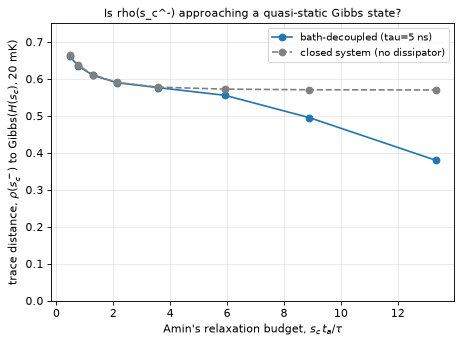

In [72]:
# 16.8: quasi-staticity of rho(s_c^-) -- trace distance to Gibbs(H(s_c), 20 mK), bath-decoupled vs closed system,
# against Amin's relaxation budget s_c*t_a/tau.
q168 = pd.read_csv(RES_DIR / "stage2_quasistaticity_log.csv").sort_values("t_a_ns")
print("S_C=0.459731, tau=5 ns (ring, J=1x)\n")
print(q168[["t_a_ns", "t_c_ns", "budget", "trace_dist_bath", "trace_dist_closed"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(q168.budget, q168.trace_dist_bath, "o-", color="tab:blue", label="bath-decoupled (tau=5 ns)")
ax.plot(q168.budget, q168.trace_dist_closed, "o--", color="0.5", label="closed system (no dissipator)")
ax.set_xlabel("Amin's relaxation budget, $s_c\\,t_a/\\tau$")
ax.set_ylabel("trace distance, $\\rho(s_c^-)$ to Gibbs$(H(s_c), 20$ mK$)$")
ax.set_title("Is rho(s_c^-) approaching a quasi-static Gibbs state?", fontsize=10)
ax.set_ylim(0, 0.75)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.show()

**The trend is right, but quasi-staticity is not reached.** Trace distance to Gibbs falls monotonically with the relaxation budget, from 0.66 (budget 0.46) to 0.38 (budget 13.3) -- a genuine, monotone approach, exactly the direction Amin's picture predicts, and the two curves are indistinguishable below budget $\approx2$ (the bath simply hasn't had time to do anything by $s_c$ yet) and clearly diverge above budget $\approx6$ (the closed system stays essentially flat at 0.57-0.66; only the bath-decoupled state keeps improving). But **0.38 is still a long way from 0** (the maximum possible trace distance between two states is 1) -- even the longest anneal tested (145 ns) does not reach the small-$Q$, quasi-static regime Amin's freeze-out requires. This is consistent with what Marshall, Rieffel & Hen found on real hardware: most instances they measured do *not* satisfy quasi-staticity either. **"Bath-decoupling point" remains the right name for $s_c$ here** -- the mechanism is moving in the freeze-out direction as the anneal gets longer, but has not gotten there within this range of $t_a$.

**Splitting the trace distance into populations and coherences separates two different questions.** In $H(s_c)$'s own eigenbasis (where Gibbs is exactly diagonal), the diagonal (population) and off-diagonal (coherence) parts of $\rho(s_c^-)-\text{Gibbs}(H(s_c))$ answer "has it thermalized" and "how much quantum coherence is left" separately (`check_quasistaticity.py`, same 8 anneals):

In [75]:
# 16.8: population TV distance (diagonal, H(s_c)'s own eigenbasis) vs coherence l1-norm (off-diagonal, same basis).
q168b = pd.read_csv(RES_DIR / "stage2_quasistaticity_log.csv").sort_values("t_a_ns")
print(q168b[["t_a_ns", "budget", "pop_tv_bath", "coherence_l1_bath"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

  t_a_ns  budget  pop_tv_bath  coherence_l1_bath
  5.0000  0.4597       0.5133             1.1005
  8.3380  0.7666       0.5134             0.8380
 13.9040  1.2784       0.5144             0.6150
 23.1870  2.1320       0.5350             0.4195
 38.6660  3.5552       0.5551             0.2598
 64.4790  5.9286       0.5482             0.1489
 96.7180  8.8929       0.4921             0.0918
145.0770 13.3393       0.3785             0.0541


Coherences collapse fast and monotonically (1.10 at budget 0.46 down to 0.05 at budget 13.3 -- almost two orders of magnitude, consistent with the bath simply damping off-diagonal terms), while the *populations* stay essentially flat, 0.51-0.55, over most of the budget range (0.46 to 5.9) and only start moving toward the Gibbs weights at the two largest budgets (0.49 at 8.9, 0.38 at 13.3). So most of the early drop in the overall trace distance is decoherence, not thermalization; only in the longest anneals does the population itself begin to resemble a Boltzmann distribution of $H(s_c)$ -- and it is precisely over that same late range that the log-slope problem below shows up.

**A second signature: the logarithmic slope of $P_{GS}$ in the floor.** Amin's picture predicts $P_0(t_a)\sim(\kappa/\alpha)\ln(\gamma_0 t_a)$ -- a weak, logarithmic dependence on anneal time in the floor regime; Marshall, Rieffel & Hen measure it directly and find under 1% variability across their anneal-time range. The same comparison here, ring $J$=1x, $t_a=$ 38.7-145 ns (no new simulation: the model curve is $\tau=5$ ns's own row of the tau sweep above), fitting $P_{GS}$ against $\ln t_a$ over those four points:

In [73]:
# 16.8: log-slope of P_GS in the floor (38.7-145 ns), model (step at s_c, tau=5 ns) vs the 3 hardware series vs
# the closed system -- Amin's second freeze-out signature (Marshall, Rieffel & Hen measure the same quantity).
gtau = d168b[(d168b.config == "step_sc") & (d168b.topology == "ring") & np.isclose(d168b.tau_ns, 5.0)].sort_values("t_a_ns")
floor = gtau.t_a_ns.values >= 38.0
slope_model = np.polyfit(np.log(gtau.t_a_ns.values[floor]), gtau.p_gs.values[floor], 1)[0]
print(f"model (step at s_c, tau=5 ns): P_GS at floor = {np.round(gtau.p_gs.values[floor], 4)}")
print(f"  slope dP_GS/d(ln t_a) = {slope_model:+.4f}\n")

hw_slopes = []
for name, s in series168.items():
    mask = s.t_anneal_ns.values >= 38.0
    slope = np.polyfit(np.log(s.t_anneal_ns.values[mask]), s.p_hw.values[mask], 1)[0]
    hw_slopes.append(slope)
    print(f"hardware, {name}: P_GS = {np.round(s.p_hw.values[mask], 5)}  slope = {slope:+.4f}")
mean_hw_slope = np.mean(hw_slopes)
o = series168["original"]
mask = o.t_anneal_ns.values >= 38.0
slope_cl = np.polyfit(np.log(o.t_anneal_ns.values[mask]), o.p_unitary.values[mask], 1)[0]
print(f"closed system: slope = {slope_cl:+.4f}")
print(f"\nmean hardware slope: {mean_hw_slope:+.4f}   model/hardware ratio: {slope_model / mean_hw_slope:.1f}x")
print(f"P_GS range over the floor: hardware {100*(o.p_hw.values[mask].max()-o.p_hw.values[mask].min()):.1f}%   "
      f"model {100*(gtau.p_gs.values[floor].max()-gtau.p_gs.values[floor].min()):.1f}%   "
      f"(Marshall, Rieffel & Hen report <1% for their instances)")

model (step at s_c, tau=5 ns): P_GS at floor = [0.9983 0.9911 0.9632 0.9119]
  slope dP_GS/d(ln t_a) = -0.0642

hardware, original: P_GS = [0.9912 0.993  0.9922 0.9872]  slope = -0.0027
hardware, extended J<0: P_GS = [0.99   0.9904 0.9864 0.9818]  slope = -0.0064
hardware, extended J>0: P_GS = [0.9914 0.9918 0.9874 0.9796]  slope = -0.0088
closed system: slope = +0.0006

mean hardware slope: -0.0060   model/hardware ratio: 10.8x
P_GS range over the floor: hardware 0.6%   model 8.6%   (Marshall, Rieffel & Hen report <1% for their instances)


In [76]:
# 16.8: is the excess log-slope caused by the pre-s_c bath or the post-s_c unitary tail? A 2x2 swap of entry state
# (rho(s_c^-) from a short/long anneal) x tail speed (check_slope_mechanism.py).
swap = pd.read_csv(RES_DIR / "stage2_slope_mechanism_log.csv")
print(swap.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
a = swap[(swap.ta_entry == 38.666) & (swap.ta_tail == 38.666)].p_gs.iloc[0]
b = swap[(swap.ta_entry == 38.666) & (swap.ta_tail == 145.077)].p_gs.iloc[0]
c_ = swap[(swap.ta_entry == 145.077) & (swap.ta_tail == 38.666)].p_gs.iloc[0]
d = swap[(swap.ta_entry == 145.077) & (swap.ta_tail == 145.077)].p_gs.iloc[0]
print(f"\ntotal drop (a)-(d) = {a - d:+.4f}")
print(f"entry-only effect (a)-(c), fixed short tail = {a - c_:+.4f}  ({100*(a-c_)/(a-d):.0f}% of total)")
print(f"tail-only effect  (a)-(b), fixed short entry = {a - b:+.4f}  ({100*(a-b)/(a-d):.0f}% of total)")

 ta_entry  ta_tail   p_gs
  38.6660  38.6660 0.9983
  38.6660 145.0770 0.9917
 145.0770  38.6660 0.9044
 145.0770 145.0770 0.9119

total drop (a)-(d) = +0.0864
entry-only effect (a)-(c), fixed short tail = +0.0939  (109% of total)
tail-only effect  (a)-(b), fixed short entry = +0.0066  (8% of total)


**The model's floor falls about 11x too fast with $t_a$ -- and it is the pre-$s_c$ bath, not the post-switch tail, that is responsible.** The hardware's own logarithmic slope (mean $-0.006$, range 1.2% over the floor) is the same order of magnitude Marshall, Rieffel & Hen report for real annealers (under 1%) -- the weak-$\ln t_a$ signature is present in our hardware too, as expected. The model's slope ($-0.064$, range 8.6%) is about 11x steeper.

16.5 originally guessed this was the *post-switch unitary tail* (a slower sweep from $s_c$ to $s=1$ being more adiabatic). That guess predicts the wrong sign: a more adiabatic tail should produce *fewer* excitations and a *higher* $P_{GS}$ at longer $t_a$ -- a positive slope -- but both the model's and the hardware's slopes are negative. The 2x2 swap above settles it directly: fixing the tail speed and swapping only the entry state accounts for **109%** of the real drop in $P_{GS}$; fixing the entry state and swapping only the tail speed accounts for **8%**, and in the *same* direction, not opposing (consistent with the population/coherence finding above, not with a simple tail-adiabaticity argument).

So the excess slope is a property of the **bath before $s_c$**, not of what happens after it: more anneal time means a larger relaxation budget, which (the trace-distance and population/coherence results just above) pulls $\rho(s_c^-)$ further from a low-entropy, mostly-coherent state and closer to $\text{Gibbs}(H(s_c))$ -- a state with real weight on the near-degenerate excited levels ($Q(s_c)=0.21$, not classical). That pull grows with the budget $s_c\,t_a/\tau$, which is exactly why $P_{GS}$ keeps falling well past where the hardware's floor has gone flat. The fix this points to is not a better description of the tail, but a relaxation rate that does not keep pulling the pre-crossing state further from equilibrium as $t_a$ grows without bound -- e.g. a rate tied to the instantaneous gap rather than a constant $\tau$ -- untested here.

**Summary of the four checks, in the order run:**

| # | Check | Result |
|---|---|---|
| 1 | Generalize $s_c$ to $J$=1.75x, 0 free parameters | Confirmed: 2.4-2.9x error, both topologies, both signs -- against 108-229x closed |
| 2 | Quasi-staticity of $\rho(s_c^-)$ | Right trend (trace distance to Gibbs falls monotonically with the relaxation budget), not reached within these $t_a$ |
| 3 | Log-slope of $P_{GS}$ in the floor | Wrong by $\sim$11x -- caused by the pre-$s_c$ bath (109% of the effect), not the post-switch tail (8%) |
| -- | Switch width | Not resolved (delta keeps improving down to 0.001; treated as a step) |

The center at $s_c$ is the part of this model with the most support: it needs no fitting, moves correctly with $|J|$, and (1) confirms it. What is fitted -- $\tau$, and *how* it is fitted (a constant rate, rather than one tied to the gap or the schedule) -- is where (2) and (3) both point: the pre-crossing bath, not anything after the switch, is the real remaining gap.

## Next steps

- ~~Push past 2 qubits~~ -- done: `seaqt/local_seaqt_n.py` generalizes
  `local_seaqt_dissipator` to N qubits (section 12), cross-checked
  bit-for-bit against the 2-qubit version at n=2. What's still open:
  whether the "safe `tau`" threshold's growth with qubit count (section 12)
  follows any predictable pattern (with the corrected units and the warm bath it is
  mild at 3-4 qubits; at the physical 15 mK bath it is severe -- sections 9-10). The
  per-RHS costs that used to dominate runtime -- rebuilding the Hamiltonian at every
  timestep and `evolve()`'s pure-Python `_pack`/`_unpack` loops -- were removed with
  the units fix (`hamiltonian_nqubit` precomputes its operators, `evolve` works on the
  complex matrix directly: ~20x faster for unitary evolution, ~6x with the bath dissipator).
- Explore state- or schedule-dependent $\tau(\rho, t)$ rather than a
  constant relaxation time.
- ~~Push past a linear chain~~ -- done: section 14 simulates a 6-qubit
  antiferromagnetic ring (D-Wave's native loop connectivity), the
  largest ring size where a sweep of dozens of `evolve()` calls still
  finishes in reasonable time. Two Néel ground states at 49.9% each
  (99.8% combined), exactly 2-fold ground / 4-fold first-excited
  degeneracy from the ring's symmetry.
- ~~Validate against a known closed-form result~~ -- done: section 15
  compares our schedule-driven unitary evolution of the ring against
  King et al. 2022's zero-fit-parameter Landau-Zener prediction
  (arXiv:2202.05847v2, Eq. 8) -- 0.7% agreement on the decay exponent,
  and shows where our relaxation dissipator visibly departs from the
  ideal coherent curve (t_a >~ 2-4 ns for the tau=15 ns, 94 mK bath used there;
  the agreement is an integration check and, being a ratio of two quantities
  carrying the same 2*pi, cannot detect a missing 2*pi). The ICE-noise Monte Carlo
  version of section 15 (40 trials, ~36% each Neel state, skew
  std=0.0365) was removed from the notebook for now but its data is
  preserved (not lost) outside the repo, in case it's needed again.
- ~~Compare against real D-Wave hardware results~~ -- done: section 16 runs
  the actual Landau-Zener crossover experiment on a real Advantage2 QPU
  (JUPSI, `Advantage2_system1`, fast-anneal protocol; ring and chain on
  identical physical qubits, then 35 topologies in 16.3-16.4). With the units
  corrected (H_ang = 2*pi*H_GHz, see the note at the top), real hardware
  reaches the ground state ~2x more slowly than the closed-system LZ formula
  (a_emp/a_theory = 0.27-0.60) and than the exact 6-qubit closed simulation
  (0.35-0.70); SEAQT-unitary reproduces the analytic formula on the ring to
  ~2% (16.1); across all 215 (topology, J, sign) combos it predicts the
  8000-read hardware P_GS, on the 115 combos where the closed system is not
  saturated, with median RMS 0.016, the hardware below it in 81% of their points
  and above in 0.7% (16.4). What's still open: (a) Stage 2 was redone in the
  corrected units with relaxation to an external bath on the full 64x64 rho (20 mK,
  positive-definite initial perturbation): no tau improves on the unitary limit
  (`calibrate_tau_bath.py`) -- until the relaxation is allowed to freeze out. Section 16.5 redoes it
  with a positivity-preserving integrator (positivity was an integrator artifact, not a property of
  the bath equation) and a bath switched off after a freeze-out point: tau = 7 ns, s_f = 0.45,
  T = 20 mK (fitted on the ring, J=1x) predict the hardware's late-time floor to ~1 decade instead
  of ~5 across the 215 combos, but not the coherent-regime gap, where the hardware stays above the
  closed system. Section 16.6 checked the freeze-out point's sign: reversing it (bath active through/
  after the crossing, the textbook picture) is decisively worse than no dissipator at all, and an
  independent calibration on the chain lands at essentially the same (tau, s_f) as the ring -- so the
  fitted direction is real and reproducible, but *why* the cutoff sits before the crossing rather than
  after it is still unexplained. What's still open: (a) the coherent-regime gap (an effective time
  mapping or temperature, tau(s), per-qubit/coupler control errors); (b) a tau(s) that grows smoothly
  near s_c from both sides instead of switching sharply, closer to the textbook freeze-out picture;
  (c) a decoherent null model, to turn "consistent with coherent evolution" into a quantitative statement.
